# Ruta 16


<div style="border-bottom:4px solid #63358A;padding:16px 0;background:white">
<h1 style="color:#63358A"><strong>Analísis Ruta 16</strong></h1>
</div>

## **1. Instalación y configuración privada**

### **4.1. Entorno**

Dependencias comprobadas antes de conectar o escribir datos. Si faltan, instalar en el kernel elegido: `%pip install pandas numpy pyarrow sqlalchemy "psycopg[binary]" python-dotenv nbformat nbclient ipykernel`. No existe sustitución automática por CSV.

In [1]:
import os, sys, json, hashlib, uuid, html, platform, time, re, ast
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from contextlib import contextmanager
from decimal import Decimal
from importlib.metadata import version
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
from sqlalchemy import create_engine, text, URL
from dotenv import load_dotenv
from IPython.display import display, HTML, Markdown
import psycopg

# Dependencias opcionales instaladas localmente por el equipo deben estar en el kernel.
PAQUETES = ['pandas','numpy','pyarrow','SQLAlchemy','psycopg','python-dotenv','nbformat','nbclient','ipykernel']
DEPENDENCIAS = {p: version(p) for p in PAQUETES}
print('Python', platform.python_version(), '· Parquet disponible · dependencias comprobadas')
MORADO_CLARO, MORADO_OSCURO = '#D8C4EB', '#63358A'
def mostrar(df, n=12):
    vista = df.head(n).copy()
    formato = {c: (lambda x: '—' if pd.isna(x) else f'{x:,.2f}')
               for c in vista.select_dtypes(include='number')}
    for c in vista.select_dtypes(include='integer'):
        formato[c] = lambda x: '—' if pd.isna(x) else f'{int(x):,}'
    display(vista.style.hide(axis='index').format(formato, na_rep='—').set_table_styles([
        {'selector':'th','props':[('background-color',MORADO_OSCURO),('color','white'),('padding','8px')]},
        {'selector':'td','props':[('background-color','white'),('border-bottom','1px solid #D8C4EB'),('padding','7px')]},
        {'selector':'table','props':[('border-collapse','collapse')]}]))
    if len(df)>n: display(Markdown(f'*Vista compacta: {n:,} de {len(df):,} filas; el reporte conserva el detalle completo.*'))
def interpretar(s):
    display(Markdown('**Lectura del resultado.** '+s))

def mostrar_control(df, columnas_incidencia=(), limite_pequena=40):
    if len(df)<=limite_pequena:
        mostrar(df,n=len(df))
        return
    if 'estado' not in df: raise ValueError('El control extenso debe tener estado explícito.')
    mostrar(df.groupby('estado',dropna=False).size().rename('comprobaciones').reset_index(),n=df.estado.nunique(dropna=False))
    pendientes=~df.estado.astype('string').isin(['evaluado','única y presente','sin incidencias en control'])
    for c in columnas_incidencia:
        if c in df: pendientes |= pd.to_numeric(df[c],errors='coerce').gt(0).fillna(False)
    detalle=df.loc[pendientes]
    if len(detalle): mostrar(detalle,n=len(detalle))
    else: interpretar('El resumen por estado no oculta incidencias o casos pendientes; el detalle completo está exportado.')


Python 3.14.6 · Parquet disponible · dependencias comprobadas


### **4.2. Configuración y credenciales**

La ventana usa `fechasalida`, sin filtros de estado ni conteo. La zona de sesión es America/Bogota; los timestamps SQL sin zona se conservan sin zona. Su lectura como hora local es una convención de trabajo pendiente de confirmar con el productor.

In [2]:
# Carpeta que contiene el notebook, herramientas/ y salidas_ruta16/.
PROYECTO = Path.cwd().resolve()  # Puede sustituirse por una ruta absoluta explícita.
MODALIDAD = 'local'  # 'extraccion' solo para una nueva extracción explícita.
EJECUCION_LOCAL = Path('salidas_ruta16/20261012T224023_6ecc8784')
if MODALIDAD not in {'local','extraccion'}: raise ValueError('MODALIDAD debe ser local o extraccion.')
DOCUMENTACION_PATH = PROYECTO/'herramientas/ruta16/documentacion_fuentes.json'
if not DOCUMENTACION_PATH.is_file():
    raise FileNotFoundError(f'Falta documentación necesaria: {DOCUMENTACION_PATH}')
# Validar JSON antes de crear una ejecución o consultar la base.
json.loads(DOCUMENTACION_PATH.read_text(encoding='utf-8'))
CFG = dict(id_ruta=16, proceso='sobusa', schema='public', inicio='2023-01-01',
           fin_exclusivo='2026-01-01', zona='America/Bogota', lote=10000, timeout_ms=120000)
if MODALIDAD == 'local':
    BASE = PROYECTO/EJECUCION_LOCAL
    necesarios = ['configuracion.json','fuentes.json','reportes/registro.json',
        'reportes/esquema.csv','reportes/inventario.csv','reportes/llaves.csv',
        'reportes/indices.csv','reportes/confirmacion_ruta.csv',
        'reportes/cobertura_fuera_ventana.csv','reportes/contexto_segmentos_referenciados.csv',
        'reportes/verificacion_escritura.csv']
    faltan = [str(BASE/f) for f in necesarios if not (BASE/f).is_file()]
    if faltan: raise FileNotFoundError('Faltan archivos de la extracción local: '+', '.join(faltan))
    fuentes_locales = json.loads((BASE/'fuentes.json').read_text())
    for tabla,relativa in fuentes_locales.items():
        carpeta=(BASE/relativa).resolve()
        if not carpeta.is_relative_to(BASE.resolve()) or not list(carpeta.glob('*.parquet')):
            raise FileNotFoundError(f'Faltan partes Parquet de {tabla}: {carpeta}')
    cfg_guardada=json.loads((BASE/'configuracion.json').read_text())
    for k in ['id_ruta','proceso','inicio','fin_exclusivo','zona']:
        if cfg_guardada[k]!=CFG[k]: raise ValueError('El alcance local no corresponde a CFG: '+k)
    CFG=cfg_guardada; RUN_ID=BASE.name
else:
    ENV_PATH=PROYECTO/'.env'
    if not ENV_PATH.is_file(): raise FileNotFoundError(f'Falta configuración privada: {ENV_PATH}')
    load_dotenv(ENV_PATH, override=False)
    faltan = [k for k in ['DB_HOST','DB_NAME','DB_USER','DB_PASSWORD'] if not os.getenv(k)]
    if faltan: raise RuntimeError('Faltan variables privadas: '+', '.join(faltan))
    RUN_ID = datetime.now(ZoneInfo(CFG['zona'])).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
    BASE=PROYECTO/'salidas_ruta16'/RUN_ID
    for d in ['raw','preparadas','reportes','sql']: (BASE/d).mkdir(parents=True,exist_ok=False)
REPORTES=BASE/'reportes'
def json_guardar(path,obj):
    tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8');tmp.replace(path)
def reporte(nombre,df):
    df.to_csv(REPORTES/(nombre+'.csv'),index=False,encoding='utf-8-sig')
    return df
if MODALIDAD == 'extraccion': json_guardar(BASE/'configuracion.json',CFG)
json_guardar(BASE/('dependencias_revision_local.json' if MODALIDAD=='local' else 'dependencias.json'),DEPENDENCIAS)
RAW, REGISTRO, VERIFICACION_ESCRITURA = {}, [], []
print('Ejecución:',RUN_ID,'· Salidas:',BASE)
interpretar('Se reutiliza la ejecución entregada sin consultas a la base.' if MODALIDAD=='local' else 'Se crea una carpeta nueva de ruta 16.')

Ejecución: 20261012T224023_6ecc8784 · Salidas: /Users/leoporojano/Documents/Data Challenge/salidas_ruta16/20261012T224023_6ecc8784


**Lectura del resultado.** Se reutiliza la ejecución entregada sin consultas a la base.

### **4.3. Conexión y transacciones breves**

Credenciales manejadas con `URL.create`. Cada contexto cierra su transacción. Los mensajes de error se limitan al tipo y SQLSTATE para evitar exponer la configuración privada.

In [3]:
engine = None
if MODALIDAD == 'extraccion':
    engine = create_engine(URL.create('postgresql+psycopg',username=os.environ['DB_USER'],
        password=os.environ['DB_PASSWORD'],host=os.environ['DB_HOST'],port=int(os.getenv('DB_PORT','5432')),
        database=os.environ['DB_NAME']),pool_pre_ping=True,
        connect_args={'connect_timeout':15,'sslmode':os.getenv('DB_SSLMODE','require'),'application_name':'sobusa_ruta16_etl'})
@contextmanager
def lectura():
    if MODALIDAD != 'extraccion': raise RuntimeError('Revisión local: las consultas PostgreSQL están deshabilitadas.')
    try:
        with engine.connect().execution_options(isolation_level='REPEATABLE READ') as conn:
            with conn.begin():
                conn.execute(text('SET TRANSACTION READ ONLY'))
                for clave,valor in [('statement_timeout',str(CFG['timeout_ms'])),('lock_timeout','5000'),('TimeZone',CFG['zona'])]:
                    conn.execute(text('SELECT set_config(:k,:v,true)'),{'k':clave,'v':valor})
                yield conn
    except Exception as exc:
        codigo=getattr(getattr(exc,'orig',None),'sqlstate',None)
        raise RuntimeError(f'Bloque de lectura fallido: {type(exc).__name__}; SQLSTATE={codigo}. Revisar el entorno privado.') from None
def pequena(nombre,sql,params=None,conn=None):
    (BASE/'sql'/(nombre+'.sql')).write_text(sql,encoding='utf-8')
    if conn is None:
        with lectura() as c:return pequena(nombre,sql,params,c)
    conn.execution_options(stream_results=False)
    with conn.execute(text(sql),params or {}) as r:
        rows=r.fetchmany(20001)
        if len(rows)>20000:raise ValueError('Consulta pequeña excede el límite')
        return pd.DataFrame(rows,columns=r.keys())
if MODALIDAD == 'extraccion':
    with lectura() as c:
        prueba=pequena('prueba',"SELECT current_setting('transaction_read_only') AS solo_lectura,current_setting('TimeZone') AS zona",conn=c)
    assert prueba.solo_lectura.eq('on').all()
    mostrar(prueba)
    interpretar('La conexión fue comprobada en solo lectura y con la zona de sesión declarada.')
else:
    interpretar('Modo local: no se crea motor ni se prueba conexión. El registro conserva la evidencia de solo lectura de la extracción original.')

**Lectura del resultado.** Modo local: no se crea motor ni se prueba conexión. El registro conserva la evidencia de solo lectura de la extracción original.

### **4.4. Inventario real: consultas pequeñas**

Se consulta esquema y restricciones; el inventario general usa estadísticas aproximadas, sin contar tablas masivas. Los metadatos PostGIS se excluyen del inventario analítico. Se confirma el nombre desde el catálogo.

In [4]:
if MODALIDAD == 'extraccion':
    TECNICOS = {'spatial_ref_sys','geometry_columns','geography_columns','raster_columns','raster_overviews'}
    with lectura() as c:
        ESQUEMA=pequena('esquema',"""SELECT table_name AS tabla,column_name AS columna,data_type,udt_name,
            is_nullable,ordinal_position,numeric_precision,numeric_scale FROM information_schema.columns
            WHERE table_schema=:s ORDER BY table_name,ordinal_position""",{'s':CFG['schema']},c)
        INVENTARIO=pequena('inventario',"""SELECT relname AS tabla,n_live_tup AS filas_aproximadas,
            pg_total_relation_size(relid) AS bytes_total,last_analyze,last_autoanalyze
            FROM pg_stat_user_tables WHERE schemaname=:s ORDER BY relname""",{'s':CFG['schema']},c)
        LLAVES=pequena('llaves',"""SELECT c.relname AS tabla,con.conname AS constraint_name,
            CASE con.contype WHEN 'p' THEN 'PRIMARY KEY' WHEN 'u' THEN 'UNIQUE' WHEN 'f' THEN 'FOREIGN KEY'
              WHEN 'c' THEN 'CHECK' END AS constraint_type,a.attname AS column_name,k.orden AS ordinal_position,
            pg_get_constraintdef(con.oid,true) AS definicion
            FROM pg_constraint con JOIN pg_class c ON c.oid=con.conrelid
            JOIN pg_namespace n ON n.oid=c.relnamespace
            LEFT JOIN LATERAL unnest(con.conkey) WITH ORDINALITY AS k(attnum,orden) ON true
            LEFT JOIN pg_attribute a ON a.attrelid=c.oid AND a.attnum=k.attnum
            WHERE n.nspname=:s ORDER BY c.relname,con.conname,k.orden""",{'s':CFG['schema']},c)
        INDICES=pequena('indices','SELECT tablename AS tabla,indexname,indexdef FROM pg_indexes WHERE schemaname=:s',{'s':CFG['schema']},c)
        RUTA_CATALOGO=pequena('confirmacion_ruta','SELECT idruta,nombre,proceso FROM public.rutas WHERE idruta=:ruta',{'ruta':16},c)
    assert len(RUTA_CATALOGO)==1 and RUTA_CATALOGO.iloc[0].proceso==CFG['proceso'], 'Confirmación de ruta/proceso fallida'
    NOMBRE_RUTA=RUTA_CATALOGO.iloc[0]['nombre'];CFG['nombre_ruta']=NOMBRE_RUTA
    json_guardar(BASE/'configuracion.json',CFG)
    for nombre,df in [('esquema',ESQUEMA),('inventario',INVENTARIO),('llaves',LLAVES),('indices',INDICES),('confirmacion_ruta',RUTA_CATALOGO)]:reporte(nombre,df.loc[~df.get('tabla',pd.Series(index=df.index,dtype=str)).isin(TECNICOS)] if 'tabla' in df else df)
    COLS={t:set(g.columna) for t,g in ESQUEMA.groupby('tabla')}
    mostrar(RUTA_CATALOGO)
    interpretar(f'El catálogo identifica la ruta {CFG["id_ruta"]} como **{NOMBRE_RUTA}**, proceso **{CFG["proceso"]}**. Los totales históricos no se usan como controles fijos.')
else:
    ESQUEMA=pd.read_csv(REPORTES/'esquema.csv')
    INVENTARIO=pd.read_csv(REPORTES/'inventario.csv');LLAVES=pd.read_csv(REPORTES/'llaves.csv')
    INDICES=pd.read_csv(REPORTES/'indices.csv');RUTA_CATALOGO=pd.read_csv(REPORTES/'confirmacion_ruta.csv')
    COLS={t:set(g.columna) for t,g in ESQUEMA.groupby('tabla')}
    assert len(RUTA_CATALOGO)==1 and RUTA_CATALOGO.iloc[0].idruta==16 and RUTA_CATALOGO.iloc[0].proceso=='sobusa'
    NOMBRE_RUTA=RUTA_CATALOGO.iloc[0]['nombre']
    mostrar(RUTA_CATALOGO)
    interpretar('Se reutilizan catálogo, esquema y restricciones registrados en la extracción, sin consultas nuevas.')


idruta,nombre,proceso
16,CRA 54,sobusa


**Lectura del resultado.** Se reutilizan catálogo, esquema y restricciones registrados en la extracción, sin consultas nuevas.

### **4.5. Extracción a disco: un lote a la vez**

La escritura es exclusivamente Parquet. Se reconstruye el tipo Arrow desde el esquema SQL, conservando enteros anulables, decimales, fechas y horas. Geometría es una representación textual EWKB, documentada. Cada lote se relee y compara antes de publicarse. Los conteos fuente y extracción se obtienen en la misma transacción por tabla.

In [5]:
def qident(s):return '"'+s.replace('"','""')+'"'
def qtable(t):return qident(CFG['schema'])+'.'+qident(t)
TIPOS_ARROW={'int2':pa.int16(),'int4':pa.int32(),'int8':pa.int64(),'float4':pa.float32(),
    'float8':pa.float64(),'bool':pa.bool_(),'date':pa.date32(),'time':pa.time64('us'),
    'timestamp':pa.timestamp('us'),'timestamptz':pa.timestamp('us',tz=CFG['zona']),
    'text':pa.string(),'varchar':pa.string(),'bpchar':pa.string(),'geometry':pa.string(),'geography':pa.string(),'potencial_efecto':pa.string()}
def tipo_arrow(meta):
    if meta.udt_name=='numeric':
        p,s=meta.numeric_precision,meta.numeric_scale
        if pd.notna(p) and pd.notna(s):
            p,s=int(p),int(s)
            if not (0<=s<=p<=76):raise TypeError('Decimal SQL requiere contrato específico')
            return pa.decimal128(p,s) if p<=38 else pa.decimal256(p,s)
        return None  # Se infiere de Decimal, nunca float.
    if meta.udt_name not in TIPOS_ARROW:raise TypeError('Tipo SQL no contratado: '+meta.udt_name)
    return TIPOS_ARROW[meta.udt_name]
def lote_arrow(rows,tabla,campos):
    meta=ESQUEMA.loc[ESQUEMA.tabla.eq(tabla)].set_index('columna');arrays=[]
    for col in campos:
        valores=[r[col] for r in rows];tipo=tipo_arrow(meta.loc[col])
        if meta.loc[col,'udt_name']=='numeric' and any(v is not None and not isinstance(v,Decimal) for v in valores):
            raise TypeError('Numeric recibido sin precisión Decimal')
        arrays.append(pa.array(valores,type=tipo,safe=True))
    return pa.Table.from_arrays(arrays,names=campos)
def verificar_parquet(path,tabla_arrow):
    releida=pq.read_table(path)
    if not tabla_arrow.equals(releida):raise AssertionError('Escritura/relectura no conserva valores, tipos o faltantes')
    return {'archivo':str(path.relative_to(BASE)),'filas':releida.num_rows,'columnas':releida.num_columns,
            'tipos_iguales':releida.schema.equals(tabla_arrow.schema),'faltantes_iguales':all(a.null_count==b.null_count for a,b in zip(tabla_arrow.columns,releida.columns))}
def extraer(tabla,where,params,campos):
    if not set(campos)<=COLS.get(tabla,set()):raise ValueError('Faltan columnas requeridas de '+tabla)
    meta=ESQUEMA.loc[ESQUEMA.tabla.eq(tabla)].set_index('columna')
    sel=', '.join(qident(c)+('::text AS '+qident(c) if meta.loc[c,'udt_name'] in {'geometry','geography'} else '') for c in campos)
    sql=f'SELECT {sel} FROM {qtable(tabla)} WHERE {where}'
    (BASE/'sql'/(tabla+'.sql')).write_text(sql,encoding='utf-8')
    temporal=BASE/'raw'/(tabla+'.incompleta');temporal.mkdir()
    registro={'fuente':tabla,'inicio':datetime.now(ZoneInfo(CFG['zona'])).isoformat(),
              'filtro':where,'parametros':params,'sql_sha256':hashlib.sha256(sql.encode()).hexdigest()}
    n=0;inicio=time.perf_counter();schemas=[]
    try:
        with lectura() as c:
            esperado=int(c.execute(text(f'SELECT COUNT(*) FROM {qtable(tabla)} WHERE {where}'),params).scalar_one())
            c.execution_options(stream_results=True)
            with c.execute(text(sql),params) as resultado:
                for i,rows in enumerate(resultado.mappings().partitions(CFG['lote'])):
                    arr=lote_arrow(rows,tabla,campos);path=temporal/f'parte-{i:05d}.parquet'
                    pq.write_table(arr,path,compression='zstd');verificar_parquet(path,arr)
                    schemas.append(arr.schema);n+=arr.num_rows
            c.execution_options(stream_results=False)
        if not schemas:
            arr=lote_arrow([],tabla,campos);pq.write_table(arr,temporal/'parte-00000.parquet');schemas=[arr.schema]
        comun=pa.unify_schemas(schemas,promote_options='permissive')
        for path in sorted(temporal.glob('*.parquet')):
            pf=pq.ParquetFile(path)
            if not pf.schema_arrow.equals(comun):
                tmp=path.with_suffix('.tmp')
                with pq.ParquetWriter(tmp,comun,compression='zstd') as w:
                    for b in pf.iter_batches(batch_size=CFG['lote']):w.write_table(pa.Table.from_batches([b]).cast(comun,safe=True))
                esperadas=pq.read_table(path).cast(comun,safe=True)
                verificar_parquet(tmp,esperadas)
                pf.close();tmp.replace(path)
        assert n==esperado, 'Conciliación fuente/extracción fallida'
        destino=BASE/'raw'/tabla;temporal.replace(destino);RAW[tabla]=destino
        for path in sorted(destino.glob('*.parquet')):
            arr=pq.read_table(path);VERIFICACION_ESCRITURA.append(verificar_parquet(path,arr))
        registro.update(estado='extraida' if n else 'vacia_en_filtro',filas=n,filas_fuente_snapshot=esperado,
                        columnas=len(campos),partes=len(list(destino.glob('*.parquet'))),esquema=str(comun))
    except Exception as exc:
        registro.update(estado='fallida',filas=None,error=type(exc).__name__)
        REGISTRO.append(registro);json_guardar(REPORTES/'registro.json',REGISTRO)
        raise RuntimeError('Extracción detenida en '+tabla+'; revisar registro privado. '+type(exc).__name__) from None
    registro.update(fin=datetime.now(ZoneInfo(CFG['zona'])).isoformat(),segundos=time.perf_counter()-inicio)
    REGISTRO.append(registro);json_guardar(REPORTES/'registro.json',REGISTRO)
    print(f'{tabla}: {n:,} filas',flush=True)

### **4.6. Fuentes y filtros**

Programaciones: ruta 16, proceso cuando existe, ventana por salida. Vehículos: referencias históricas de esas programaciones. Detalle: relación con la programación; no se filtra por segmento ni fecha propia para esconder discrepancias. Anuales: ruta/proceso, todos los años preservados; 2026 se separa después. Consolidado: ruta/proceso y período no confirmado. Calendarios compartidos completos para auditar referencias ajenas. Se omiten eventos de sensores y porciones masivas.

In [6]:
PARAMS={'ruta':16,'proceso':'sobusa','inicio':CFG['inicio'],'fin':CFG['fin_exclusivo']}
viajes_where='"idruta"=:ruta AND "fechasalida">=CAST(:inicio AS timestamp) AND "fechasalida"<CAST(:fin AS timestamp)'
if 'proceso' in COLS['progvehiculos']:viajes_where+=' AND "proceso"=:proceso'
viajes_ids=f'SELECT "idprogramacion" FROM {qtable("progvehiculos")} WHERE {viajes_where}'
def ruta_filtro(t,c):return qident(c)+'=:ruta'+(' AND "proceso"=:proceso' if 'proceso' in COLS[t] else '')
FILTROS={'progvehiculos':viajes_where,
    'vehiculos':f'"idvehiculo" IN (SELECT "idvehiculo" FROM {qtable("progvehiculos")} WHERE {viajes_where})',
    'timbradas_segmentos':f'"id_viaje" IN ({viajes_ids})',
    'rutas':ruta_filtro('rutas','idruta'),'rutas_segmentos':ruta_filtro('rutas_segmentos','idruta'),
    'rutas_segmentos_config':ruta_filtro('rutas_segmentos_config','idruta'),
    'timbradas_anio':ruta_filtro('timbradas_anio','id_ruta'),
    'timbradas_consolidado':ruta_filtro('timbradas_consolidado','id_ruta'),
    'estacionalidades':'TRUE','estacionalidades_anio':'TRUE','dias_semana':'TRUE',
    'Procesos':'"proceso"=:proceso OR "proceso" IN (SELECT "proceso" FROM public.estacionalidades UNION SELECT "proceso" FROM public.estacionalidades_anio)',
    'novedades_viales_ruta':ruta_filtro('novedades_viales_ruta','id_ruta')}
P_COLS=['idprogramacion','idvehiculo','idconductor','idruta','proceso','fechasalida','fecharegistro',
    'fechainicio','fechafin','finalizado','cancelada','observacion','puntoini','ordenpunto','puntofin',
    'ordenpuntofin','iddespachador','tipo','grupo','activa','distancia_recorrida','numeropasajeros',
    'numerobajadas','numerobloqueos','cantidad_subida_puerta1','cantidad_subida_puerta2',
    'cantidad_bajada_puerta1','cantidad_bajada_puerta2','acumulada_subida','acumulada_bajada',
    'torniqueteinicial','torniquetefinal','modificado_manual','timbradas_manuales','excepcion',
    'apto_estadisticas_historicas','recaudo_pasajeros','viaje_culminado']
CAMPOS={t:ESQUEMA.loc[ESQUEMA.tabla.eq(t)].sort_values('ordinal_position').columna.tolist() for t in FILTROS}
CAMPOS['progvehiculos']=[c for c in P_COLS if c in COLS['progvehiculos']]
CAMPOS['vehiculos']=['idvehiculo','placa','marca','idruta','modelo','tipo_carroceria','n_sentados','n_depie','capacidad','estado','fechaingreso']
CAMPOS['Procesos']=[c for c in ['proceso','nombre','id_estacionalidad','id_diasemana'] if c in COLS['Procesos']]
ALCANCES={t:'Ruta 16; filtro específico en SQL' for t in FILTROS}
ALCANCES.update(progvehiculos='Ruta 16/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos',
    vehiculos='Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada',
    timbradas_segmentos='Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan',
    timbradas_anio='Ruta 16/SOBUSA; todos los años conservados, 2026 fuera del principal',
    timbradas_consolidado='Ruta 16/SOBUSA; período de consolidación pendiente de confirmación',
    estacionalidades='Catálogo compartido; todos los procesos para diagnóstico',
    estacionalidades_anio='Vigencias compartidas; todos los procesos y años para diagnóstico',
    dias_semana='Catálogo compartido',Procesos='SOBUSA y procesos referenciados por calendario')
PLAN=pd.DataFrame([{'tabla':t,'alcance':ALCANCES[t],'columnas':len(CAMPOS[t]),'filtro_sql':FILTROS[t]} for t in FILTROS])
if MODALIDAD=='extraccion': reporte('plan_extraccion',PLAN)
mostrar(PLAN[['tabla','alcance','columnas']])
if MODALIDAD == 'extraccion':
    for t,w in FILTROS.items():extraer(t,w,PARAMS,CAMPOS[t])
    # Si hay referencias viales, se descargan solo sus padres, no toda la tabla de ocurrencias.
    if 'novedades_viales_fecha' in COLS:
        FILTROS['novedades_viales_fecha']='"id_novedad_vial_fecha" IN (SELECT "id_novedad_vial_fecha" FROM public.novedades_viales_ruta WHERE "id_ruta"=:ruta)'
        CAMPOS['novedades_viales_fecha']=ESQUEMA.loc[ESQUEMA.tabla.eq('novedades_viales_fecha')].columna.tolist()
        ALCANCES['novedades_viales_fecha']='Padres de novedades asociadas a ruta 16; vigencias conservadas'
        extraer('novedades_viales_fecha',FILTROS['novedades_viales_fecha'],PARAMS,CAMPOS['novedades_viales_fecha'])
    if 'novedades_viales' in COLS:
        FILTROS['novedades_viales']='TRUE';CAMPOS['novedades_viales']=ESQUEMA.loc[ESQUEMA.tabla.eq('novedades_viales')].columna.tolist()
        ALCANCES['novedades_viales']='Catálogo vial compartido'
        extraer('novedades_viales','TRUE',PARAMS,CAMPOS['novedades_viales'])
    PLAN=reporte('plan_extraccion',pd.DataFrame([{'tabla':t,'alcance':ALCANCES[t],'columnas':len(CAMPOS[t]),'filtro_sql':FILTROS[t]} for t in FILTROS]))
else:
    RAW={t:BASE/rel for t,rel in fuentes_locales.items()}
    REGISTRO=json.loads((REPORTES/'registro.json').read_text())
    VERIFICACION_ESCRITURA=pd.read_csv(REPORTES/'verificacion_escritura.csv').to_dict('records')
    PLAN=pd.read_csv(REPORTES/'plan_extraccion.csv')
    for fila in PLAN.to_dict('records'):
        t=fila['tabla'];FILTROS[t]=fila['filtro_sql'];ALCANCES[t]=fila['alcance']
        CAMPOS[t]=pq.read_schema(next(RAW[t].glob('*.parquet'))).names
    mostrar(PLAN[['tabla','alcance','columnas']],n=len(PLAN))
DIFERIDAS=reporte('fuentes_diferidas',pd.DataFrame([
    {'tabla':'conteo_pasajeros_destino','estado':'diferida','motivo':'Tabla masiva; exige necesidad y consulta acotada con plan revisado'},
    {'tabla':'rutas_segmentos_porcion','estado':'diferida','motivo':'Porciones masivas no necesarias para esta preparación'},
    {'tabla':'PostGIS: objetos de metadatos','estado':'excluida','motivo':'Objetos técnicos, no fuentes analíticas'}]))
interpretar('La extracción terminó sin filtros analíticos. Los catálogos compartidos mantienen su alcance explícito; no son resultados operativos exclusivos de la ruta.')

tabla,alcance,columnas
progvehiculos,"Ruta 16/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos",38
vehiculos,"Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada",11
timbradas_segmentos,Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan,10
rutas,Ruta 16; filtro específico en SQL,43
rutas_segmentos,Ruta 16; filtro específico en SQL,9
rutas_segmentos_config,Ruta 16; filtro específico en SQL,10
timbradas_anio,"Ruta 16/SOBUSA; todos los años conservados, 2026 fuera del principal",15
timbradas_consolidado,Ruta 16/SOBUSA; período de consolidación pendiente de confirmación,14
estacionalidades,Catálogo compartido; todos los procesos para diagnóstico,5
estacionalidades_anio,Vigencias compartidas; todos los procesos y años para diagnóstico,6


*Vista compacta: 12 de 13 filas; el reporte conserva el detalle completo.*

tabla,alcance,columnas
progvehiculos,"Ruta 16/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos",38
vehiculos,"Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada",11
timbradas_segmentos,Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan,10
rutas,Ruta 16; filtro específico en SQL,43
rutas_segmentos,Ruta 16; filtro específico en SQL,9
rutas_segmentos_config,Ruta 16; filtro específico en SQL,10
timbradas_anio,"Ruta 16/SOBUSA; todos los años conservados, 2026 fuera del principal",15
timbradas_consolidado,Ruta 16/SOBUSA; período de consolidación pendiente de confirmación,14
estacionalidades,Catálogo compartido; todos los procesos para diagnóstico,5
estacionalidades_anio,Vigencias compartidas; todos los procesos y años para diagnóstico,6


**Lectura del resultado.** La extracción terminó sin filtros analíticos. Los catálogos compartidos mantienen su alcance explícito; no son resultados operativos exclusivos de la ruta.

### **4.7. Cobertura y verificación de archivos**

La conciliación usa la fuente con el mismo filtro y snapshot por tabla. Las salidas ausentes no pertenecen a la ventana, pero se contabilizan fuera de ella. Las referencias de segmentos se contrastan además contra el catálogo completo mediante una consulta de diagnóstico pequeña.

In [7]:
REG_DF=reporte('registro',pd.DataFrame(REGISTRO))
reporte('verificacion_escritura',pd.DataFrame(VERIFICACION_ESCRITURA))
json_guardar(BASE/'fuentes.json',{t:str(p.relative_to(BASE)) for t,p in RAW.items()})
if MODALIDAD == 'extraccion':
    with lectura() as c:
        COBERTURA_RUTA=pequena('cobertura_ruta',"""SELECT COUNT(*) AS programaciones_ruta_proceso,
            COUNT(*) FILTER (WHERE fechasalida IS NULL) AS salida_nula,
            COUNT(*) FILTER (WHERE fechasalida<CAST(:inicio AS timestamp) OR fechasalida>=CAST(:fin AS timestamp)) AS fuera_ventana,
            MIN(fechasalida) AS primera_salida,MAX(fechasalida) AS ultima_salida
            FROM public.progvehiculos WHERE idruta=:ruta AND proceso=:proceso""",PARAMS,c)
        CONTEXTO_SEG=pequena('contexto_segmentos',f"""SELECT DISTINCT s.id,s.idruta,s.id_config,s.idrutageo
            FROM public.rutas_segmentos s WHERE s.id IN (SELECT id_segmento FROM public.timbradas_segmentos
            WHERE id_viaje IN ({viajes_ids}))""",PARAMS,c)
else:
    COBERTURA_RUTA=pd.read_csv(REPORTES/'cobertura_fuera_ventana.csv')
    CONTEXTO_SEG=pd.read_csv(REPORTES/'contexto_segmentos_referenciados.csv')
reporte('cobertura_fuera_ventana',COBERTURA_RUTA);reporte('contexto_segmentos_referenciados',CONTEXTO_SEG)
mostrar(COBERTURA_RUTA)
def cargar(t):
    return pq.read_table(RAW[t]).to_pandas(types_mapper=pd.ArrowDtype)
DATOS={t:cargar(t) for t in RAW}
p=DATOS['progvehiculos'];s=DATOS['timbradas_segmentos']
assert p.idruta.eq(16).all() and p.proceso.eq('sobusa').all()
salida=pd.to_datetime(p.fechasalida,errors='raise')
assert salida.ge(pd.Timestamp(CFG['inicio'])).all() and salida.lt(pd.Timestamp(CFG['fin_exclusivo'])).all()
assert s.id_viaje.isin(p.idprogramacion).all()
interpretar(f'Se conservaron {len(p):,} programaciones y {len(s):,} registros de detalle vinculados. Las salidas nulas y las de fuera de ventana se documentan en el reporte; no se atribuyen al período principal.')

programaciones_ruta_proceso,salida_nula,fuera_ventana,primera_salida,ultima_salida
"300,276",0,0,2023-01-01 05:00:00,2025-12-31 16:50:00


**Lectura del resultado.** Se conservaron 300,276 programaciones y 1,502,215 registros de detalle vinculados. Las salidas nulas y las de fuera de ventana se documentan en el reporte; no se atribuyen al período principal.

### **4.8. Fichas de tablas y diccionario de variables**

Se mantiene la ficha con dimensiones, alcance, unidad de observación, llaves y diccionario. Las dimensiones generales son estimaciones del servidor; las del alcance extraído son exactas. Las definiciones ampliadas son documentación de referencia y no sustituyen la confirmación del productor. La unidad de distancia sigue pendiente.

**Proyección de columnas:** el primer cuadro compara dimensiones SQL y extraídas. `proyeccion_columnas_detalle.csv` identifica cada columna omitida y su motivo; no se amplía la extracción.

In [8]:
PROYECCION=[]
for t in RAW:
    existentes=ESQUEMA.loc[ESQUEMA.tabla.eq(t)].sort_values('ordinal_position').columna.tolist()
    extraidas=set(DATOS[t].columns)
    for col in existentes:
        motivo=''
        if col not in extraidas:
            if t=='Procesos':motivo='Catálogo mínimo para referencias; configuración operativa e integraciones no necesarias. Evita extraer credenciales.'
            elif t=='vehiculos':motivo='Ficha analítica de asignación/capacidad; telemetría, contactos, documentos y configuración de módem no necesarios.'
            elif t=='progvehiculos':motivo='Proyección operativa declarada; campos administrativos, técnicos y de liquidación no requeridos para esta auditoría.'
            else:motivo='Campo fuera de la proyección declarada; no utilizado en esta preparación.'
        PROYECCION.append({'tabla':t,'columna_SQL':col,'existe_en_SQL':True,'extraida':col in extraidas,'motivo_omision':motivo})
PROYECCION=reporte('proyeccion_columnas_detalle',pd.DataFrame(PROYECCION))
PROYECCION_RESUMEN=PROYECCION.groupby('tabla',sort=False).agg(columnas_SQL=('columna_SQL','size'),columnas_extraidas=('extraida','sum')).reset_index()
PROYECCION_RESUMEN['columnas_omitidas']=PROYECCION_RESUMEN.columnas_SQL-PROYECCION_RESUMEN.columnas_extraidas
reporte('proyeccion_columnas_resumen',PROYECCION_RESUMEN)
mostrar(PROYECCION_RESUMEN,n=len(PROYECCION_RESUMEN))
interpretar('El detalle exporta cada columna SQL, su selección y el motivo de omisión. Los duplicados exactos se evalúan sobre todas las columnas extraídas, no necesariamente sobre la fila SQL completa.')
DOCUMENTACION=json.loads(DOCUMENTACION_PATH.read_text())
UNIDAD_OBS={'progvehiculos':'Programación identificada; no garantiza recorrido/ciclo efectivo',
    'vehiculos':'Ficha actual de vehículo','rutas':'Ruta en catálogo actual','rutas_segmentos':'Segmento geográfico',
    'rutas_segmentos_config':'Configuración de segmentación','timbradas_segmentos':'Registro segmento–programación',
    'timbradas_anio':'Celda agregada anual por ruta/día/estacionalidad/franja',
    'timbradas_consolidado':'Celda consolidada por ruta/día/estacionalidad/franja; período pendiente',
    'estacionalidades':'Evento del catálogo','estacionalidades_anio':'Vigencia identificada de evento',
    'dias_semana':'Día del catálogo','Procesos':'Proceso operacional',
    'novedades_viales_ruta':'Asociación ruta–ocurrencia vial','novedades_viales_fecha':'Ocurrencia vial','novedades_viales':'Tipo de novedad vial'}
PK_PROPUESTAS={'progvehiculos':['idprogramacion'],'vehiculos':['idvehiculo'],'rutas':['idruta'],
    'rutas_segmentos':['id'],'rutas_segmentos_config':['id'],'timbradas_segmentos':['id_timbrada_segmento'],
    'timbradas_anio':['id_timbrada_anio'],'timbradas_consolidado':['id_timbrada_consolidado'],
    'estacionalidades':['id_estacionalidad'],'estacionalidades_anio':['id_estacionalidad_anio'],'Procesos':['proceso']}
def clase_semantica(col,tipo):
    if col.startswith('id') or col in ['proceso','placa']:return 'Identificador/categoría'
    if tipo.udt_name in ['timestamp','timestamptz','date','time']:return 'Temporal'
    if tipo.udt_name=='geometry':return 'Geoespacial representada en EWKB hexadecimal'
    if col in ['finalizado','cancelada','activa','activo','estado']:return 'Estado/categoría'
    if col in ['numeropasajeros','numerobajadas','subidas','bajadas','nro_viajes'] or col.startswith('cantidad_'):return 'Conteo'
    if tipo.udt_name in ['int2','int4','int8','float4','float8','numeric']:return 'Numérica; significado según documentación'
    return 'Texto/categoría; confirmar uso'
fichas=[];dic=[]
for t,df in DATOS.items():
    k=LLAVES.loc[LLAVES.tabla.eq(t)]
    declaradas='; '.join(f'{nombre}: '+', '.join(g.column_name.dropna())+' ['+str(g.constraint_type.iloc[0])+']' for nombre,g in k.groupby('constraint_name')) or 'No visibles; no implica inexistencia'
    inv=INVENTARIO.loc[INVENTARIO.tabla.eq(t),'filas_aproximadas'];estimada=inv.iloc[0] if len(inv) and inv.iloc[0]>0 else pd.NA
    fichas.append({'tabla':t,'filas_alcance':len(df),'columnas_extraidas':len(df.columns),'filas_generales_estimada':estimada,
        'alcance':ALCANCES[t],'unidad_observacion':UNIDAD_OBS.get(t,'pendiente de confirmación'),
        'llaves_declaradas':declaradas,'llave_propuesta':', '.join(PK_PROPUESTAS.get(t,[])) or 'pendiente de confirmación'})
    schema=pq.read_schema(next(RAW[t].glob('*.parquet')))
    for col in df:
        m=ESQUEMA.loc[ESQUEMA.tabla.eq(t)&ESQUEMA.columna.eq(col)].iloc[0]
        d=DOCUMENTACION.get(t,{}).get(col,{})
        codigo=d.get('codificacion','pendiente de confirmación')
        if codigo=='No especificada en el diccionario':codigo='pendiente de confirmación'
        unidad='pendiente de confirmación'
        if col in ['numeropasajeros','numerobajadas','subidas','bajadas'] or col.startswith('cantidad_'):unidad='Eventos registrados; definición/cálculo sujeto a confirmación'
        if col=='longitud_m' or col.endswith('_m'):unidad='Metros según nombre/documentación; vigencia pendiente'
        if col in ['finalizado','cancelada']:unidad='Sin unidad; estado S/N documentado'
        if col in ['distancia_global','distancia_recorrida']:unidad='pendiente de confirmación'
        regla='pendiente de confirmación; auditoría no implica validez operativa'
        if col in ['finalizado','cancelada']:regla='S/N documentado; otras etiquetas se reportan'
        if col in ['numeropasajeros','numerobajadas','subidas','bajadas']:regla='Selección descriptiva de conteo presente y no negativo; cero conservado'
        riesgo=d.get('riesgo_leakage','pendiente de confirmación')
        if t.startswith('timbradas') or col in ['fechainicio','fechafin','finalizado','cancelada','observacion','numeropasajeros','numerobajadas']:
            riesgo='ALTO para pronosticar la misma programación antes de su ejecución; histórico solo con corte temporal'
        dic.append({'tabla':t,'variable_original':col,'tipo_SQL':m.data_type,'UDT_SQL':m.udt_name,
            'tipo_almacenado':str(schema.field(col).type),'clase_semantica':clase_semantica(col,m),
            'descripcion_conceptual':d.get('significado',d.get('descripcion','pendiente de confirmación')),
            'descripcion_operacional':d.get('descripcion','pendiente de confirmación'),
            'unidad':unidad,'codificacion':codigo,'valores_permitidos':codigo if col in ['finalizado','cancelada'] else 'pendiente de confirmación',
            'regla_validez':regla,'riesgo_fuga':riesgo,'nulabilidad_SQL':m.is_nullable,
            'llaves_declaradas':'; '.join(k.loc[k.column_name.eq(col),'definicion'].dropna().unique()),
            'llave_propuesta':col in PK_PROPUESTAS.get(t,[]),'estado_confirmacion':('Documentado en referencia; contrato productor pendiente' if d else 'pendiente de confirmación'),
            'representacion': 'EWKB hexadecimal textual; SQL geometry original' if m.udt_name=='geometry' else ('Enum SQL representado por etiqueta textual original' if m.udt_name=='potencial_efecto' else 'Tipo preservado en Parquet')})
FICHAS=reporte('fichas_tablas',pd.DataFrame(fichas));DICCIONARIO=reporte('diccionario_variables',pd.DataFrame(dic))
for t in DATOS:
    f=FICHAS.loc[FICHAS.tabla.eq(t)].iloc[0]
    display(Markdown(f'#### **{t}**\n\n**Dimensiones extraídas:** {f.filas_alcance:,} filas × {f.columnas_extraidas} columnas. **Alcance:** {f.alcance}.\n\n**Unidad:** {f.unidad_observacion}. **Llaves declaradas:** {f.llaves_declaradas}. **Propuesta:** {f.llave_propuesta}.'))
    mostrar(DICCIONARIO.loc[DICCIONARIO.tabla.eq(t),['variable_original','tipo_SQL','tipo_almacenado','clase_semantica','descripcion_operacional','unidad']],6)
interpretar('Las fichas distinguen tipos SQL, representación almacenada y significado. Las definiciones faltantes y unidades de distancia no se completan con supuestos.')

tabla,columnas_SQL,columnas_extraidas,columnas_omitidas
progvehiculos,73,38,35
vehiculos,144,11,133
timbradas_segmentos,10,10,0
rutas,43,43,0
rutas_segmentos,9,9,0
rutas_segmentos_config,10,10,0
timbradas_anio,15,15,0
timbradas_consolidado,14,14,0
estacionalidades,5,5,0
estacionalidades_anio,6,6,0


**Lectura del resultado.** El detalle exporta cada columna SQL, su selección y el motivo de omisión. Los duplicados exactos se evalúan sobre todas las columnas extraídas, no necesariamente sobre la fila SQL completa.

#### **progvehiculos**

**Dimensiones extraídas:** 300,276 filas × 38 columnas. **Alcance:** Ruta 16/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos.

**Unidad:** Programación identificada; no garantiza recorrido/ciclo efectivo. **Llaves declaradas:** progvehiculos_pkey: idprogramacion [PRIMARY KEY]; tipo: tipo [CHECK]. **Propuesta:** idprogramacion.

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
idprogramacion,bigint,int64,Identificador/categoría,PK de la programación/viaje (referenciado por id_viaje).,pendiente de confirmación
idvehiculo,character varying,string,Identificador/categoría,Vehículo asignado (placa/interno).,pendiente de confirmación
idconductor,bigint,int64,Identificador/categoría,Conductor asignado.,pendiente de confirmación
idruta,bigint,int64,Identificador/categoría,Ruta del viaje (FK rutas.idruta).,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
fechasalida,timestamp without time zone,timestamp[us],Temporal,Fecha/hora programada de salida.,pendiente de confirmación


*Vista compacta: 6 de 38 filas; el reporte conserva el detalle completo.*

...

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
id_novedad_vial_fecha,bigint,int64,Identificador/categoría,PK de evento de novedad.,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
id_novedad_vial,bigint,int64,Identificador/categoría,FK a novedades_viales.,pendiente de confirmación
fecha,date,date32[day],Temporal,Fecha del evento.,pendiente de confirmación
hora_inicio,time without time zone,time64[us],Temporal,Hora inicio de afectación.,pendiente de confirmación
hora_fin,time without time zone,time64[us],Temporal,Hora fin de afectación.,pendiente de confirmación


*Vista compacta: 6 de 8 filas; el reporte conserva el detalle completo.*

#### **novedades_viales**

**Dimensiones extraídas:** 59 filas × 5 columnas. **Alcance:** Catálogo vial compartido.

**Unidad:** Tipo de novedad vial. **Llaves declaradas:** pk_novedades_viales: id_novedad_vial [PRIMARY KEY]. **Propuesta:** pendiente de confirmación.

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
id_novedad_vial,bigint,int64,Identificador/categoría,PK catálogo de novedades.,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
novedad,character varying,string,Texto/categoría; confirmar uso,Código/tipo de novedad.,pendiente de confirmación
nombre,character varying,string,Texto/categoría; confirmar uso,Nombre de la novedad.,pendiente de confirmación
descripcion,text,string,Texto/categoría; confirmar uso,Descripción (TEXT).,pendiente de confirmación


**Lectura del resultado.** Las fichas distinguen tipos SQL, representación almacenada y significado. Las definiciones faltantes y unidades de distancia no se completan con supuestos.

## **5. Auditoría de calidad inicial**
### **5.1. Verificación de la extracción**
#### **5.1.1. Preparación**

La auditoría usa únicamente RAW de esta ejecución y el registro asociado. No cambia los originales. Los controles sin población se identifican como no evaluables.

In [9]:
INCIDENCIAS=[];CONTROLES=[]
def control(nombre,mask,universo,tabla='progvehiculos',columnas=None,comentario=''):
    mask=pd.Series(mask,index=universo.index).fillna(False).astype(bool)
    denominador=len(universo);n=int(mask.sum())
    r={'control':nombre,'tabla':tabla,'incidencias':n,'denominador':denominador,
       'porcentaje':100*n/denominador if denominador else np.nan,
       'estado':'no evaluable: población vacía' if not denominador else ('revisar' if n else 'sin incidencias en control'),
       'comentario':comentario}
    CONTROLES.append(r)
    if n:
        columnas=columnas or [c for c in universo if c.startswith('id')][:4]
        detalle=universo.loc[mask,columnas].copy();detalle.insert(0,'control',nombre)
        detalle.to_parquet(REPORTES/('incidencias_'+re.sub('[^a-zA-Z0-9]+','_',nombre)+'.parquet'),index=False)
        INCIDENCIAS.append({'control':nombre,'filas':n,'archivo':str(REPORTES/('incidencias_'+re.sub('[^a-zA-Z0-9]+','_',nombre)+'.parquet'))})
    return r
interpretar('Los porcentajes incluyen su denominador. Cero incidencias solo significa que la comprobación evaluada no encontró casos; una fuente vacía no se declara validada.')

**Lectura del resultado.** Los porcentajes incluyen su denominador. Cero incidencias solo significa que la comprobación evaluada no encontró casos; una fuente vacía no se declara validada.

#### **5.1.2. ¿Los archivos coinciden con el registro de extracción?**

Las filas físicas, columnas y partes se comparan con el registro. Se revisan todos los archivos, no solo la primera parte.

In [10]:
conc=[]
for r in REGISTRO:
    t=r['fuente'];paths=sorted(RAW[t].glob('*.parquet'))
    filas=sum(pq.ParquetFile(x).metadata.num_rows for x in paths)
    columnas={tuple(pq.read_schema(x).names) for x in paths}
    conc.append({'tabla':t,'filas_archivos':filas,'filas_registro':r['filas'],
        'filas_fuente_mismo_snapshot':r['filas_fuente_snapshot'],'partes':len(paths),
        'columnas':len(next(iter(columnas))),'coincide':filas==r['filas']==r['filas_fuente_snapshot'] and len(columnas)==1 and len(paths)==r['partes'],
        'poblacion':'vacía en filtro' if filas==0 else 'disponible'})
CONCILIACION=reporte('conciliacion',pd.DataFrame(conc));assert CONCILIACION.coincide.all()
mostrar(CONCILIACION)
interpretar(f'Las {len(CONCILIACION):,} fuentes coinciden con sus registros y conteos de origen por tabla. {int(CONCILIACION.filas_archivos.eq(0).sum())} fuentes están vacías en el filtro; sus auditorías operativas no son evaluables.')

tabla,filas_archivos,filas_registro,filas_fuente_mismo_snapshot,partes,columnas,coincide,poblacion
progvehiculos,"300,276","300,276","300,276",31,38,True,disponible
vehiculos,305,305,305,1,11,True,disponible
timbradas_segmentos,"1,502,215","1,502,215","1,502,215",151,10,True,disponible
rutas,1,1,1,1,43,True,disponible
rutas_segmentos,123,123,123,1,9,True,disponible
rutas_segmentos_config,1,1,1,1,10,True,disponible
timbradas_anio,"11,663","11,663","11,663",2,15,True,disponible
timbradas_consolidado,"3,883","3,883","3,883",1,14,True,disponible
estacionalidades,24,24,24,1,5,True,disponible
estacionalidades_anio,231,231,231,1,6,True,disponible


*Vista compacta: 12 de 15 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** Las 15 fuentes coinciden con sus registros y conteos de origen por tabla. 2 fuentes están vacías en el filtro; sus auditorías operativas no son evaluables.

#### **5.1.3. ¿Coinciden las filas con la fuente consultada?**

El control de origen se obtiene antes de la lectura en el mismo snapshot y con exactamente el mismo WHERE. No se vuelven a comparar archivos históricos con una base que pudo cambiar.

In [11]:
mostrar(CONCILIACION[['tabla','filas_fuente_mismo_snapshot','filas_archivos','coincide']])
interpretar('El conteo de fuente es el observado en la transacción de extracción, no una cifra fija de las tres rutas. Las transacciones de diferentes tablas no forman una única fotografía global. La integridad relacional posterior permite detectar posibles desajustes entre bloques.')

tabla,filas_fuente_mismo_snapshot,filas_archivos,coincide
progvehiculos,"300,276","300,276",True
vehiculos,305,305,True
timbradas_segmentos,"1,502,215","1,502,215",True
rutas,1,1,True
rutas_segmentos,123,123,True
rutas_segmentos_config,1,1,True
timbradas_anio,"11,663","11,663",True
timbradas_consolidado,"3,883","3,883",True
estacionalidades,24,24,True
estacionalidades_anio,231,231,True


*Vista compacta: 12 de 15 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** El conteo de fuente es el observado en la transacción de extracción, no una cifra fija de las tres rutas. Las transacciones de diferentes tablas no forman una única fotografía global. La integridad relacional posterior permite detectar posibles desajustes entre bloques.

### **5.2. Cobertura temporal de las fuentes operativas**
#### **5.2.1. ¿Qué fechas tienen registros?**

Las fechas operativas se distinguen de las marcas de actualización. Se exportan coberturas por año, mes y día; las fechas originales se conservan.

In [12]:
FECHAS={'progvehiculos':pd.to_datetime(p.fechasalida,errors='raise'),
        'timbradas_segmentos':pd.to_datetime(s.fecha,errors='raise')}
COBERTURAS=[]
for t,f in FECHAS.items():
    resumen={'tabla':t,'filas':len(f),'fechas_ausentes':int(f.isna().sum()),'primera':f.min(),'ultima':f.max(),'dias_con_registro':f.dt.normalize().nunique()}
    COBERTURAS.append(resumen)
    for nivel,key in [('anio',f.dt.year),('mes',f.dt.to_period('M').astype('string')),('dia',f.dt.normalize())]:
        g=pd.DataFrame({'periodo':key}).value_counts(dropna=False).rename('filas').reset_index().sort_values('periodo')
        reporte('cobertura_'+t+'_'+nivel,g)
COBERTURA_TEMPORAL=reporte('cobertura_temporal',pd.DataFrame(COBERTURAS));mostrar(COBERTURA_TEMPORAL)
interpretar('La fecha del detalle se observa tal como fue registrada; la pertenencia a la extracción viene de su programación. La fecha de última actualización no se interpreta como fecha de pasajeros.')

tabla,filas,fechas_ausentes,primera,ultima,dias_con_registro
progvehiculos,"300,276",0,2023-01-01 05:00:00,2025-12-31 16:50:00,"1,096"
timbradas_segmentos,"1,502,215",0,2023-01-01 00:00:00,2023-02-27 00:00:00,56


**Lectura del resultado.** La fecha del detalle se observa tal como fue registrada; la pertenencia a la extracción viene de su programación. La fecha de última actualización no se interpreta como fecha de pasajeros.

#### **5.2.2. Cobertura diaria de programaciones y detalle | ¿Cuáles son los períodos sin registros?**

Se completa el calendario de comprobación con conteos de registros; cero aquí significa ausencia de filas, no cero pasajeros. Se distinguen fechas anteriores, interiores y posteriores a la disponibilidad de cada fuente.

In [13]:
dias=pd.date_range(CFG['inicio'],pd.Timestamp(CFG['fin_exclusivo'])-pd.Timedelta(days=1),freq='D')
DIARIA=pd.DataFrame({'fecha':dias})
for t,f in FECHAS.items():
    counts=f.dt.normalize().value_counts();DIARIA[t]=DIARIA.fecha.map(counts).fillna(0).astype('int64')
    observadas=f.dropna().dt.normalize()
    if observadas.empty:DIARIA['estado_'+t]='no evaluable: fuente sin fechas'
    else:
        DIARIA['estado_'+t]=np.select([DIARIA.fecha.lt(observadas.min()),DIARIA.fecha.gt(observadas.max()),DIARIA[t].gt(0)],
            ['antes de disponibilidad','después de disponibilidad','con registros'],default='sin registros dentro de disponibilidad')
reporte('cobertura_diaria_completa',DIARIA)
res_diaria=pd.DataFrame([{'fuente':t,'estado':e,'dias':len(g),'denominador_dias':len(DIARIA),'porcentaje':100*len(g)/len(DIARIA)}
    for t in FECHAS for e,g in DIARIA.groupby('estado_'+t)])
mostrar(reporte('resumen_cobertura_diaria',res_diaria))
interpretar(f'Se revisaron {len(DIARIA):,} días del período principal. Hay {int(DIARIA.progvehiculos.eq(0).sum()):,} días sin programaciones y {int(DIARIA.timbradas_segmentos.eq(0).sum()):,} sin detalle. Estas ausencias se distinguen por disponibilidad y no se imputan como demanda nula.')

fuente,estado,dias,denominador_dias,porcentaje
progvehiculos,con registros,"1,096","1,096",100.00
timbradas_segmentos,con registros,56,"1,096",5.11
timbradas_segmentos,después de disponibilidad,"1,038","1,096",94.71
timbradas_segmentos,sin registros dentro de disponibilidad,2,"1,096",0.18


**Lectura del resultado.** Se revisaron 1,096 días del período principal. Hay 0 días sin programaciones y 1,040 sin detalle. Estas ausencias se distinguen por disponibilidad y no se imputan como demanda nula.

### **5.3. Diferencias de cobertura entre fuentes**
#### **5.3.1. Años presentes en los agregados históricos**

Los agregados anuales se extraen por ruta/proceso sin recortar años. Los originales de 2026 se conservan fuera del principal. El consolidado no tiene período confirmado.

In [14]:
ta=DATOS['timbradas_anio'];tc=DATOS['timbradas_consolidado']
ANIOS=reporte('anios_agregados',ta.groupby('ano',dropna=False).size().rename('filas').reset_index())
ANIOS['en_periodo_principal']=ANIOS.ano.isin([2023,2024,2025]);reporte('anios_agregados',ANIOS);mostrar(ANIOS)
interpretar(f'El anual contiene {len(ta):,} celdas y {int(ta.ano.eq(2026).sum()):,} corresponden a 2026. El consolidado contiene {len(tc):,} celdas: su fecha de actualización no identifica el período consolidado, que permanece pendiente.')

ano,filas,en_periodo_principal
"2,023","2,835",True
"2,024","2,867",True
"2,025","3,106",True
"2,026","2,855",False


**Lectura del resultado.** El anual contiene 11,663 celdas y 2,855 corresponden a 2026. El consolidado contiene 3,883 celdas: su fecha de actualización no identifica el período consolidado, que permanece pendiente.

#### **5.3.2. ¿Qué días tienen registros en ambas fuentes operativas?**

Coincidir en un día no prueba que cada programación tenga detalle; la correspondencia por identificador se revisa en 7.6.

In [15]:
DIARIA['coincidencia']=np.select([DIARIA.progvehiculos.gt(0)&DIARIA.timbradas_segmentos.gt(0),
    DIARIA.progvehiculos.gt(0),DIARIA.timbradas_segmentos.gt(0)],['ambas fuentes','solo programaciones','solo detalle'],default='ninguna')
cruce=DIARIA.groupby('coincidencia').size().rename('dias').reset_index()
cruce['denominador_dias']=len(DIARIA);cruce['porcentaje']=100*cruce.dias/len(DIARIA)
mostrar(reporte('coincidencia_dias',cruce));reporte('cobertura_diaria_completa',DIARIA)
interpretar(f'Hay {int((DIARIA.coincidencia=="ambas fuentes").sum()):,} días con registros de ambas fuentes. Esta coincidencia temporal no equivale a conciliación de pasajeros ni a cobertura completa de las programaciones.')

coincidencia,dias,denominador_dias,porcentaje
ambas fuentes,56,"1,096",5.11
solo programaciones,"1,040","1,096",94.89


**Lectura del resultado.** Hay 56 días con registros de ambas fuentes. Esta coincidencia temporal no equivale a conciliación de pasajeros ni a cobertura completa de las programaciones.

## **6. Calidad estructural**
### **6.1. Verificación del tipo de columna**

Se contrastan esquema físico, SQL y tipo semántico. Se revisan todas las partes; los decimales no se convierten a flotantes en RAW. La geometría es la excepción explícita de representación.

In [16]:
tipos=[]
for t,df in DATOS.items():
    schemas=[pq.read_schema(x) for x in sorted(RAW[t].glob('*.parquet'))]
    for col in df:
        m=ESQUEMA.loc[ESQUEMA.tabla.eq(t)&ESQUEMA.columna.eq(col)].iloc[0]
        real=schemas[0].field(col).type;esperado=tipo_arrow(m)
        compatible=(pa.types.is_decimal(real) or pa.types.is_null(real)) if m.udt_name=='numeric' else real==esperado
        mismos=all(sc.field(col).type==real for sc in schemas)
        tipos.append({'tabla':t,'columna':col,'SQL':m.data_type,'fisico':str(real),'compatible':compatible,
            'mismo_tipo_todas_partes':mismos,'filas':len(df),'estado':'no evaluable: fuente vacía' if not len(df) else ('representación compatible' if compatible and mismos else 'revisar')})
TIPOS=reporte('tipos_fisicos',pd.DataFrame(tipos));mostrar(TIPOS.groupby(['tabla','estado']).size().rename('columnas').reset_index())
assert TIPOS.compatible.all() and TIPOS.mismo_tipo_todas_partes.all()
interpretar('El contrato físico se comprobó en todas las partes. Compatibilidad de tipo no confirma unidades ni significado operacional; esas cuestiones permanecen en el diccionario.')

tabla,estado,columnas
Procesos,representación compatible,4
dias_semana,representación compatible,2
estacionalidades,representación compatible,5
estacionalidades_anio,representación compatible,6
novedades_viales,representación compatible,5
novedades_viales_fecha,no evaluable: fuente vacía,8
novedades_viales_ruta,no evaluable: fuente vacía,3
progvehiculos,representación compatible,38
rutas,representación compatible,43
rutas_segmentos,representación compatible,9


*Vista compacta: 12 de 15 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** El contrato físico se comprobó en todas las partes. Compatibilidad de tipo no confirma unidades ni significado operacional; esas cuestiones permanecen en el diccionario.

### **6.2. Información faltante en los registros**

Nulos Arrow, NaN, cadenas vacías, solo espacios y etiquetas candidatas se miden por separado. Las etiquetas no se reemplazan automáticamente.

In [17]:
faltantes=[]
CANDIDATAS={'NULL','NONE','NAN','NA','N/A','SIN DATO','SIN DATOS','NO APLICA'}
for t,df in DATOS.items():
    arrow=pq.read_schema(next(RAW[t].glob('*.parquet')))
    for col in df:
        serie=df[col];n=len(df);tipo=arrow.field(col).type
        nulos=int(serie.isna().sum());vacio=espacios=etiquetas=nan=0
        if pa.types.is_string(tipo) or pa.types.is_large_string(tipo):
            texto=serie.astype('string');vacio=int(texto.eq('').sum());espacios=int((texto.str.strip().eq('')&texto.ne('')).sum())
            etiquetas=int(texto.str.strip().str.upper().isin(CANDIDATAS).sum())
        if pa.types.is_floating(tipo):
            arr=pa.array(serie);nan=int(pc.sum(pc.fill_null(pc.is_nan(arr),False)).as_py() or 0)
        faltantes.append({'tabla':t,'columna':col,'denominador_filas':n,'nulos':nulos,'NaN_numericos':nan,
            'cadenas_vacias':vacio,'solo_espacios':espacios,'etiquetas_candidatas':etiquetas,
            'porcentaje_nulos':100*nulos/n if n else np.nan,'estado':'evaluado' if n else 'no evaluable: fuente vacía'})
FALTANTES=reporte('faltantes_completos',pd.DataFrame(faltantes))
mostrar(FALTANTES.sort_values('porcentaje_nulos',ascending=False),15)
interpretar('Las categorías se mantienen independientes. Nulo y NaN pueden diferir según representación; las etiquetas literales se exportan como candidatas y no se declaran equivalentes a ausencia.')

tabla,columna,denominador_filas,nulos,NaN_numericos,cadenas_vacias,solo_espacios,etiquetas_candidatas,porcentaje_nulos,estado
vehiculos,tipo_carroceria,305,305,0,0,0,0,100.00,evaluado
rutas,grupos_vehiculos_cedidos,1,1,0,0,0,0,100.00,evaluado
rutas,geom,1,1,0,0,0,0,100.00,evaluado
progvehiculos,torniquetefinal,"300,276","300,276",0,0,0,0,100.00,evaluado
rutas,colorrutapara,1,1,0,0,0,0,100.00,evaluado
progvehiculos,grupo,"300,276","300,276",0,0,0,0,100.00,evaluado
Procesos,id_diasemana,1,1,0,0,0,0,100.00,evaluado
progvehiculos,tipo,"300,276","300,276",0,0,0,0,100.00,evaluado
rutas,idrutaequivalente,1,1,0,0,0,0,100.00,evaluado
Procesos,id_estacionalidad,1,1,0,0,0,0,100.00,evaluado


*Vista compacta: 15 de 183 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** Las categorías se mantienen independientes. Nulo y NaN pueden diferir según representación; las etiquetas literales se exportan como candidatas y no se declaran equivalentes a ausencia.

#### **6.2.1. Campos prioritarios para el proyecto**

Identificadores, estados, fechas, conteos y capacidad reciben una vista compacta adicional.

In [18]:
prioritarios=['idprogramacion','idvehiculo','id_viaje','id_segmento','fechasalida','fechainicio','fechafin',
    'finalizado','cancelada','numeropasajeros','numerobajadas','subidas','bajadas','pasajeros','capacidad','n_sentados','n_depie']
mostrar(reporte('faltantes_prioritarios',FALTANTES.loc[FALTANTES.columna.isin(prioritarios)]),20)
interpretar('La vista prioritaria evita que campos administrativos dominen la revisión. Cada conteo se seleccionará por su propia disponibilidad, sin exigir que el otro esté presente.')

tabla,columna,denominador_filas,nulos,NaN_numericos,cadenas_vacias,solo_espacios,etiquetas_candidatas,porcentaje_nulos,estado
progvehiculos,idprogramacion,"300,276",0,0,0,0,0,0.00,evaluado
progvehiculos,idvehiculo,"300,276",0,0,0,0,0,0.00,evaluado
progvehiculos,fechasalida,"300,276",0,0,0,0,0,0.00,evaluado
progvehiculos,fechainicio,"300,276","1,498",0,0,0,0,0.50,evaluado
progvehiculos,fechafin,"300,276","17,590",0,0,0,0,5.86,evaluado
progvehiculos,finalizado,"300,276",0,0,0,0,0,0.00,evaluado
progvehiculos,cancelada,"300,276",0,0,0,0,0,0.00,evaluado
progvehiculos,numeropasajeros,"300,276","4,273",0,0,0,0,1.42,evaluado
progvehiculos,numerobajadas,"300,276","4,273",0,0,0,0,1.42,evaluado
vehiculos,idvehiculo,305,0,0,0,0,0,0.00,evaluado


*Vista compacta: 20 de 22 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** La vista prioritaria evita que campos administrativos dominen la revisión. Cada conteo se seleccionará por su propia disponibilidad, sin exigir que el otro esté presente.

### **6.3. Identificadores de cada registro**

Llaves PRIMARY KEY y UNIQUE se recuperan con sus columnas completas. Las propuestas documentales se prueban separadamente. Una FK no se considera única por ser referencia.

In [19]:
IDENTIFICADORES=[]
for t,df in DATOS.items():
    kl=LLAVES.loc[LLAVES.tabla.eq(t)&LLAVES.constraint_type.isin(['PRIMARY KEY','UNIQUE'])]
    grupos=[(nombre,g.sort_values('ordinal_position').column_name.dropna().tolist(),'declarada '+g.constraint_type.iloc[0]) for nombre,g in kl.groupby('constraint_name')]
    propuesta=PK_PROPUESTAS.get(t,[])
    if propuesta and not any(cols==propuesta for _,cols,_ in grupos):grupos.append(('documental_propuesta',propuesta,'propuesta; no restricción SQL'))
    if not grupos:IDENTIFICADORES.append({'tabla':t,'llave':'no disponible','origen':'pendiente','columnas':'','filas':len(df),'nulos':pd.NA,'repeticiones':pd.NA,'estado':'no evaluable: sin llave'});continue
    for nombre,cols,origen in grupos:
        if not set(cols)<=set(df):
            IDENTIFICADORES.append({'tabla':t,'llave':nombre,'origen':origen,'columnas':','.join(cols),'filas':len(df),'nulos':pd.NA,'repeticiones':pd.NA,'estado':'no evaluable: columna no extraída'});continue
        nulos=int(df[cols].isna().any(axis=1).sum());reps=int(df.duplicated(cols).sum())
        IDENTIFICADORES.append({'tabla':t,'llave':nombre,'origen':origen,'columnas':','.join(cols),'filas':len(df),'nulos':nulos,'repeticiones':reps,
            'estado':'no evaluable: fuente vacía' if not len(df) else ('única y presente' if not nulos and not reps else 'revisar')})
        if reps:reporte('llaves_repetidas_'+t+'_'+re.sub('[^a-zA-Z0-9]','_',nombre),df.loc[df.duplicated(cols,keep=False),cols])
IDENTIFICADORES=reporte('identificadores',pd.DataFrame(IDENTIFICADORES));mostrar_control(IDENTIFICADORES,['nulos','repeticiones'])
interpretar('Las propuestas únicas observadas describen esta extracción; no se convierten en restricciones SQL. Las llaves compuestas conservan todas sus columnas.')

tabla,llave,origen,columnas,filas,nulos,repeticiones,estado
progvehiculos,progvehiculos_pkey,declarada PRIMARY KEY,idprogramacion,"300,276",0,0,única y presente
vehiculos,pk_vehiculos,declarada PRIMARY KEY,idvehiculo,305,0,0,única y presente
timbradas_segmentos,timbradas_segmentos_id_segmento_id_viaje_key,declarada UNIQUE,"id_segmento,id_viaje","1,502,215",0,0,única y presente
timbradas_segmentos,timbradas_segmentos_pkey,declarada PRIMARY KEY,id_timbrada_segmento,"1,502,215",0,0,única y presente
rutas,documental_propuesta,propuesta; no restricción SQL,idruta,1,0,0,única y presente
rutas_segmentos,rutas_segmentos_id_config_nro_segmento_key,declarada UNIQUE,"id_config,nro_segmento",123,0,0,única y presente
rutas_segmentos,rutas_segmentos_pkey,declarada PRIMARY KEY,id,123,0,0,única y presente
rutas_segmentos_config,rutas_segmentos_config_idruta_idrutageo_key,declarada UNIQUE,"idruta,idrutageo",1,0,0,única y presente
rutas_segmentos_config,rutas_segmentos_config_pkey,declarada PRIMARY KEY,id,1,0,0,única y presente
timbradas_anio,pk_timbradas_anio,declarada PRIMARY KEY,id_timbrada_anio,"11,663",0,0,única y presente


**Lectura del resultado.** Las propuestas únicas observadas describen esta extracción; no se convierten en restricciones SQL. Las llaves compuestas conservan todas sus columnas.

### **6.4. Duplicados exactos y repeticiones de llaves**

Duplicado exacto requiere igualdad de todas las columnas extraídas, incluido el identificador. Como se extrajo una proyección documentada, no se afirma igualdad de las columnas omitidas. Repeticiones sin identificador se denominan coincidencias de atributos.

In [20]:
DUPLICADOS=[]
for t,df in DATOS.items():
    exactos=df.duplicated(keep=False);adicionales=df.duplicated(keep='first')
    DUPLICADOS.append({'tabla':t,'denominador':len(df),'filas_en_grupos_exactos':int(exactos.sum()),
        'repeticiones_adicionales':int(adicionales.sum()),'porcentaje_adicionales':100*adicionales.sum()/len(df) if len(df) else np.nan,
        'estado':'evaluado sobre todas las columnas extraídas' if len(df) else 'no evaluable: fuente vacía'})
    if exactos.any():df.loc[exactos].to_parquet(REPORTES/('duplicados_exactos_'+t+'.parquet'),index=False)
DUPLICADOS=reporte('duplicados_exactos',pd.DataFrame(DUPLICADOS));mostrar(DUPLICADOS)
ea=DATOS['estacionalidades_anio'];cols=[c for c in ea if c!='id_estacionalidad_anio']
COINCIDENCIAS_CAL=ea.loc[ea.duplicated(cols,keep=False)].copy()
reporte('calendario_coincidencias_atributos',COINCIDENCIAS_CAL)
interpretar(f'La vigencia anual tiene {len(COINCIDENCIAS_CAL):,} filas en grupos con atributos coincidentes al excluir el identificador. Estas filas no se denominan duplicados exactos ni se eliminan de RAW. La igualdad exacta se evaluó sobre todas las columnas extraídas; no prueba igualdad de campos omitidos de la tabla SQL.')

tabla,denominador,filas_en_grupos_exactos,repeticiones_adicionales,porcentaje_adicionales,estado
progvehiculos,"300,276",0,0,0.00,evaluado sobre todas las columnas extraídas
vehiculos,305,0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_segmentos,"1,502,215",0,0,0.00,evaluado sobre todas las columnas extraídas
rutas,1,0,0,0.00,evaluado sobre todas las columnas extraídas
rutas_segmentos,123,0,0,0.00,evaluado sobre todas las columnas extraídas
rutas_segmentos_config,1,0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_anio,"11,663",0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_consolidado,"3,883",0,0,0.00,evaluado sobre todas las columnas extraídas
estacionalidades,24,0,0,0.00,evaluado sobre todas las columnas extraídas
estacionalidades_anio,231,0,0,0.00,evaluado sobre todas las columnas extraídas


*Vista compacta: 12 de 15 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** La vigencia anual tiene 10 filas en grupos con atributos coincidentes al excluir el identificador. Estas filas no se denominan duplicados exactos ni se eliminan de RAW. La igualdad exacta se evaluó sobre todas las columnas extraídas; no prueba igualdad de campos omitidos de la tabla SQL.

## **7. Consistencia relacional**
### **7.1. Preparación y alcance**

Las relaciones comprobadas por columnas y documentación se distinguen de las restricciones declaradas. Los nulos no se emparejan entre sí. Las tablas auxiliares de contexto no son fuentes analíticas.

In [21]:
RELACIONES=[('progvehiculos','idvehiculo','vehiculos','idvehiculo'),('progvehiculos','idruta','rutas','idruta'),
    ('progvehiculos','proceso','Procesos','proceso'),('timbradas_segmentos','id_viaje','progvehiculos','idprogramacion'),
    ('timbradas_segmentos','id_segmento','rutas_segmentos','id'),('rutas_segmentos','id_config','rutas_segmentos_config','id'),
    ('rutas_segmentos','idruta','rutas','idruta'),('rutas_segmentos_config','idruta','rutas','idruta'),
    ('estacionalidades_anio','id_estacionalidad','estacionalidades','id_estacionalidad'),
    ('estacionalidades','proceso','Procesos','proceso'),('estacionalidades_anio','proceso','Procesos','proceso'),
    ('timbradas_anio','id_ruta','rutas','idruta'),('timbradas_anio','id_estacionalidad_anio','estacionalidades_anio','id_estacionalidad_anio'),
    ('timbradas_anio','id_dia_semana','dias_semana','id_dia_semana'),
    ('timbradas_consolidado','id_ruta','rutas','idruta'),('timbradas_consolidado','id_estacionalidad','estacionalidades','id_estacionalidad'),
    ('timbradas_consolidado','id_dia_semana','dias_semana','id_dia_semana'),
    ('Procesos','id_estacionalidad','estacionalidades','id_estacionalidad'),('Procesos','id_diasemana','dias_semana','id_dia_semana'),
    ('novedades_viales_ruta','id_ruta','rutas','idruta'),
    ('novedades_viales_ruta','id_novedad_vial_fecha','novedades_viales_fecha','id_novedad_vial_fecha'),
    ('novedades_viales_fecha','id_novedad_vial','novedades_viales','id_novedad_vial')]
# Confirmar nombre real del identificador del catálogo días sin inventarlo.
print('Columnas catálogo días:', ', '.join(DATOS['dias_semana'].columns))
for i,(o,ko,d,kd) in enumerate(RELACIONES):
    if d=='dias_semana' and kd not in DATOS[d] and 'id' in DATOS[d]:RELACIONES[i]=(o,ko,d,'id')
interpretar('El mapa se limita a campos presentes. Las relaciones no evaluables quedan registradas; no se validan por tener cero errores.')

Columnas catálogo días: id_dia_semana, dia_semana


**Lectura del resultado.** El mapa se limita a campos presentes. Las relaciones no evaluables quedan registradas; no se validan por tener cero errores.

### **7.2. Mapa de relaciones**

Cada referencia espera muchos-a-uno. Una coincidencia de identificadores no confirma igualdad de proceso ni de ruta.

In [22]:
MAPA=[]
for o,ko,d,kd in RELACIONES:
    fk=LLAVES.loc[LLAVES.tabla.eq(o)&LLAVES.column_name.eq(ko)&LLAVES.constraint_type.eq('FOREIGN KEY')]
    declarada=any(re.search(r'REFERENCES\s+(?:public\.)?"?'+re.escape(d)+r'"?\s*\(',str(v),re.I) for v in fk.definicion)
    MAPA.append({'origen':o,'campo':ko,'destino':d,'llave_destino':kd,'cardinalidad_esperada':'muchos-a-uno',
        'origen_regla':'restricción visible' if declarada else 'relación documental/propuesta; no restricción visible'})
MAPA=reporte('mapa_relaciones',pd.DataFrame(MAPA));mostrar(MAPA,n=len(MAPA))
interpretar('Las relaciones documentales se distinguen de las llaves foráneas visibles en SQL. El mapa no presupone unicidad ni pertenencia al mismo proceso.')

origen,campo,destino,llave_destino,cardinalidad_esperada,origen_regla
progvehiculos,idvehiculo,vehiculos,idvehiculo,muchos-a-uno,relación documental/propuesta; no restricción visible
progvehiculos,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
progvehiculos,proceso,Procesos,proceso,muchos-a-uno,relación documental/propuesta; no restricción visible
timbradas_segmentos,id_viaje,progvehiculos,idprogramacion,muchos-a-uno,relación documental/propuesta; no restricción visible
timbradas_segmentos,id_segmento,rutas_segmentos,id,muchos-a-uno,restricción visible
rutas_segmentos,id_config,rutas_segmentos_config,id,muchos-a-uno,restricción visible
rutas_segmentos,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
rutas_segmentos_config,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
estacionalidades_anio,id_estacionalidad,estacionalidades,id_estacionalidad,muchos-a-uno,relación documental/propuesta; no restricción visible
estacionalidades,proceso,Procesos,proceso,muchos-a-uno,relación documental/propuesta; no restricción visible


**Lectura del resultado.** Las relaciones documentales se distinguen de las llaves foráneas visibles en SQL. El mapa no presupone unicidad ni pertenencia al mismo proceso.

### **7.3. Destino de las referencias**

Cuatro resultados: nula, sin coincidencia, una coincidencia, varias. El porcentaje sin coincidencia usa referencias no nulas como denominador. Los segmentos externos se identifican mediante el contexto consultado sin excluirlos del detalle.

In [23]:
RESULTADOS_REL=[]
for o,ko,d,kd in RELACIONES:
    if o not in DATOS or d not in DATOS or ko not in DATOS[o] or kd not in DATOS[d]:
        RESULTADOS_REL.append({'origen':o,'campo':ko,'destino':d,'estado':'no evaluable: campo/fuente ausente'});continue
    a,z=DATOS[o],DATOS[d];counts=z[kd].dropna().value_counts()
    multiplicidad=a[ko].map(counts).fillna(0).astype('int64');nonnull=a[ko].notna();n=len(a)
    sin=int((nonnull&multiplicidad.eq(0)).sum());den=int(nonnull.sum())
    RESULTADOS_REL.append({'origen':o,'campo':ko,'destino':d,'filas_origen':n,'nulas':int((~nonnull).sum()),
        'sin_coincidencia':sin,'una_coincidencia':int((nonnull&multiplicidad.eq(1)).sum()),
        'varias_coincidencias':int((nonnull&multiplicidad.gt(1)).sum()),'denominador_no_nulas':den,
        'porcentaje_sin_coincidencia':100*sin/den if den else np.nan,
        'filas_extra_left_join':int(multiplicidad.sub(1).clip(lower=0).sum()),
        'llave_destino_repetida':int(z[kd].dropna().duplicated().sum()),'llave_destino_nula':int(z[kd].isna().sum()),
        'estado':'no evaluable: origen/destino vacío' if not n or z.empty else 'evaluado'})
    if sin:
        control('Referencia_sin_destino_'+o+'_'+ko,nonnull&multiplicidad.eq(0),a,o,[c for c in a if c.startswith('id')])
REL=reporte('referencias',pd.DataFrame(RESULTADOS_REL));mostrar_control(REL,['sin_coincidencia','varias_coincidencias','llave_destino_repetida','llave_destino_nula'])
refs_externas=CONTEXTO_SEG.loc[CONTEXTO_SEG.idruta.ne(16)]
reporte('segmentos_otras_rutas_referenciados',refs_externas)
interpretar(f'El detalle referencia {len(refs_externas):,} segmentos cuyo catálogo pertenece a otra ruta. Referencia ausente en un catálogo limitado y referencia inexistente en la base son situaciones distintas; el reporte de contexto las permite distinguir.')

origen,campo,destino,filas_origen,nulas,sin_coincidencia,una_coincidencia,varias_coincidencias,denominador_no_nulas,porcentaje_sin_coincidencia,filas_extra_left_join,llave_destino_repetida,llave_destino_nula,estado
progvehiculos,idvehiculo,vehiculos,"300,276",0,0,"300,276",0,"300,276",0.00,0,0,0,evaluado
progvehiculos,idruta,rutas,"300,276",0,0,"300,276",0,"300,276",0.00,0,0,0,evaluado
progvehiculos,proceso,Procesos,"300,276",0,0,"300,276",0,"300,276",0.00,0,0,0,evaluado
timbradas_segmentos,id_viaje,progvehiculos,"1,502,215",0,0,"1,502,215",0,"1,502,215",0.00,0,0,0,evaluado
timbradas_segmentos,id_segmento,rutas_segmentos,"1,502,215",0,0,"1,502,215",0,"1,502,215",0.00,0,0,0,evaluado
rutas_segmentos,id_config,rutas_segmentos_config,123,0,0,123,0,123,0.00,0,0,0,evaluado
rutas_segmentos,idruta,rutas,123,0,0,123,0,123,0.00,0,0,0,evaluado
rutas_segmentos_config,idruta,rutas,1,0,0,1,0,1,0.00,0,0,0,evaluado
estacionalidades_anio,id_estacionalidad,estacionalidades,231,0,0,231,0,231,0.00,0,0,0,evaluado
estacionalidades,proceso,Procesos,24,0,0,24,0,24,0.00,0,0,0,evaluado


**Lectura del resultado.** El detalle referencia 0 segmentos cuyo catálogo pertenece a otra ruta. Referencia ausente en un catálogo limitado y referencia inexistente en la base son situaciones distintas; el reporte de contexto las permite distinguir.

### **7.4. Verificamos que las uniones no inflen los resultados**

La multiplicidad se calcula sin ejecutar grandes uniones. Toda integración de atributos exige `validate="many_to_one"` y destino único/no nulo. No se deduplican catálogos arbitrariamente.

In [24]:
mostrar_control(REL[['origen','campo','destino','llave_destino_repetida','llave_destino_nula','filas_extra_left_join','estado']],['llave_destino_repetida','llave_destino_nula','filas_extra_left_join'])
reporte('seguridad_uniones',REL[['origen','campo','destino','llave_destino_repetida','llave_destino_nula','filas_extra_left_join','estado']])
def unir_seguro(origen,destino,izq,der,sufijo):
    if destino[der].isna().any() or destino[der].duplicated().any():raise ValueError('Destino no seguro para integrar '+der)
    n=len(origen);out=origen.merge(destino,how='left',left_on=izq,right_on=der,validate='many_to_one',suffixes=('',sufijo))
    assert len(out)==n
    return out
interpretar(f'La suma estimada de filas adicionales en las relaciones evaluables es {int(REL.filas_extra_left_join.sum()):,}. Ese total es un diagnóstico de uniones hipotéticas; no representa registros de operación.')

origen,campo,destino,llave_destino_repetida,llave_destino_nula,filas_extra_left_join,estado
progvehiculos,idvehiculo,vehiculos,0,0,0,evaluado
progvehiculos,idruta,rutas,0,0,0,evaluado
progvehiculos,proceso,Procesos,0,0,0,evaluado
timbradas_segmentos,id_viaje,progvehiculos,0,0,0,evaluado
timbradas_segmentos,id_segmento,rutas_segmentos,0,0,0,evaluado
rutas_segmentos,id_config,rutas_segmentos_config,0,0,0,evaluado
rutas_segmentos,idruta,rutas,0,0,0,evaluado
rutas_segmentos_config,idruta,rutas,0,0,0,evaluado
estacionalidades_anio,id_estacionalidad,estacionalidades,0,0,0,evaluado
estacionalidades,proceso,Procesos,0,0,0,evaluado


**Lectura del resultado.** La suma estimada de filas adicionales en las relaciones evaluables es 0. Ese total es un diagnóstico de uniones hipotéticas; no representa registros de operación.

### **7.5. Coincidencia de la ruta y la configuración**

Además del identificador, se contrasta ruta y ruta geográfica entre segmento/configuración y entre segmento/programación. Se reportan los casos no comparables por ausencia.

In [25]:
rs=DATOS['rutas_segmentos'];rc=DATOS['rutas_segmentos_config']
contexto=unir_seguro(rs,rc[['id','idruta','idrutageo']].rename(columns={'id':'id_config'}),'id_config','id_config','_config')
comp_r=contexto.idruta.notna()&contexto.idruta_config.notna()
comp_g=contexto.idrutageo.notna()&contexto.idrutageo_config.notna()
control('Ruta_segmento_config_discrepa',comp_r&contexto.idruta.ne(contexto.idruta_config),contexto,'rutas_segmentos',['id','id_config','idruta','idruta_config'])
control('Geo_segmento_config_discrepa',comp_g&contexto.idrutageo.ne(contexto.idrutageo_config),contexto,'rutas_segmentos',['id','id_config','idrutageo','idrutageo_config'])
control('Contexto_config_no_comparable',~(comp_r&comp_g),contexto,'rutas_segmentos',['id','id_config'])
ctx=CONTEXTO_SEG.set_index('id');ruta_seg=s.id_segmento.map(ctx.idruta)
control('Ruta_programacion_segmento_discrepa',ruta_seg.notna()&ruta_seg.ne(16),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','id_segmento'])
control('Segmento_contexto_ausente',ruta_seg.isna(),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','id_segmento'])
mostrar(reporte('coherencia_ruta_configuracion',pd.DataFrame(CONTROLES).tail(5)))
interpretar('Los casos sin correspondencia se mantienen separados de las discrepancias observables. La configuración del catálogo actual no acredita la vigencia histórica de la segmentación.')

control,tabla,incidencias,denominador,porcentaje,estado,comentario
Ruta_segmento_config_discrepa,rutas_segmentos,0,123,0.00,sin incidencias en control,
Geo_segmento_config_discrepa,rutas_segmentos,0,123,0.00,sin incidencias en control,
Contexto_config_no_comparable,rutas_segmentos,0,123,0.00,sin incidencias en control,
Ruta_programacion_segmento_discrepa,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,
Segmento_contexto_ausente,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,


**Lectura del resultado.** Los casos sin correspondencia se mantienen separados de las discrepancias observables. La configuración del catálogo actual no acredita la vigencia histórica de la segmentación.

### **7.6. Correspondencia de viajes y cobertura del detalle**

Se revisa el período completo y la ventana entre primera y última fecha observada del detalle. La ventana es disponibilidad observada, no garantía de continuidad diaria.

In [26]:
p_fecha=pd.to_datetime(p.fechasalida,errors='raise');s_fecha=pd.to_datetime(s.fecha,errors='raise')
tiene_detalle=p.idprogramacion.isin(s.id_viaje.dropna())
ventana_detalle=(p_fecha.dt.normalize().ge(s_fecha.min())&p_fecha.dt.normalize().le(s_fecha.max())).fillna(False) if s_fecha.notna().any() else pd.Series(False,index=p.index)
CORRESP=[]
for nombre,mask in [('período principal completo',pd.Series(True,index=p.index)),('ventana observada del detalle',ventana_detalle)]:
    q=p.loc[mask];sin=~tiene_detalle.loc[mask];den=len(q)
    CORRESP.append({'universo':nombre,'programaciones':den,'con_detalle':int((~sin).sum()),'sin_detalle':int(sin.sum()),'denominador':den,'porcentaje_sin_detalle':100*sin.sum()/den if den else np.nan,'estado':'evaluado' if den else 'no evaluable'})
    estado=q[['finalizado','cancelada']].copy();estado['sin_detalle']=sin
    g=estado.groupby(['finalizado','cancelada'],dropna=False).agg(denominador=('sin_detalle','size'),sin_detalle=('sin_detalle','sum')).reset_index()
    g['porcentaje_sin_detalle']=100*g.sin_detalle/g.denominador
    reporte('sin_detalle_estados_'+('periodo' if nombre.startswith('período') else 'ventana'),g)
mostrar(reporte('correspondencia_programacion_detalle',pd.DataFrame(CORRESP)))
control('Programacion_sin_detalle_en_ventana',ventana_detalle&~tiene_detalle,p,columnas=['idprogramacion','fechasalida','finalizado','cancelada'])
interpretar(f'La ventana observada contiene {int(ventana_detalle.sum()):,} programaciones, de las que {int((ventana_detalle&~tiene_detalle).sum()):,} no tienen detalle. Los días sin filas dentro de esa ventana se reportan por separado; no se confunde ausencia de detalle de tres años con cobertura disponible de unas semanas.')

universo,programaciones,con_detalle,sin_detalle,denominador,porcentaje_sin_detalle,estado
período principal completo,"300,276","14,857","285,419","300,276",95.05,evaluado
ventana observada del detalle,"16,242","14,857","1,385","16,242",8.53,evaluado


**Lectura del resultado.** La ventana observada contiene 16,242 programaciones, de las que 1,385 no tienen detalle. Los días sin filas dentro de esa ventana se reportan por separado; no se confunde ausencia de detalle de tres años con cobertura disponible de unas semanas.

### **7.7. Coherencia temporal, estados y medidas**
#### **7.7.1. Fechas faltantes según el estado de la programación**

Los estados originales se agrupan sin normalización. La disponibilidad de fechas y conteos se reporta con denominadores por combinación.

In [27]:
est=p[['finalizado','cancelada']].copy()
for col in ['fechasalida','fechainicio','fechafin','numeropasajeros','numerobajadas']:est[col+'_ausente']=p[col].isna()
estados=est.groupby(['finalizado','cancelada'],dropna=False).agg(denominador=('fechafin_ausente','size'),
    inicio_ausente=('fechainicio_ausente','sum'),fin_ausente=('fechafin_ausente','sum'),
    pasajeros_ausente=('numeropasajeros_ausente','sum'),bajadas_ausente=('numerobajadas_ausente','sum')).reset_index()
for col in ['inicio_ausente','fin_ausente','pasajeros_ausente','bajadas_ausente']:estados[col+'_pct']=100*estados[col]/estados.denominador
mostrar(reporte('faltantes_por_estado',estados))
for col in ['finalizado','cancelada']:control('Estado_no_S_N_'+col,p[col].isna()|~p[col].isin(['S','N']),p,columnas=['idprogramacion',col])
interpretar('Los estados y las ausencias se describen por su valor original. Que un estado acompañe una fecha faltante no demuestra su causa; las etiquetas ajenas a S/N requieren revisión.')

finalizado,cancelada,denominador,inicio_ausente,fin_ausente,pasajeros_ausente,bajadas_ausente,inicio_ausente_pct,fin_ausente_pct,pasajeros_ausente_pct,bajadas_ausente_pct
N,N,24,21,24,23,23,87.50,100.00,95.83,95.83
N,S,"17,566","1,477","17,566","1,713","1,713",8.41,100.00,9.75,9.75
S,N,"282,686",0,0,"2,537","2,537",0.00,0.00,0.90,0.90


**Lectura del resultado.** Los estados y las ausencias se describen por su valor original. Que un estado acompañe una fecha faltante no demuestra su causa; las etiquetas ajenas a S/N requieren revisión.

#### **7.7.2. Reglas simples con denominadores explícitos**

Separar fechas ausentes, duraciones negativas, cero y positivas. Los diagnósticos de puertas comparan únicamente campos presentes. Coincidencia entre campos no prueba funcionamiento del sensor.

In [28]:
inicio=pd.to_datetime(p.fechainicio,errors='raise');fin=pd.to_datetime(p.fechafin,errors='raise')
duracion=(fin-inicio).dt.total_seconds()/60;desfase=(inicio-p_fecha).dt.total_seconds()/60
categoria_dur=pd.Series(np.select([inicio.isna()|fin.isna(),duracion.lt(0),duracion.eq(0)],['fechas ausentes','negativa','cero'],default='positiva'),index=p.index)
dur_res=categoria_dur.value_counts().rename_axis('duracion_registrada').rename('filas').reset_index();dur_res['denominador']=len(p);dur_res['porcentaje']=100*dur_res.filas/len(p)
mostrar(reporte('duraciones_categorias',dur_res))
for nombre,mask,cols in [
    ('Duracion_negativa',duracion.lt(0),['idprogramacion','fechainicio','fechafin']),
    ('Duracion_cero',duracion.eq(0),['idprogramacion','fechainicio','fechafin']),
    ('Cancelada_con_pasajeros',p.cancelada.eq('S')&p.numeropasajeros.gt(0),['idprogramacion','finalizado','cancelada','numeropasajeros']),
    ('Cero_pasajeros_con_bajadas',p.numeropasajeros.eq(0)&p.numerobajadas.gt(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Cero_bajadas_con_pasajeros',p.numerobajadas.eq(0)&p.numeropasajeros.gt(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Ambos_conteos_cero',p.numerobajadas.eq(0)&p.numeropasajeros.eq(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Pasajeros_mayores_500_revision',p.numeropasajeros.gt(500),['idprogramacion','numeropasajeros']),
    ('Inicio_diferente_salida_programada',inicio.notna()&p_fecha.notna()&desfase.ne(0),['idprogramacion','fechasalida','fechainicio'])]:control(nombre,mask,p,columnas=cols,comentario='Diagnóstico; no filtro automático')
for col in ['numeropasajeros','numerobajadas','numerobloqueos']:
    control('Conteo_negativo_'+col,p[col].lt(0),p,columnas=['idprogramacion',col])
PUERTAS=[]
for pref,total in [('subida','numeropasajeros'),('bajada','numerobajadas')]:
    cols=[f'cantidad_{pref}_puerta1',f'cantidad_{pref}_puerta2',total]
    comparables=p[cols].notna().all(axis=1);suma=p[cols[:2]].sum(axis=1,min_count=2);diferencia=suma-p[total]
    q=p.loc[comparables];mask=diferencia.loc[comparables].ne(0)
    r=control('Puertas_'+pref+'_discrepan',mask,q,columnas=['idprogramacion']+cols,comentario='Denominador: tres campos presentes')
    PUERTAS.append({**r,'no_comparables':int((~comparables).sum())})
    reporte('diferencias_puertas_'+pref,pd.DataFrame({'idprogramacion':p.idprogramacion,'campos_presentes':comparables,'suma_puertas':suma,'total':p[total],'diferencia':diferencia}))
mostrar(reporte('resumen_puertas',pd.DataFrame(PUERTAS)))
for col in ['subidas','bajadas','pasajeros']:control('Detalle_negativo_'+col,s[col].lt(0),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje',col])
# Comparación de fecha propia del detalle frente a la salida de su programación.
if p.idprogramacion.isna().any() or p.idprogramacion.duplicated().any():raise ValueError('Resolver llave programación antes de comparar fechas')
fecha_prog=s.id_viaje.map(pd.Series(p_fecha.dt.normalize().array,index=p.idprogramacion))
control('Detalle_fecha_diferente_programacion',s_fecha.notna()&fecha_prog.notna()&s_fecha.ne(fecha_prog),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','fecha'])
control('Detalle_fecha_fuera_periodo_principal',s_fecha.notna()&(s_fecha.lt(pd.Timestamp(CFG['inicio']))|s_fecha.ge(pd.Timestamp(CFG['fin_exclusivo']))),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','fecha'])
reporte('controles_operativos',pd.DataFrame(CONTROLES));mostrar(pd.DataFrame(CONTROLES).tail(10))
interpretar(f'Se observaron {int(duracion.lt(0).sum()):,} duraciones negativas y {int(duracion.eq(0).sum()):,} iguales a cero. Las discrepancias de puertas y los cancelados con pasajeros son diagnósticos conservados; no prueban error del sensor ni operación efectiva.')

duracion_registrada,filas,denominador,porcentaje
positiva,"282,205","300,276",93.98
fechas ausentes,"17,590","300,276",5.86
cero,425,"300,276",0.14
negativa,56,"300,276",0.02


control,tabla,incidencias,denominador,porcentaje,estado,comentario,no_comparables
Puertas_subida_discrepan,progvehiculos,"2,165","295,843",0.73,revisar,Denominador: tres campos presentes,"4,433"
Puertas_bajada_discrepan,progvehiculos,"4,054","295,843",1.37,revisar,Denominador: tres campos presentes,"4,433"


control,tabla,incidencias,denominador,porcentaje,estado,comentario
Conteo_negativo_numeropasajeros,progvehiculos,0,"300,276",0.00,sin incidencias en control,
Conteo_negativo_numerobajadas,progvehiculos,0,"300,276",0.00,sin incidencias en control,
Conteo_negativo_numerobloqueos,progvehiculos,0,"300,276",0.00,sin incidencias en control,
Puertas_subida_discrepan,progvehiculos,"2,165","295,843",0.73,revisar,Denominador: tres campos presentes
Puertas_bajada_discrepan,progvehiculos,"4,054","295,843",1.37,revisar,Denominador: tres campos presentes
Detalle_negativo_subidas,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,
Detalle_negativo_bajadas,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,
Detalle_negativo_pasajeros,timbradas_segmentos,"445,325","1,502,215",29.64,revisar,
Detalle_fecha_diferente_programacion,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,
Detalle_fecha_fuera_periodo_principal,timbradas_segmentos,0,"1,502,215",0.00,sin incidencias en control,


**Lectura del resultado.** Se observaron 56 duraciones negativas y 425 iguales a cero. Las discrepancias de puertas y los cancelados con pasajeros son diagnósticos conservados; no prueban error del sensor ni operación efectiva.

#### **7.7.3. Capacidad declarada, plazas y referencias de calendario**

Capacidad y plazas se mantienen originales. El calendario requiere proceso y vigencia coherentes antes de enriquecer; compartir el nombre de un evento no valida referencias SOBUSA.

In [29]:
v=DATOS['vehiculos'];sent=pd.to_numeric(v.n_sentados,errors='raise');pie=pd.to_numeric(v.n_depie,errors='raise');cap=pd.to_numeric(v.capacidad,errors='raise')
plazas=sent+pie;comp=cap.notna()&sent.notna()&pie.notna()
CAP_DIAG=v[['idvehiculo','capacidad','n_sentados','n_depie']].copy();CAP_DIAG['suma_plazas_diagnostica']=plazas
CAP_DIAG['campos_comparables']=comp;CAP_DIAG['diferencia_capacidad_plazas']=cap-plazas
reporte('capacidad_diagnostico',CAP_DIAG)
control('Capacidad_nula_o_no_positiva',cap.isna()|cap.le(0),v,'vehiculos',['idvehiculo','capacidad','n_sentados','n_depie'])
control('Capacidad_diferente_plazas',comp&cap.ne(plazas),v,'vehiculos',['idvehiculo','capacidad','n_sentados','n_depie'])
control('Plazas_negativas',sent.lt(0)|pie.lt(0),v,'vehiculos',['idvehiculo','n_sentados','n_depie'])
mostrar(CAP_DIAG,8)
cal=DATOS['estacionalidades'];vig=DATOS['estacionalidades_anio']
cal_ctx=unir_seguro(vig,cal[['id_estacionalidad','proceso','nombre']],'id_estacionalidad','id_estacionalidad','_catalogo')
fi=pd.to_datetime(vig.fecha_inicio,errors='raise');ff=pd.to_datetime(vig.fecha_fin,errors='raise')
control('Calendario_vigencia_invertida',fi.notna()&ff.notna()&ff.lt(fi),vig,'estacionalidades_anio',['id_estacionalidad_anio','fecha_inicio','fecha_fin'])
control('Calendario_vigencia_ausente',fi.isna()|ff.isna(),vig,'estacionalidades_anio',['id_estacionalidad_anio','fecha_inicio','fecha_fin'])
control('Calendario_proceso_discrepa',cal_ctx.proceso.notna()&cal_ctx.proceso_catalogo.notna()&cal_ctx.proceso.ne(cal_ctx.proceso_catalogo),cal_ctx,'estacionalidades_anio',['id_estacionalidad_anio','id_estacionalidad','proceso','proceso_catalogo'])
cal_ctx['proceso_coherente_sobusa']=cal_ctx.proceso.eq('sobusa')&cal_ctx.proceso_catalogo.eq('sobusa')
cal_ctx['vigencia_ordenada']=fi.notna()&ff.notna()&ff.ge(fi)
cal_ctx['en_ventana']=ff.ge(pd.Timestamp(CFG['inicio']))&fi.lt(pd.Timestamp(CFG['fin_exclusivo']))
reporte('calendario_vigencias_diagnostico',cal_ctx)
mostrar(reporte('calendario_por_proceso',cal_ctx.groupby(['proceso','proceso_catalogo'],dropna=False).size().rename('vigencias').reset_index()))
# Referencias agregadas a calendario: coincidencia del ID y coherencia de proceso separadas.
for t,fk,parent,pk in [('timbradas_anio','id_estacionalidad_anio','estacionalidades_anio','id_estacionalidad_anio'),
                       ('timbradas_consolidado','id_estacionalidad','estacionalidades','id_estacionalidad')]:
    a=DATOS[t];z=DATOS[parent];mapeo=z.set_index(pk).proceso;proc=a[fk].map(mapeo)
    control('Calendario_otro_proceso_'+t,a[fk].notna()&proc.notna()&proc.ne(a.proceso),a,t,[c for c in ['id_timbrada_anio','id_timbrada_consolidado',fk,'proceso'] if c in a])
interpretar(f'Hay {int((cal_ctx.proceso_coherente_sobusa&cal_ctx.vigencia_ordenada&cal_ctx.en_ventana).sum()):,} vigencias candidatas con proceso SOBUSA coherente dentro de la ventana. No se asignan eventos a programaciones hasta confirmar aplicabilidad y límites de vigencia. La suma de plazas no reemplaza capacidad.')

idvehiculo,capacidad,n_sentados,n_depie,suma_plazas_diagnostica,campos_comparables,diferencia_capacidad_plazas
SOBUSA256,0.00,37,10,47,True,-47.00
SOBUSA179,0.00,37,10,47,True,-47.00
SOBUSA478,0.00,29,20,49,True,-49.00
SOBUSA530,0.00,29,24,53,True,-53.00
SOBUSA452,0.00,30,20,50,True,-50.00
SOBUSA214,0.00,37,10,47,True,-47.00
SOBUSA113,0.00,39,19,58,True,-58.00
SOBUSA239,0.00,30,20,50,True,-50.00


*Vista compacta: 8 de 305 filas; el reporte conserva el detalle completo.*

proceso,proceso_catalogo,vigencias
cootransoriente,sobusa,231


**Lectura del resultado.** Hay 0 vigencias candidatas con proceso SOBUSA coherente dentro de la ventana. No se asignan eventos a programaciones hasta confirmar aplicabilidad y límites de vigencia. La suma de plazas no reemplaza capacidad.

#### **7.7.4. Conteos y promedios de los agregados**

Las celdas anuales y consolidadas tienen su propia unidad. Se revisan conteos negativos, número de viajes cero con subidas/bajadas positivas y discrepancias aritméticas de promedio. El cociente diagnóstico se calcula como flotante; los decimales originales permanecen en RAW. No se presume que todas las celdas sean aditivas ni que una diferencia de redondeo sea error.

In [30]:
AGREGADOS_DIAG=[]
for t in ['timbradas_anio','timbradas_consolidado']:
    a=DATOS[t]
    for col in ['subidas','bajadas','nro_viajes']:
        control('Agregado_negativo_'+t+'_'+col,a[col].lt(0),a,t,[c for c in a if c.startswith('id')]+[col])
    control('Agregado_cero_viajes_con_conteos_'+t,a.nro_viajes.eq(0)&(a.subidas.gt(0)|a.bajadas.gt(0)),a,t,[c for c in a if c.startswith('id')]+['nro_viajes','subidas','bajadas'])
    for total,prom in [('subidas','promedio_subidas'),('bajadas','promedio_bajadas')]:
        comp=a.nro_viajes.gt(0)&a[total].notna()&a[prom].notna()
        q=a.loc[comp,[c for c in a if c.startswith('id')]+['nro_viajes',total,prom]].copy()
        q['cociente_diagnostico']=q[total].astype('Float64')/q.nro_viajes.astype('Float64')
        q['diferencia_aritmetica']=q[prom].astype('Float64')-q.cociente_diagnostico
        reporte('promedio_diagnostico_'+t+'_'+total,q)
        n=len(q);distintos=int(q.diferencia_aritmetica.abs().gt(0).sum())
        AGREGADOS_DIAG.append({'tabla':t,'variable':total,'denominador_comparables':n,'no_comparables':len(a)-n,'diferencias_aritmeticas':distintos,'porcentaje':100*distintos/n if n else np.nan,'interpretacion':'Puede incluir redondeo; contrato de promedio pendiente'})
mostrar(reporte('promedios_agregados_diagnostico',pd.DataFrame(AGREGADOS_DIAG)))
interpretar('El reporte guarda el promedio original y el cociente diagnóstico por celda. Los conteos no comparables y los ceros de viajes se mantienen separados; no se corrige ninguna celda.')

tabla,variable,denominador_comparables,no_comparables,diferencias_aritmeticas,porcentaje,interpretacion
timbradas_anio,subidas,"11,663",0,"4,169",35.75,Puede incluir redondeo; contrato de promedio pendiente
timbradas_anio,bajadas,"11,663",0,"4,241",36.36,Puede incluir redondeo; contrato de promedio pendiente
timbradas_consolidado,subidas,"3,883",0,"1,850",47.64,Puede incluir redondeo; contrato de promedio pendiente
timbradas_consolidado,bajadas,"3,883",0,"1,852",47.70,Puede incluir redondeo; contrato de promedio pendiente


**Lectura del resultado.** El reporte guarda el promedio original y el cociente diagnóstico por celda. Los conteos no comparables y los ceros de viajes se mantienen separados; no se corrige ninguna celda.

## **8. Revisión final y disposición de criterios**
### **8.1. Fechas de las programaciones finalizadas sin detalle**

Se consideran finalizado S, cancelada N y salida dentro de la ventana realmente observada. Se diferencia día con y sin registros de detalle.

In [31]:
finalizadas=(p.finalizado.eq('S')&p.cancelada.eq('N')).fillna(False)
q=p.loc[finalizadas&ventana_detalle,['idprogramacion','fechasalida','finalizado','cancelada']].copy()
q['fecha']=pd.to_datetime(q.fechasalida).dt.normalize();q['sin_detalle']=~tiene_detalle.loc[q.index]
dias_det=set(s_fecha.dropna().dt.normalize());q['dia_con_registros_detalle']=q.fecha.isin(dias_det)
por_dia=q.groupby(['fecha','dia_con_registros_detalle']).agg(denominador=('idprogramacion','size'),sin_detalle=('sin_detalle','sum')).reset_index()
por_dia['porcentaje_sin_detalle']=100*por_dia.sin_detalle/por_dia.denominador
mostrar(reporte('finalizadas_sin_detalle_por_dia',por_dia.loc[por_dia.sin_detalle.gt(0)]),12)
q.loc[q.sin_detalle].to_parquet(REPORTES/'finalizadas_sin_detalle_ventana.parquet',index=False)
interpretar(f'{int(q.sin_detalle.sum()):,} de {len(q):,} programaciones finalizadas no canceladas dentro de la ventana carecen de detalle; {int((q.sin_detalle&~q.dia_con_registros_detalle).sum()):,} corresponden a días sin registros de detalle. La causa permanece pendiente de revisión.')

fecha,dia_con_registros_detalle,denominador,sin_detalle,porcentaje_sin_detalle
2023-01-01 00:00:00,True,51,2,3.92
2023-01-02 00:00:00,True,168,6,3.57
2023-01-03 00:00:00,True,272,2,0.74
2023-01-04 00:00:00,True,304,2,0.66
2023-01-06 00:00:00,True,287,2,0.70
2023-01-07 00:00:00,True,308,1,0.32
2023-01-08 00:00:00,True,186,1,0.54
2023-01-09 00:00:00,True,178,6,3.37
2023-01-10 00:00:00,True,302,1,0.33
2023-01-11 00:00:00,True,308,1,0.32


*Vista compacta: 12 de 47 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** 696 de 15,553 programaciones finalizadas no canceladas dentro de la ventana carecen de detalle; 584 corresponden a días sin registros de detalle. La causa permanece pendiente de revisión.

### **8.2. Conteos faltantes**
#### **Distribución por mes y vehículo**

La población es toda programación finalizada S y cancelada N del período principal. Se separan ambos presentes, solo pasajeros ausente, solo bajadas ausente y ambos ausentes. Los porcentajes por grupo usan todas las programaciones de ese grupo.

In [32]:
paus=p.numeropasajeros.isna();baus=p.numerobajadas.isna()
clase=pd.Series(np.select([paus&baus,paus,baus],['ambos ausentes','solo pasajeros ausente','solo bajadas ausente'],default='ambos presentes'),index=p.index)
q=p.loc[finalizadas,['idprogramacion','idvehiculo','fechasalida']].copy();q['grupo_conteos']=clase.loc[q.index]
res=q.groupby('grupo_conteos').size().rename('filas').reset_index();res['denominador']=len(q);res['porcentaje']=100*res.filas/len(q) if len(q) else np.nan
mostrar(reporte('conteos_faltantes_grupos',res))
q['mes']=pd.to_datetime(q.fechasalida).dt.to_period('M').astype('string');q['alguno_ausente']=q.grupo_conteos.ne('ambos presentes')
for campo in ['mes','idvehiculo']:
    g=q.groupby(campo,dropna=False).agg(denominador=('idprogramacion','size'),alguno_ausente=('alguno_ausente','sum')).reset_index()
    g['porcentaje']=100*g.alguno_ausente/g.denominador
    mostrar(reporte('conteos_faltantes_por_'+campo,g.sort_values('porcentaje',ascending=False)),8)
reporte('conteos_clasificacion',q)
interpretar(f'Entre {len(q):,} programaciones finalizadas no canceladas, {int(q.alguno_ausente.sum()):,} tienen al menos un conteo ausente. La disponibilidad se conserva por variable y no se exige una pareja completa para describir cada conteo.')

grupo_conteos,filas,denominador,porcentaje
ambos ausentes,"2,537","282,686",0.90
ambos presentes,"280,149","282,686",99.10


mes,denominador,alguno_ausente,porcentaje
2024-06,"7,023",333,4.74
2025-12,"6,657",93,1.40
2024-05,"8,001",106,1.32
2024-08,"7,801",87,1.12
2025-06,"7,505",79,1.05
2024-09,"6,907",70,1.01
2025-08,"7,333",73,1.00
2025-04,"7,917",77,0.97


*Vista compacta: 8 de 36 filas; el reporte conserva el detalle completo.*

idvehiculo,denominador,alguno_ausente,porcentaje
SOBUSA136,2,1,50.00
SOBUSA462,3,1,33.33
SOBUSA272,6,1,16.67
SOBUSA392,6,1,16.67
SOBUSA322,9,1,11.11
SOBUSA502,9,1,11.11
SOBUSA549,10,1,10.00
SOBUSA96,11,1,9.09


*Vista compacta: 8 de 296 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** Entre 282,686 programaciones finalizadas no canceladas, 2,537 tienen al menos un conteo ausente. La disponibilidad se conserva por variable y no se exige una pareja completa para describir cada conteo.

### **8.3. Criterios versionados y variables auxiliares**

La selección de conteos utiliza los estados originales exactamente S/N. La normalización se añade en columnas nuevas y no altera la selección principal. No se adopta distancia ≥50 %, duración 60–480 min ni pasajeros ≤500 como regla de inclusión. Las fechas se interpretan en hora local para variables calendario bajo la convención declarada.

In [33]:
CRITERIOS=reporte('criterios',pd.DataFrame([
 {'uso':'pasajeros','regla':'finalizado S, cancelada N, numeropasajeros presente y >=0','estado':'selección principal','version':'ruta16-v1'},
 {'uso':'bajadas','regla':'finalizado S, cancelada N, numerobajadas presente y >=0','estado':'selección principal independiente','version':'ruta16-v1'},
 {'uso':'duración registrada','regla':'finalizado S, cancelada N, inicio/fin presentes, diferencia >0; no acredita ciclo','estado':'selección descriptiva','version':'ruta16-v1'},
 {'uso':'ceros','regla':'se conservan; no equivalen automáticamente a sensor fallido','estado':'conservación','version':'ruta16-v1'},
 {'uso':'extremos','regla':'>500 pasajeros: marca heredada para revisión, sin excluir; no umbral definitivo','estado':'diagnóstico','version':'ruta16-v1'},
 {'uso':'distancias','regla':'unidades, vigencia y contrato no confirmados; sin clasificar viaje completo','estado':'pendiente','version':'ruta16-v1'},
 {'uso':'intervalo','regla':'todas las programaciones por ruta, día y salida; primero y simultáneas separados','estado':'programado','version':'ruta16-v1'},
 {'uso':'calendario','regla':'no enriquecer eventos sin proceso/vigencia/aplicabilidad confirmados','estado':'pendiente','version':'ruta16-v1'},
 {'uso':'capacidad','regla':'conservar capacidad y plazas; suma derivada, sin ocupación','estado':'diagnóstico','version':'ruta16-v1'},
 {'uso':'franjas 15 min','regla':'conteos de programaciones agrupadas por salida programada; sin imputar franjas ausentes','estado':'preparación descriptiva; no pronóstico intrahorario','version':'ruta16-v1'}]))
mostrar(CRITERIOS)
preparada=p.copy();mappings=[]
for col in ['finalizado','cancelada','observacion']:
    normal=p[col].astype('string').str.strip().str.upper()
    preparada[col+'_normalizada']=normal
    m=pd.DataFrame({'original':p[col].astype('string'),'normalizado':normal}).value_counts(dropna=False).rename('filas').reset_index()
    m.insert(0,'columna',col);mappings.append(m)
reporte('correspondencias_normalizacion',pd.concat(mappings,ignore_index=True))
# No se unifican CANCELADA/CANCELADO ni se reemplazan etiquetas candidatas.
preparada['fecha_operativa']=p_fecha.dt.date;preparada['anio_programado']=p_fecha.dt.year
preparada['mes_programado']=p_fecha.dt.month;preparada['dia_semana_programado']=p_fecha.dt.dayofweek+1
preparada['hora_programada']=p_fecha.dt.hour;preparada['franja_15_salida_programada']=p_fecha.dt.floor('15min')
preparada['duracion_registrada_min']=duracion;preparada['categoria_duracion']=categoria_dur
preparada['desfase_inicio_salida_min']=desfase;preparada['tiene_detalle']=tiene_detalle
preparada['en_ventana_observada_detalle']=ventana_detalle
preparada['seleccion_pasajeros']=(finalizadas&p.numeropasajeros.notna()&p.numeropasajeros.ge(0)).fillna(False)
preparada['seleccion_bajadas']=(finalizadas&p.numerobajadas.notna()&p.numerobajadas.ge(0)).fillna(False)
preparada['seleccion_duracion_descriptiva']=(finalizadas&inicio.notna()&fin.notna()&duracion.gt(0)).fillna(False)
preparada['pasajeros_mayores_500_revision']=p.numeropasajeros.gt(500).fillna(False)
preparada['cancelada_con_pasajeros']=(p.cancelada.eq('S')&p.numeropasajeros.gt(0)).fillna(False)
preparada['cero_pasajeros_con_bajadas']=(p.numeropasajeros.eq(0)&p.numerobajadas.gt(0)).fillna(False)
preparada['cero_bajadas_con_pasajeros']=(p.numerobajadas.eq(0)&p.numeropasajeros.gt(0)).fillna(False)
for pref,total in [('subida','numeropasajeros'),('bajada','numerobajadas')]:
    cols=[f'cantidad_{pref}_puerta1',f'cantidad_{pref}_puerta2']
    preparada['diferencia_'+pref+'_puertas_total']=p[cols].sum(axis=1,min_count=2)-p[total]
# Comparación aritmética de valores originales, sin convertir a km ni definir fracción de circuito.
distancia_global=DATOS['rutas'].iloc[0].distancia_global
preparada['distancia_global_catalogo_sin_unidad_confirmada']=distancia_global
preparada['diferencia_distancias_sin_unidad_confirmada']=p.distancia_recorrida-distancia_global
preparada['distancias_comparables_confirmadas']=False
# Atributos actuales de vehículo: validar cardinalidad y conservar nombres originales de ficha.
v_pre=v[['idvehiculo','capacidad','n_sentados','n_depie']].copy();v_pre['suma_plazas_declaradas']=v_pre.n_sentados+v_pre.n_depie
preparada=unir_seguro(preparada,v_pre,'idvehiculo','idvehiculo','_vehiculo')
assert len(preparada)==len(p)
for c in p:assert preparada[c].reset_index(drop=True).equals(p[c].reset_index(drop=True)), 'Original modificado: '+c
SELECCIONES=pd.DataFrame([{'seleccion':col,'incluidas':int(preparada[col].sum()),'fuera_seleccion':int((~preparada[col]).sum()),'denominador':len(preparada),'porcentaje':100*preparada[col].sum()/len(preparada)}
    for col in ['seleccion_pasajeros','seleccion_bajadas','seleccion_duracion_descriptiva']])
mostrar(reporte('selecciones_conciliacion',SELECCIONES))
reporte('seleccion_por_programacion',preparada[['idprogramacion','seleccion_pasajeros','seleccion_bajadas','seleccion_duracion_descriptiva']])
interpretar('Las selecciones son máscaras y no borran registros. Los originales conservan sus valores. La diferencia aritmética de distancias se guarda con advertencia explícita: no mide fracción de recorrido ni determina validez para conteos.')

uso,regla,estado,version
pasajeros,"finalizado S, cancelada N, numeropasajeros presente y >=0",selección principal,ruta16-v1
bajadas,"finalizado S, cancelada N, numerobajadas presente y >=0",selección principal independiente,ruta16-v1
duración registrada,"finalizado S, cancelada N, inicio/fin presentes, diferencia >0; no acredita ciclo",selección descriptiva,ruta16-v1
ceros,se conservan; no equivalen automáticamente a sensor fallido,conservación,ruta16-v1
extremos,">500 pasajeros: marca heredada para revisión, sin excluir; no umbral definitivo",diagnóstico,ruta16-v1
distancias,"unidades, vigencia y contrato no confirmados; sin clasificar viaje completo",pendiente,ruta16-v1
intervalo,"todas las programaciones por ruta, día y salida; primero y simultáneas separados",programado,ruta16-v1
calendario,no enriquecer eventos sin proceso/vigencia/aplicabilidad confirmados,pendiente,ruta16-v1
capacidad,"conservar capacidad y plazas; suma derivada, sin ocupación",diagnóstico,ruta16-v1
franjas 15 min,conteos de programaciones agrupadas por salida programada; sin imputar franjas ausentes,preparación descriptiva; no pronóstico intrahorario,ruta16-v1


seleccion,incluidas,fuera_seleccion,denominador,porcentaje
seleccion_pasajeros,"280,149","20,127","300,276",93.30
seleccion_bajadas,"280,149","20,127","300,276",93.30
seleccion_duracion_descriptiva,"282,205","18,071","300,276",93.98


**Lectura del resultado.** Las selecciones son máscaras y no borran registros. Los originales conservan sus valores. La diferencia aritmética de distancias se guarda con advertencia explícita: no mide fracción de recorrido ni determina validez para conteos.

### **8.4. Intervalos programados y preparación de franjas**

Población: todas las programaciones extraídas, todos sus estados, ordenadas por ruta, fecha y salida. El primer registro se identifica y las salidas simultáneas permanecen en cero. No se calcula un intervalo sobre una selección ni separación real entre buses.

In [34]:
orden=preparada.sort_values(['idruta','fecha_operativa','fechasalida','idprogramacion'],kind='stable')
llave=['idruta','fecha_operativa'];grupo=orden.groupby(llave,dropna=False)
intervalo=pd.to_datetime(orden.fechasalida).groupby([orden[c] for c in llave],dropna=False).diff().dt.total_seconds()/60
primero=grupo.cumcount().eq(0)
preparada['intervalo_programado_todas_min']=intervalo.reindex(preparada.index)
preparada['primer_registro_programado_dia']=primero.reindex(preparada.index)
preparada['salida_simultanea']=preparada.duplicated(['idruta','fecha_operativa','fechasalida'],keep=False)
preparada['intervalo_cero_no_primero']=preparada.intervalo_programado_todas_min.eq(0)&~preparada.primer_registro_programado_dia
res_int=pd.DataFrame([{'categoria':'primer registro','filas':int(preparada.primer_registro_programado_dia.sum())},
    {'categoria':'intervalo cero no primero','filas':int(preparada.intervalo_cero_no_primero.sum())},
    {'categoria':'intervalo positivo','filas':int(preparada.intervalo_programado_todas_min.gt(0).sum())}])
res_int['denominador']=len(preparada);res_int['porcentaje']=100*res_int.filas/len(preparada)
assert res_int.filas.sum()==len(preparada)
mostrar(reporte('intervalos_programados',res_int))
franjas=preparada.groupby(['idruta','fecha_operativa','franja_15_salida_programada'],dropna=False).agg(
    conteo_programaciones=('idprogramacion','size'),conteo_seleccion_pasajeros=('seleccion_pasajeros','sum'),
    conteo_seleccion_bajadas=('seleccion_bajadas','sum')).reset_index()
assert franjas.conteo_programaciones.sum()==len(preparada)
reporte('franjas_resumen',pd.DataFrame([{'filas':len(franjas),'programaciones':int(franjas.conteo_programaciones.sum()),'unidad':'Conteos de programaciones agrupadas por salida programada'}]))
mostrar(franjas.head(8))
interpretar(f'Se prepararon {len(franjas):,} franjas observadas con conteos de programaciones. No representan pasajeros abordando en esos 15 minutos. Las franjas ausentes no se rellenan con cero. Los intervalos incluyen canceladas y demás estados porque su población es toda la programación prevista.')

categoria,filas,denominador,porcentaje
primer registro,"1,096","300,276",0.36
intervalo cero no primero,"3,854","300,276",1.28
intervalo positivo,"295,326","300,276",98.35


idruta,fecha_operativa,franja_15_salida_programada,conteo_programaciones,conteo_seleccion_pasajeros,conteo_seleccion_bajadas
16,2023-01-01,2023-01-01 05:00:00,2,2,2
16,2023-01-01,2023-01-01 05:15:00,2,1,1
16,2023-01-01,2023-01-01 05:30:00,2,1,1
16,2023-01-01,2023-01-01 06:00:00,3,0,0
16,2023-01-01,2023-01-01 06:15:00,2,2,2
16,2023-01-01,2023-01-01 06:30:00,3,3,3
16,2023-01-01,2023-01-01 06:45:00,2,0,0
16,2023-01-01,2023-01-01 07:30:00,2,2,2


**Lectura del resultado.** Se prepararon 70,134 franjas observadas con conteos de programaciones. No representan pasajeros abordando en esos 15 minutos. Las franjas ausentes no se rellenan con cero. Los intervalos incluyen canceladas y demás estados porque su población es toda la programación prevista.

### **8.5. Comparación contextual con agregados anuales**

Se compara por año sin declarar equivalencia. Programación usa salida programada, S/N y selección independiente de conteos; el agregado anual usa celdas y criterios del productor pendientes. La suma de celdas puede contener clasificaciones superpuestas: no se presume aditividad ni cobertura idéntica.

In [35]:
sumas=[]
for anio,g in preparada.groupby('anio_programado',dropna=False):
    a=ta.loc[ta.ano.eq(anio)]
    suma_p=g.loc[g.seleccion_pasajeros,'numeropasajeros'].sum(min_count=1)
    suma_b=g.loc[g.seleccion_bajadas,'numerobajadas'].sum(min_count=1)
    agregado_s=a.subidas.sum(min_count=1);agregado_b=a.bajadas.sum(min_count=1)
    sumas.append({'anio':anio,'programaciones_todas':len(g),'n_pasajeros_seleccion':int(g.seleccion_pasajeros.sum()),
        'n_bajadas_seleccion':int(g.seleccion_bajadas.sum()),'suma_pasajeros_programaciones':suma_p,
        'suma_bajadas_programaciones':suma_b,'celdas_anual':len(a),'suma_subidas_celdas':agregado_s,
        'suma_bajadas_celdas':agregado_b,'diferencia_subidas_contextual':agregado_s-suma_p,
        'comparabilidad':'pendiente: definición, filtros y aditividad de celdas'})
COMPARACION=reporte('comparacion_anual_contextual',pd.DataFrame(sumas));mostrar(COMPARACION)
interpretar('Las diferencias son aritméticas entre poblaciones declaradas. No son errores de extracción ni evidencia de demanda faltante. Antes de reconciliar se necesitan trazabilidad de programaciones y definición exacta de las celdas del productor. 2026 no participa y el consolidado no recibe un período supuesto.')

anio,programaciones_todas,n_pasajeros_seleccion,n_bajadas_seleccion,suma_pasajeros_programaciones,suma_bajadas_programaciones,celdas_anual,suma_subidas_celdas,suma_bajadas_celdas,diferencia_subidas_contextual,comparabilidad
"2,023","104,327","98,698","98,698","8,516,617","8,366,886","2,835","8,774,466","8,621,262","257,849","pendiente: definición, filtros y aditividad de celdas"
"2,024","98,916","92,080","92,080","7,811,111","7,753,110","2,867","8,075,734","8,013,442","264,623","pendiente: definición, filtros y aditividad de celdas"
"2,025","97,033","89,371","89,371","7,181,431","8,395,198","3,106","7,469,245","8,676,335","287,814","pendiente: definición, filtros y aditividad de celdas"


**Lectura del resultado.** Las diferencias son aritméticas entre poblaciones declaradas. No son errores de extracción ni evidencia de demanda faltante. Antes de reconciliar se necesitan trazabilidad de programaciones y definición exacta de las celdas del productor. 2026 no participa y el consolidado no recibe un período supuesto.

### **8.6. Exportación final, incidencias y decisiones pendientes**

Las tablas preparadas se guardan después de añadir todas las variables, incluidos intervalos. La verificación de exportación incluye valores, filas, columnas, tipos y faltantes. RAW permanece intacto. El diccionario se amplía con todas las variables derivadas.

In [36]:
def guardar_final(nombre,df):
    arr=pa.Table.from_pandas(df,preserve_index=False)
    path=BASE/'preparadas'/(nombre+'.parquet');pq.write_table(arr,path,compression='zstd')
    resultado=verificar_parquet(path,arr);resultado['valores_iguales']=True
    return resultado
anual_principal=ta.loc[ta.ano.isin([2023,2024,2025])].copy()
anual_2026=ta.loc[ta.ano.eq(2026)].copy();anual_otros=ta.loc[~ta.ano.isin([2023,2024,2025,2026])].copy()
calendario_candidatos=cal_ctx.loc[cal_ctx.proceso_coherente_sobusa&cal_ctx.vigencia_ordenada&cal_ctx.en_ventana].copy()
# Derivada deduplicada por atributos: conservar todos los identificadores de origen y la regla.
atributos=[c for c in calendario_candidatos if c!='id_estacionalidad_anio']
if not calendario_candidatos.empty:
    calendario_derivado=calendario_candidatos.groupby(atributos,dropna=False).agg(
        ids_vigencias_origen=('id_estacionalidad_anio',lambda x:list(x)),
        n_vigencias_origen=('id_estacionalidad_anio','size')).reset_index()
else:
    calendario_derivado=calendario_candidatos.copy()
    calendario_derivado['ids_vigencias_origen']=pd.Series(dtype=object);calendario_derivado['n_vigencias_origen']=pd.Series(dtype='int64')
SALIDAS={'programaciones_preparadas':preparada,'conteos_programaciones_por_salida_franja15':franjas,
    'vehiculos_preparados':v_pre,'timbradas_anio_principal':anual_principal,'timbradas_anio_2026':anual_2026,
    'timbradas_anio_otros':anual_otros,'calendario_candidatos_sobusa_sin_enriquecer':calendario_derivado}
VERIFICACION_FINAL=reporte('verificacion_exportacion_final',pd.DataFrame([guardar_final(nombre,df) for nombre,df in SALIDAS.items()]))
# Documentación de transformaciones: definición operacional concreta de cada columna añadida.
DEFINICIONES_DERIVADAS={
 'finalizado_normalizada':'Strip de espacios periféricos y mayúsculas, original conservado; no cambia selección S/N',
 'cancelada_normalizada':'Strip y mayúsculas; no cambia selección principal',
 'observacion_normalizada':'Strip y mayúsculas; no unifica CANCELADA/CANCELADO ni etiquetas de ausencia',
 'fecha_operativa':'Fecha calendario de salida programada bajo convención de hora local America/Bogota',
 'anio_programado':'Año de salida programada','mes_programado':'Mes 1–12 de salida programada',
 'dia_semana_programado':'Día 1=Lunes a 7=Domingo de salida programada','hora_programada':'Hora 0–23 de salida programada',
 'franja_15_salida_programada':'Floor a 15 minutos de salida programada; no fecha de abordaje',
 'duracion_registrada_min':'(fechafin-fechainicio) en minutos, sin validar recorrido/ciclo',
 'categoria_duracion':'fechas ausentes / negativa / cero / positiva',
 'desfase_inicio_salida_min':'(fechainicio-fechasalida) en minutos; signo positivo=posterior',
 'tiene_detalle':'ID de programación presente en detalle de esta extracción',
 'en_ventana_observada_detalle':'Salida entre primera y última fecha observadas del detalle, inclusivas por día',
 'seleccion_pasajeros':'Estado original S/N, numeropasajeros presente y >=0, sin límites de distancia/duración/extremos',
 'seleccion_bajadas':'Estado original S/N, numerobajadas presente y >=0, independiente de pasajeros',
 'seleccion_duracion_descriptiva':'Estado original S/N, ambas fechas presentes y duración positiva; no acredita ciclo',
 'pasajeros_mayores_500_revision':'numeropasajeros>500; diagnóstico propuesto, no filtro',
 'cancelada_con_pasajeros':'cancelada S y pasajeros>0; no acredita operación',
 'cero_pasajeros_con_bajadas':'Pasajeros=0 y bajadas>0, ambos presentes',
 'cero_bajadas_con_pasajeros':'Bajadas=0 y pasajeros>0, ambos presentes',
 'diferencia_subida_puertas_total':'puerta1+puerta2-numeropasajeros; ausente si falta cualquier campo',
 'diferencia_bajada_puertas_total':'puerta1+puerta2-numerobajadas; ausente si falta cualquier campo',
 'distancia_global_catalogo_sin_unidad_confirmada':'Valor actual de rutas.distancia_global sin conversión de unidad',
 'diferencia_distancias_sin_unidad_confirmada':'Resta de valores originales distancia_recorrida-distancia_global; comparabilidad pendiente',
 'distancias_comparables_confirmadas':'False: unidades y significado no confirmados; no criterio de inclusión',
 'capacidad':'Atributo actual de vehículo, no vigencia histórica validada','n_sentados':'Plazas sentadas actuales declaradas',
 'n_depie':'Plazas de pie actuales declaradas','suma_plazas_declaradas':'n_sentados+n_depie; no reemplaza capacidad',
 'intervalo_programado_todas_min':'Diff de salidas por ruta y fecha con todas las programaciones; minutos',
 'primer_registro_programado_dia':'Primer registro ordenado por salida e ID en ruta/día; intervalo ausente',
 'salida_simultanea':'Más de una programación con misma ruta/fecha/salida; incluye primer registro',
 'intervalo_cero_no_primero':'Diff=0 y no primero del día',
 'conteo_programaciones':'Cantidad de programaciones en la franja de salida observada',
 'conteo_seleccion_pasajeros':'Cantidad de programaciones seleccionadas para pasajeros en la franja de salida',
 'conteo_seleccion_bajadas':'Cantidad de programaciones seleccionadas para bajadas en la franja de salida',
 'ids_vigencias_origen':'Todos los identificadores de vigencias agrupadas por atributos coincidentes; sin perder linaje',
 'n_vigencias_origen':'Número de vigencias originales representadas; deduplicación solo derivada por atributos'}
derivadas=[]
for nombre,df in SALIDAS.items():
    schema=pq.read_schema(BASE/'preparadas'/(nombre+'.parquet'))
    for col in df:
        original=DICCIONARIO.loc[(DICCIONARIO.variable_original==col)&(DICCIONARIO.tabla.isin(['progvehiculos','vehiculos','timbradas_anio','estacionalidades_anio']))]
        desc=DEFINICIONES_DERIVADAS.get(col, original.descripcion_operacional.iloc[0] if len(original) else 'pendiente de confirmación')
        derivadas.append({'tabla':nombre,'columna':col,'tipo_almacenado':str(schema.field(col).type),
            'clase_semantica':'Derivada/atributo integrado' if col in DEFINICIONES_DERIVADAS else 'Original conservada',
            'descripcion_conceptual':desc,'descripcion_operacional':desc,
            'tipo_SQL':'No aplica: derivada' if col in DEFINICIONES_DERIVADAS else (original.tipo_SQL.iloc[0] if len(original) else 'pendiente de confirmación'),
            'unidad':'minutos' if col.endswith('_min') else 'pendiente de confirmación; ver definición operacional',
            'codificacion':desc if col in DEFINICIONES_DERIVADAS else 'ver diccionario original',
            'valores_permitidos':'según fórmula y originales; sin imputación','regla_validez':'ver criterios ruta16-v1',
            'riesgo_fuga':'Resultado histórico; validar disponibilidad antes de pronóstico',
            'estado_confirmacion':'Fórmula reproducible; significado operativo y vigencia según pendientes'})
reporte('diccionario_preparadas',pd.DataFrame(derivadas))
PENDIENTES=reporte('pendientes',pd.DataFrame([
 {'tema':'Distancia','observacion':'Campos presentes pero unidades y comparabilidad no documentadas','hipotesis':'Pueden representar medidas o escalas distintas','decision_pendiente':'Confirmar contrato; no usar 10 %/50 % ni clasificar completo'},
 {'tema':'Duración','observacion':'Inicio/fin y categorías auditadas','hipotesis':'El intervalo puede comprender más de un recorrido','decision_pendiente':'Confirmar eventos y unidad operativa; no imponer 60–480 min'},
 {'tema':'Puertas y conteos','observacion':'Diferencias calculadas solo cuando campos presentes','hipotesis':'Pueden existir ajustes/criterios de cálculo diferentes','decision_pendiente':'Confirmar cálculo y trazabilidad; coincidencia no valida sensor'},
 {'tema':'Capacidad','observacion':'Capacidad actual y suma de plazas se conservan','hipotesis':'Capacidad cero puede ser configuración incompleta','decision_pendiente':'Confirmar unidad y vigencia; no calcular ocupación acumulada'},
 {'tema':'Calendario','observacion':'Proceso, referencias y vigencias auditados','hipotesis':'Catálogos compartidos pueden requerir reglas de aplicabilidad','decision_pendiente':'Confirmar antes de enriquecer; límites inclusivos de fecha pendientes'},
 {'tema':'Agregados','observacion':'Anual separado por año; consolidado sin ventana explícita','hipotesis':'Selección/aditividad distinta a programación','decision_pendiente':'Obtener scripts y trazabilidad; confirmar período consolidado'},
 {'tema':'Tiempo/franjas','observacion':'Salida programada agrupa programaciones, no abordajes intrafranja','hipotesis':'Distribución de abordajes puede diferir del despacho','decision_pendiente':'Confirmar hora local de timestamps y objetivo antes de pronóstico'}]))
reporte('incidencias_indice',pd.DataFrame(INCIDENCIAS));reporte('controles_completos',pd.DataFrame(CONTROLES))
MANIFIESTO={'run_id':RUN_ID,'ruta':16,'nombre':NOMBRE_RUTA,'proceso':'sobusa','periodo':CFG,
    'modalidad':'Origen PostgreSQL, solo lectura, snapshot separado por tabla','modalidad_revision':MODALIDAD,'version_criterios':'ruta16-v1',
    'filas_programaciones':len(p),'filas_detalle':len(s),'originales_preservados':True,
    'salidas_finales_verificadas':True,'referencias':['EDA_Sobusa.ipynb','ETL.ipynb de compañera'],
    'archivos':[]}
for path in sorted(BASE.rglob('*')):
    if path.is_file():
        h=hashlib.sha256()
        with path.open('rb') as f:
            for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
        MANIFIESTO['archivos'].append({'archivo':str(path.relative_to(BASE)),'bytes':path.stat().st_size,'sha256':h.hexdigest()})
json_guardar(BASE/'manifiesto.json',MANIFIESTO)
resumen=f"""# Entrega ruta 16 — {NOMBRE_RUTA}
Ejecución: {RUN_ID}. Origen: PostgreSQL de solo lectura; snapshots por tabla. Revisión: {MODALIDAD}, sin extracción nueva cuando es local.
Período principal: 2023-01-01 a 2026-01-01 exclusivo. Zona: America/Bogota.
Programaciones: {len(p):,}. Detalle vinculado: {len(s):,}. No se eliminaron filas ni se imputaron faltantes.

Reutilizado: organización 1–8, fichas y enfoque de auditoría del notebook principal; puertas, capacidad, calendario y diagnósticos del ETL complementario.
Corregido: aislamiento ruta/proceso; detalle por ID de programación; vehículos por participación; conteos sin totales fijos; Parquet exclusivo; filtros por variable; preservación de ceros y extremos; intervalos sobre todas las programaciones; exportación posterior a todas las transformaciones.
Pendiente: unidades de distancia, significado de duración y conteos, vigencia de capacidad, aplicabilidad de calendario, hora local original y período/aditividad de consolidados. Ver reportes/pendientes.csv.

Fuentes originales: raw/. Tablas finales: preparadas/. Auditoría y diccionarios: reportes/. Consultas: sql/. Hashes: manifiesto.json.
La igualdad de duplicados exactos se evaluó en todas las columnas extraídas, sin acreditar igualdad de campos omitidos. No se desarrollaron las secciones 9–10 ni la ruta 21.
"""
(BASE/'LEEME.md').write_text(resumen,encoding='utf-8')
json_guardar(PROYECTO/'salidas_ruta16'/'ultima_ejecucion_verificada.json',{'run_id':RUN_ID,'carpeta':str(BASE),'notebook':'ETL_SOBUSA_RUTA_16.ipynb'})
if engine is not None: engine.dispose()
mostrar(VERIFICACION_FINAL)
interpretar(f'La preparación conserva las {len(p):,} programaciones originales y añade las variables auxiliares. Se verificaron {len(SALIDAS)} archivos finales, incluidas columnas incorporadas al cierre. Los criterios y pendientes están exportados en **{BASE}**.')

archivo,filas,columnas,tipos_iguales,faltantes_iguales,valores_iguales
preparadas/programaciones_preparadas.parquet,"300,276",72,True,True,True
preparadas/conteos_programaciones_por_salida_franja15.parquet,"70,134",6,True,True,True
preparadas/vehiculos_preparados.parquet,305,5,True,True,True
preparadas/timbradas_anio_principal.parquet,"8,808",15,True,True,True
preparadas/timbradas_anio_2026.parquet,"2,855",15,True,True,True
preparadas/timbradas_anio_otros.parquet,0,15,True,True,True
preparadas/calendario_candidatos_sobusa_sin_enriquecer.parquet,0,13,True,True,True


**Lectura del resultado.** La preparación conserva las 300,276 programaciones originales y añade las variables auxiliares. Se verificaron 7 archivos finales, incluidas columnas incorporadas al cierre. Los criterios y pendientes están exportados en **/Users/leoporojano/Documents/Data Challenge/salidas_ruta16/20261012T224023_6ecc8784**.

### **8.7. Hallazgos e implicaciones para el análisis**

**Hallazgos comprobados (extracción `20261012T224023_6ecc8784`, revisión local).** El catálogo identifica **CRA 54**, ruta 16/SOBUSA. Se conservaron **300.276 programaciones** de 2023–2025, con registros en los **1.096 días** del período, y **305 fichas de vehículos referenciados**. El detalle contiene **1.502.215 registros de 14.857 programaciones**, del **1 de enero al 27 de febrero de 2023**, con registros en **56 días**. Dentro de esa ventana, **1.385 / 16.242 (8,53 %)** programaciones no tienen detalle; fuera de ella, la ausencia no demuestra falta de operación.

La conciliación de las **15 fuentes** coincide con los archivos y los conteos del snapshot original. Los tipos físicos son compatibles con el contrato de almacenamiento declarado. Las llaves evaluables son únicas y presentes, y las referencias operativas principales no presentan pérdida ni multiplicación de filas. Las fuentes vacías y las referencias de calendario pendientes permanecen identificadas: **231 vigencias** indican `cootransoriente`, frente a `sobusa` en su catálogo. No se encontraron duplicados exactos **sobre todas las columnas extraídas**; este resultado no evalúa campos omitidos de la fila SQL completa.

Entre **282.686** programaciones finalizadas `S` y canceladas `N`, **2.537 (0,90 %)** carecen de ambos conteos. Las selecciones independientes de pasajeros y bajadas incluyen **280.149 / 300.276 (93,30 %)** cada una; sus tamaños coinciden en esta ejecución, pero sus filtros siguen siendo independientes. Se conservan ceros, extremos y canceladas con pasajeros como diagnósticos. La selección descriptiva de duración positiva incluye **282.205** registros; en toda la población hay **56** duraciones negativas, **425** cero y **17.590** con fechas ausentes.

**Preparación disponible.** La tabla de programaciones conserva sus **38 columnas originales extraídas** y alcanza **72 columnas** con auxiliares, máscaras e intervalos sobre todas las salidas programadas. Las **70.134 franjas observadas** representan conteos de programaciones por salida, no abordajes durante esos 15 minutos. Se separaron **8.808 celdas anuales de 2023–2025** y **2.855 de 2026**. Los siete archivos finales fueron releídos y verificados. Esto habilita descripción de poblaciones, cobertura y conteos según selección; no valida operativamente toda la extracción.

**Hipótesis, sin atribuir causas:** las discrepancias pueden relacionarse con definiciones de medición, configuración o disponibilidad del detalle. La auditoría no demuestra esas explicaciones ni valida sensores por coincidencia aritmética.

| Tema | Evidencia y límite | Decisión pendiente / uso permitido |
|---|---|---|
| Detalle | Ventana corta y días sin registros | Describir el detalle en su propia cobertura; confirmar causas de ausencia antes de extrapolar |
| Distancia y duración | Unidades de distancia no confirmadas; inicio–fin no acredita ciclo | No clasificar «viaje completo» por 10 %/50 % ni validar duración por 60–480 minutos |
| Conteos y puertas | Selecciones independientes; discrepancias aritméticas conservadas | Describir conteos registrados; confirmar cálculo y trazabilidad antes de validar sensores |
| Capacidad | Ficha actual y suma de plazas conservadas; capacidad no acredita vigencia histórica | Confirmar capacidad y vigencia; no sustituirla ni calcular ocupación con pasajeros acumulados |
| Calendario | 231 vigencias con proceso discrepante; sin candidatas SOBUSA coherentes | No enriquecer eventos hasta confirmar proceso, vigencia y aplicabilidad |
| Agregados | 2026 separado; período del consolidado y aditividad sin confirmar | Comparación contextual, sin equivalencia automática con programaciones |
| Tiempo y franjas | Intervalos programados y conteos por salida; franjas ausentes sin imputar | Confirmar hora local original y objetivo antes de pronóstico intrahorario |

Las observaciones completas, hipótesis y decisiones permanecen en `reportes/pendientes.csv`. No se implementan análisis univariado, bivariado, modelos ni ruta 21.

<style>.jp-RenderedMarkdown table th{background:#63358A;color:white;padding:8px}.jp-RenderedMarkdown table td{background:white;border-bottom:1px solid #D8C4EB;padding:7px}</style>

# **Análisis Exploratorio de Datos - EDA**

A continuación, con las tablas más importantes extraídas procedemos a hacer el análisis exploratorio para ver si existen patrones y tendencias que nos puedan ayudar a la hora del modelado, así como hacer el análisis de estacionariedad y estacionalidad, ver el promedio de viajes, viajes por año, y análisis por segmento. 

Este análisis se hará sobretodo los datos, y sobre las tablas más importantes que se determinaron en el proceso de ETL. Todo las incosistencias serán reportadas en el momento, y como siempre, se tratará de hacer suposiciones cuando la evidencia respalde, lo que no se sepa o no se puede confirmar no se toma como válido, se tratarán como dudas al equipo de Extreme.

## **Preparación del entorno y de los datos**

Se cargaron los archivos .csv del proceso de ETL, todo esto con la intención de hacer los datos reproducibles a la hora de replicación, y dado que la base de datos aún se sigue actualizando, evitamos que los procesos se vuelvan irreplicables y cambien por el día.

In [1]:
from __future__ import annotations
import matplotlib.pyplot as plt

import os
from typing import Optional

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from pathlib import Path
from datetime import datetime
import time

import json
import numpy as np

from itables import init_notebook_mode
from itables import show
from IPython.display import display, HTML

import warnings

warnings.filterwarnings('ignore')

init_notebook_mode(all_interactive=True) # dataframes interactivos

Cabe recalcar, las definiciones que hemos impuesto hasta ahora: demanda y franja. Ambas construidas y supuestas por el grupo hasta la fecha. Estas definiciones están más que sujetas a cambios, se usarán para el análisis, pero para la hora del modelado, a menos que no se encuentra una alternativa mejor, no las suponemos como ciertas del todo. Eso sí, se trató de que fueran lo mas coherentes posibles con los datos. 

Entonces, el EDA estará basada en estas pero se tratará de ser lo mas reproducible en caso tal de que cambiemos a la hora de como definimos estas variables.

<div style="border-left: 5px solid #56B38A; border-radius: 5px; overflow: hidden; margin: 8px 0; max-width: px;">
<div style="background: #003820; color: #E5E7EB; padding: 10px 18px; font-size: 20px; font-weight: bold;">
Definiciones del análisis
</div>
<div style="background: #232A34; color: #D1D5DB; padding: 18px 24px;">

- **Demanda observada:** número de subidas registradas por ruta y franja; no representa necesariamente la demanda insatisfecha.

- **Franja temporal:** intervalos de **15 minutos** utilizados para agregar la demanda observada.

RECORDAR PONER -> COMO SE CALCULAN Y COMO SE INTERPRETAN

</div>
</div>

## **Carrera 54 - Ruta 16 (`idruta = 16`)**

Iniciamos el análisis con una de las rutas más concurridas y demandadas de Sobusa: Carrera 54. Se inspeccionara los patrones históricos durante los viajes en esa ruta, identificara el número de flota disponible, y se analizara todo muy minuciosamente.

In [104]:
# definimos la ruta a utilizar en este caso
ID_RUTA = 16
COLOR = "#7B3BAF"
PALETA = [
    "#3B0F5C",  # morado muy oscuro
    "#5B1E8A",  # morado oscuro
    "#7B3BAF",  # morado medio-oscuro
    "#9D5FD0",  # morado medio
    "#B98AE0",  # morado medio-claro
    "#D4B5EE",  # morado claro
    "#EBDCF7",  # lavanda muy claro
    "#F6EFFB",  # casi blanco con tinte morado
]  # colores en orden fijo

df_progvehiculos = pd.read_csv("data/interim/progvehiculos_limpio.csv", 
                               parse_dates=["fechasalida", "fecharegistro", "fechainicio", "fechafin", "fecha_operativa", 
                                            "franja_15", "fechaingreso"],
                               date_format="ISO8601")

df_progvehiculos_16 = df_progvehiculos[df_progvehiculos["idruta"] == ID_RUTA].copy()

df_dem = pd.read_csv("data/processed/demanda_franja15.csv", parse_dates=["fecha_operativa", "franja_15"])
df_dem = df_dem[df_dem["idruta"] == ID_RUTA].copy()

df_ruta = pd.read_csv("data/raw/rutas.csv")
df_ruta = df_ruta[df_ruta["idruta"] == ID_RUTA].copy()

df_rutas_segmentos = pd.read_csv("data/raw/rutas_segmentos.csv")
df_rutas_segmentos = df_rutas_segmentos[df_rutas_segmentos["idruta"] == ID_RUTA].copy()

df_timbradas_segmentos = pd.read_csv("data/raw/timbradas_segmentos.csv", parse_dates=["fecha"])

df_novedades_viales_fecha = pd.read_csv("data/processed/novedades_viales_con_join_fecha.csv", parse_dates=["fecha"])


Verificamos la dimensión y el tipo de dato para identificar alguna incosistencia:

In [3]:
df_progvehiculos_16.shape

(300276, 96)

El dataset cuenta con 300.276 filas y 95 columnas.

In [4]:
df_progvehiculos_16.dtypes

idprogramacion              int64
idvehiculo                    str
idconductor                 int64
idruta                      int64
fechasalida        datetime64[us]
                        ...      
intervalo_largo              bool
dur_fuera_rango              bool
apto_ciclo                   bool
pax_atipico                  bool
baj_atipico                  bool
Length: 96, dtype: object

No se identifico ninguna columna que este clasificada con otro tipo que no sea el adecuado por lo que se procedera con el análisis univariado y bivariado.

### **Análisis univariado**

Procederemos a realizar un análisis univariado de los datos filtrados unicamente por la carrera 54 para ver como se comporta esta frente a la demanda, ver si existen tendencias, como se comporta cuando hay novedades viales, y otras cosas.

##### **Funciones reutilizables**

In [5]:
# función que determina la cantidad de viajes por {parámetro}
def viajes_por_(tabla, parametro: str, columna="categoria_embudo"):
    """viajes_por_
    Args:
        tabla (DataFrame): tabla de la base de datos
        parametro (str): parametro por el que vamos a agrupar
        columna (str, optional): _description_. Defaults to "estado_viaje". 
    """

    f = tabla["fecha_operativa"].copy()

    llaves = {
        "anio": f.dt.year, # extraemos el año
        "mes": f.dt.to_period("M"), # extraemos el mes
        "semana": f.dt.to_period("W"), # extraemos la semana - W de weekly
        "dia": f.dt.dayofweek + 1 # sumamos 1 para coincidir con el formato
    }
    
    if parametro not in llaves:           # protección: avisa si escribes mal el parámetro
        raise ValueError(f"parametro debe ser uno de {list(llaves)}")

    # groupby agrupa por el parametro y por el estado del viaje (finalizado, cancelado o sin estado)
    # size(): cuenta cuántas filas hay en cada grupo equivale a un shape[0]
    # unstack(): pasa las categorías (finalizado, cancelado y sin estado) a columnas, y fill_value=0 pone 0 donde no hubo viajes
    return (tabla.groupby([llaves[parametro].rename(parametro), columna])
                 .size()
                 .unstack(fill_value=0))


def describir(s, nombre):
    q = s.quantile([.05, .25, .5, .75, .95, .99])
    return pd.Series({"n": len(s), "Media": s.mean(), "Desv. estándar": s.std(), "Mínimo": s.min(),
                      "P5": q[.05], "P25": q[.25], "Mediana": q[.5], "P75": q[.75], "P95": q[.95], "P99": q[.99],
                      "Máximo": s.max(), "Asimetría": s.skew(), "% ceros": (s == 0).mean() * 100}, name=nombre)

def hist_simple(ax, s, titulo, color):
    corte = s.quantile(.995)
    ax.hist(s[s <= corte], bins=50, color=color, edgecolor="white", linewidth=0.5)
    ax.axvline(s.median(), color=COLOR, linestyle="--", linewidth=1)
    ax.text(s.median(), ax.get_ylim()[1] * 0.95, f" mediana {s.median():.0f}", va="top", fontsize=9)
    ax.set_title(f"{titulo} (n = {len(s):,}; se omiten {(s > corte).sum()} sobre {corte:.0f})", loc="left", fontsize=10)
    ax.set_xlabel("por viaje"); ax.set_ylabel("viajes")
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)

def apilado(tab: pd.DataFrame, orden=None, titulo=""):

    cols = list(orden) if orden else sorted(tab.columns) # orden de las categorías

    colores = {c: PALETA[i] for i, c in enumerate(cols)}

    # posición de cada barra - es la posición horizontal de cada barra - cada columna es una barra
    x = np.arange(len(tab))            
    # dónde empieza cada tramo apilado                        
    base = np.zeros(len(tab))                                  

    # crea la figura y los ejes
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for c in cols:
        # dibuja una barra por cada posición en x, con altura tab[c] (conteos de la categoría), inicia desde base (0)
        ax.bar(x, tab[c].values, bottom=base, color=colores[c], label=str(c),
               # borde blanco = separación entre tramos
               width=0.8, edgecolor="white", linewidth=0.6) 
        # el siguiente tramo se apila encima   
        base += tab[c].values                                  

    # una etiqueta de cada tres meses
    paso = max(1, len(tab) // 12) # mostrar unas 12 etiquetas como máximo                              
    ax.set_xticks(x[::paso])
    ax.set_xticklabels([str(i) for i in tab.index[::paso]], rotation=45, ha="right")
    ax.set_ylabel("Número de viajes"); ax.set_title(titulo, loc="left")

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)                        # quita marcos innecesarios
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    
    plt.tight_layout(); plt.show()

def apilado(tab, cols, colores, ax, titulo="", ylabel="Viajes programados"):
    """Dibuja un panel de barras apiladas. El color sigue a la categoría (dict `colores`)."""
    x = np.arange(len(tab)); base = np.zeros(len(tab))
    for c in cols:
        ax.bar(x, tab[c].values, bottom=base, color=colores[c], label=c,
               width=0.7, edgecolor="white", linewidth=1.5)
        base += tab[c].values
    paso = max(1, len(tab) // 12)
    ax.set_xticks(x[::paso])
    ax.set_xticklabels([str(i) for i in tab.index[::paso]], rotation=45 if len(tab) > 12 else 0, ha="right" if len(tab) > 12 else "center")
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_ylabel(ylabel)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)

def apilado_doble(tab, orden, colores, ocultar, titulo_general):
    """Izquierda: todas las categorías. Derecha: sin `ocultar` (escala distinta).
    Leyenda única con todas las categorías, a la derecha de la figura."""
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)) # dos figuras
    
    apilado(tab, orden, colores, axes[0], "Todas las categorías")
    apilado(tab, [c for c in orden if c != ocultar], colores, axes[1],
            f"Sin '{ocultar}' (escala distinta)")
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], frameon=False,
               loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.suptitle(titulo_general, x=0.01, ha="left")
    plt.tight_layout(); plt.show()

def tabla_bonita(tabla, renombres=None, miles=None, decimales=1, como_texto=None, mostrar=True, alto=None, ordenar=False):
    # Prepara una copia presentable de cualquier tabla; la original no se toca
    t = tabla.copy()
    t.columns.name = None
    # El indice pasa a columna si tiene nombre o si no es el indice numerico por defecto
    if (not isinstance(t.index, pd.RangeIndex)) or any(n is not None for n in t.index.names):
        t = t.reset_index()
    # Nombres legibles: {"nombre_viejo": "Nombre nuevo"}
    if renombres:
        t = t.rename(columns=renombres)
    # Columnas que deben mostrarse como texto (por ejemplo, el anio, sin coma ni decimales)
    for c in (como_texto or []):
        t[c] = t[c].astype(str)
    # Enteros con separador de miles; los vacios quedan en blanco
    for c in (miles or []):
        t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:,.0f}")
    # El resto de columnas numericas se redondea
    numericas = t.select_dtypes("number").columns
    t[numericas] = t[numericas].round(decimales)
    if mostrar:
        # Opciones de itables: sin paginacion ni buscador; si se da 'alto', la tabla tiene barra de desplazamiento
        opciones = dict(paging=False, searching=False, ordering=ordenar, info=False, dom="t", showIndex=False)
        if alto:
            opciones["scrollY"] = alto
        show(t, **opciones)
    else:
        return t

def hist_por_grupo(tabla, columna, grupo, colores, rango=(0, 430), bins=60, titulo="", xlabel="", densidad=False):
    # histogramas superpuestos de una columna, uno por cada valor de 'grupo' (por ejemplo, anio)
    fig, ax = plt.subplots(figsize=(11, 4))         # crea figura y eje
    for g, color in colores.items():                # recorre cada grupo y su color
        x = tabla.loc[tabla[grupo] == g, columna].dropna()   # valores del grupo, sin nulos
        fuera = ((x < rango[0]) | (x > rango[1])).sum()      # cuenta valores fuera del rango
        if fuera > 0:
            print(f"{g}: {fuera} valores fuera del rango {rango} no se dibujan")   # avisa
        ax.hist(x, bins=bins, range=rango, alpha=0.5,        # dibuja el histograma del grupo
                color=color, label=str(g), density=densidad)
    ax.set_xlabel(xlabel or columna)                         # etiqueta eje X
    ax.set_ylabel("proporción de viajes" if densidad else "Viajes")   # etiqueta eje Y según densidad
    ax.legend(frameon=False)                                 # leyenda sin marco
    ax.set_title(titulo, loc="left", fontsize=10)            # título alineado a la izquierda
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)                      # quita marcos superior y derecho
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)        # grilla horizontal suave
    ax.set_axisbelow(True)                                   # grilla detrás de las barras
    plt.tight_layout()                                       # ajusta márgenes
    plt.show()                                               # muestra el gráfico    

def describir_num(s, nombre, excluidos=0):
    s = s.dropna()
    q = s.quantile([.05, .25, .5, .75, .95, .99])
    return pd.Series({"n": len(s), "Excluidos / sin dato": int(excluidos), "Media": s.mean(), "Desv. estándar": s.std(),
                      "Mínimo": s.min(), "P5": q[.05], "P25": q[.25], "Mediana": q[.5], "P75": q[.75],
                      "P95": q[.95], "P99": q[.99], "Máximo": s.max(), "Asimetría": s.skew()}, name=nombre)    


def hist_rango(ax, s, titulo, rango, bins, xlabel, color=COLOR):
    s = s.dropna()
    dentro = s[(s >= rango[0]) & (s <= rango[1])]
    ax.hist(dentro, bins=bins, range=rango, color=COLOR, edgecolor="white", linewidth=0.5)
    ax.axvline(s.median(), color="#333333", linestyle="--", linewidth=1)
    ax.set_title(f"{titulo}\nn = {len(s):,}; fuera de [{rango[0]}, {rango[1]}]: {len(s) - len(dentro):,}", loc="left", fontsize=9)
    ax.set_xlabel(xlabel); ax.set_ylabel("viajes")
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)

mapa_grupo = {
    "1) cancelado": "Cancelado",
    "2) sin estado": "Sin estado",
    "3) menos del 10% del circuito": "Menos del 10%",
    "4) parcial 10% a 50%": "Parcial 10-50%",
    "5) completo con pasajeros vacío": "Completo",
    "6) completo con cero": "Completo",
    "7) completo con pasajeros": "Completo",
}

orden = ["Completo", "Parcial 10-50%", "Menos del 10%", "Sin estado", "Cancelado"]
colores_grupo = {
    "Completo": "#3B0F5C",
    "Parcial 10-50%": "#5B1E8A",
    "Menos del 10%": "#7B3BAF",
    "Sin estado": "#9D5FD0",
    "Cancelado": "#B98AE0",
}    

d16 = df_progvehiculos_16.copy()
d16["grupo"] = d16["categoria_embudo"].map(mapa_grupo)
assert d16["grupo"].notna().all()

##### **Viajes programadas, finalizados y cancelados**

In [6]:
emb = d16["categoria_embudo"].value_counts().sort_index().rename("Viajes").to_frame()
emb["%"] = emb["Viajes"] / emb["Viajes"].sum() * 100
tabla_bonita(emb.rename_axis("Categoría del embudo"), miles=["Viajes"], decimales=2)

En vista de los resultados del embudo, se puede observar que la mayoría de los viajes se encuentran en la categoría de completos con pasajeros registrados, representando un 90,25 % del total, con 270.985 viajes. Por otro lado, los viajes cancelados representan el 5,85 %, siendo la segunda categoría con mayor proporción. También se observa que un 2,96 % de los viajes recorrió menos del 10 % del circuito, mientras que el 0,78 % corresponde a viajes parciales que recorrieron entre el 10 % y el 50 %. Finalmente, los viajes completos con pasajeros vacíos o con cero pasajeros representan porcentajes muy bajos, de 0,13 % y 0,03 %, respectivamente, al igual que los viajes sin estado, que corresponden al 0,01 % del total.

Dado que los viajes completos con pasajeros vacío y con cero contribuyen un porcentaje muy bajo, no se pierde mucha información al no incluirlos; sin embargo, aun no se sabe que tratamiento darle. Queda por verificar. A la hora de los análisis, se decidira excluir aquellos que tengan pasajeros vacíos o nulos, dado que se desconoce si fue por un error del sensor o por otra causa más. Mientras que, los viajes completos con cero no sabemos con certeza que representan, así que hasta previo aviso se dejaran marcados. 

##### **Distribución de pasajeros y bajadas por viaje**

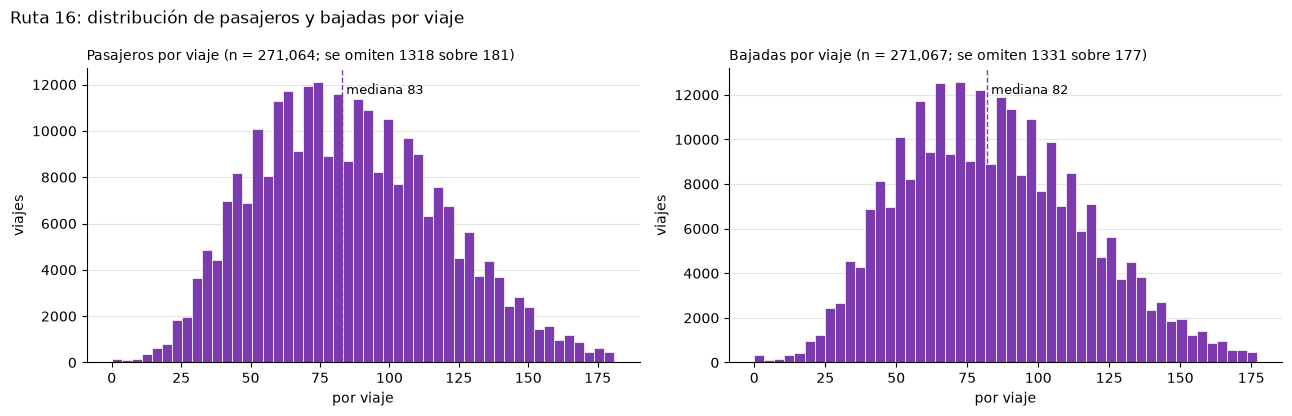

In [7]:
# Población: pasajeros -> viajes aptos para demanda; bajadas -> viajes completos con bajadas registradas
pax = d16.loc[d16["apto_demanda"], "numeropasajeros"] # escoge solo los aptos para demanda y la columna numeropasajeros
compl = d16[d16["categoria_embudo"].astype(str).str.startswith(("5)", "6)", "7)"))].copy() # escoge categorías 5 6 y 7
baj = compl["numerobajadas"].dropna() # se queda solo con numerobajadas

tabla = pd.DataFrame([describir(pax, "Pasajeros por viaje"), describir(baj, "Bajadas por viaje")])
tabla_bonita(tabla.rename_axis("Variable"), miles=["n"], decimales=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hist_simple(axes[0], pax, "Pasajeros por viaje", COLOR)
hist_simple(axes[1], baj, "Bajadas por viaje", COLOR)
fig.suptitle("Ruta 16: distribución de pasajeros y bajadas por viaje", x=0.01, ha="left")
plt.tight_layout(); plt.show()

En cuanto a la distribución de pasajeros y bajadas por viaje, se puede observar que ambas variables presentan valores centrales similares. Para los pasajeros, la mediana es de 83 por viaje, mientras que para las bajadas es de 82. Sin embargo, se presenta una diferencia importante en la dispersión de los datos: mientras que los pasajeros tienen una desviación estándar de 33,8, las bajadas presentan una de 1.592,8. Esto se debe a la presencia de valores extremos en las bajadas, donde se alcanza un máximo de 555.778 y una asimetría de 303,6, lo que sugiere posibles anomalías en los registros. Por otro lado, los pasajeros presentan una distribución mucho menos asimétrica, con un valor de 0,4. En general, estos resultados sugieren que la variable de bajadas requiere una revisión adicional para identificar posibles errores o valores atípicos antes de continuar con el análisis.

Dado que hay un valor que esta introduciend mucho ruido a la media, lo identificamos y procedemos a excluirlo para ver como se comporta los datos, sin este ruido. Aparte de que, un viaje con 555778 no es posible.

In [8]:
# los casos más extremos, para revisarlos
cols_ver = ["idprogramacion", "fecha_operativa", "idvehiculo", "numeropasajeros", "numerobajadas"]
compl.loc[compl["numerobajadas"] > 500, cols_ver].sort_values("numerobajadas", ascending=False).head(15)

idprogramacion fecha_operativa idvehiculo  numeropasajeros  \
431636         6948512      2025-04-09  SOBUSA207             39.0   
447782         7019449      2025-05-11  SOBUSA207             45.0   
476253         7144077      2025-07-04  SOBUSA143          28816.0   
268719         6219550      2024-05-20  SOBUSA451          97199.0   
404982         6830929      2025-02-17  SOBUSA416            128.0   
564457         7545951      2025-12-30  SOBUSA560             86.0   
398293         6801141      2025-02-04  SOBUSA238             64.0   
415026         6874657      2025-03-10  SOBUSA416            115.0   

        numerobajadas  
431636       555778.0  
447782       505268.0  
476253       288384.0  
268719       200562.0  
404982         9929.0  
564457         2073.0  
398293          804.0  
415026          556.0

Vemos que hay en total 8 valores atípicos en el número de bajadas, estos se supondrán como errores dado que en un viaje es imposible que hayan más de 500.000 bajadas, pues por resultados anteriores, sabemos que en un viaje el número de pasajeros es menor o igual que 83. No corresponden a casos aislados, ya sea un bus o una fecha en específico, dado que son todos buses distintos y fechas operativas distintas.

Si graficamos sin tener en cuenta estos valores nos queda:

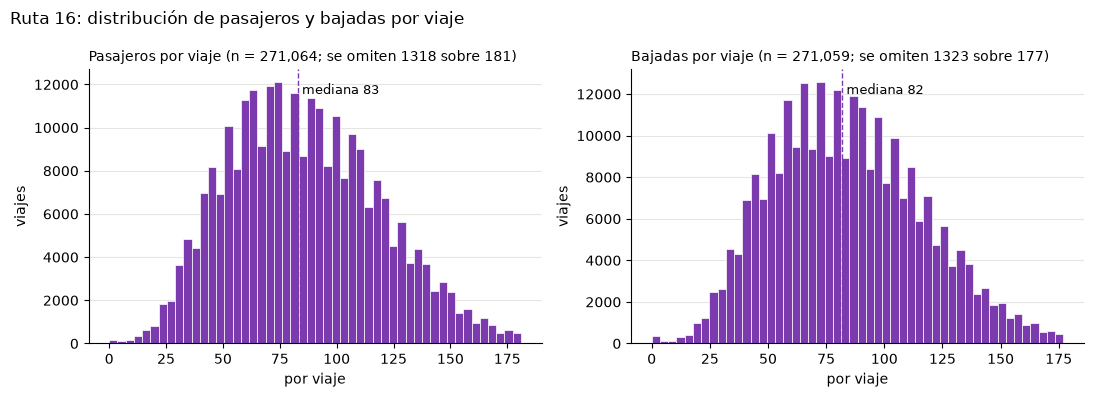

In [9]:
# Población: pasajeros -> viajes aptos para demanda; bajadas -> viajes completos con bajadas registradas
pax = d16.loc[d16["apto_demanda"], "numeropasajeros"] # escoge solo los aptos para demanda y la columna numeropasajeros
compl = d16[d16["categoria_embudo"].astype(str).str.startswith(("5)", "6)", "7)"))].copy() # escoge categorías 5 6 y 7
baj = compl.loc[~compl["baj_atipico"], "numerobajadas"].dropna() # se queda solo con numerobajadas

tabla = pd.DataFrame([describir(pax, "Pasajeros por viaje"), describir(baj, "Bajadas por viaje")])
tabla_bonita(tabla.rename_axis("Variable"), miles=["n"], decimales=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hist_simple(axes[0], pax, "Pasajeros por viaje", COLOR)
hist_simple(axes[1], baj, "Bajadas por viaje", COLOR)
fig.suptitle("Ruta 16: distribución de pasajeros y bajadas por viaje", x=0.01, ha="left")
plt.tight_layout(); plt.show()

Luego de excluir esos valores atípicos, se puede observar que ambas variables presentan un comportamiento bastante similar. La mediana es de 83 pasajeros por viaje y 82 bajadas, mientras que las medias son de 86,0 y 84,4, respectivamente. De igual forma, la dispersión de los datos es similar, con desviaciones estándar de 33,8 para pasajeros y 32,9 para bajadas. Ambas variables presentan una asimetría positiva de 0,4, lo que indica una ligera tendencia hacia valores más altos. Por otro lado, los valores máximos son de 413 pasajeros y 474 bajadas por viaje. En general, estos resultados muestran una distribución similar entre ambas variables sin esos datos desproporcionadamente altos.

##### **Distribución de la duración de los viajes**

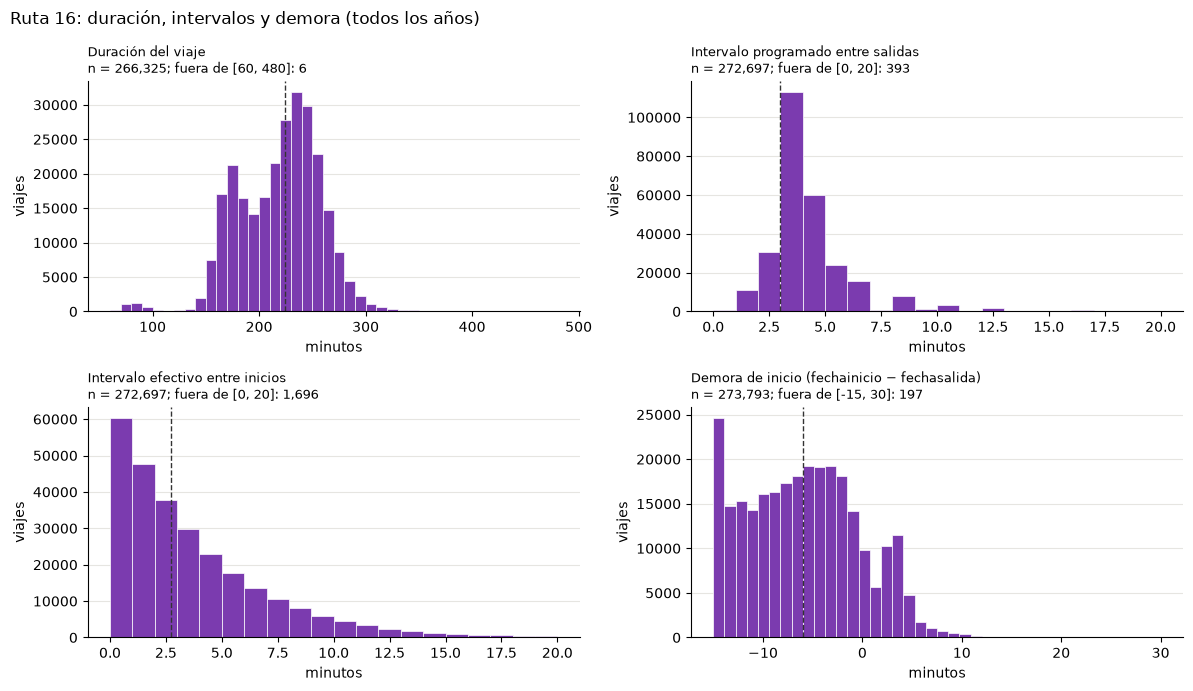

In [10]:
# Duración: solo completos con fecha de fin y dentro de rango (60 a 480 min); el resto se cuenta aparte
dur = compl.loc[compl["dur_min"].notna() & ~compl["dur_fuera_rango"], "dur_min"] # aquellos cuya duración minutos no es na y no esta fuera del rango
dur_excl = int(compl["dur_min"].isna().sum() + compl["dur_fuera_rango"].sum()) # contamos los que son na y estan fuera del rango

# Intervalo programado (fechasalida) y efectivo (fechainicio), dentro de cada fecha operativa
ai = d16[d16["apto_intervalo"]].sort_values(["fecha_operativa", "fechasalida", "idprogramacion"]).copy() # organizamos py aquellos que son aptos para el intervalo

ai["interv"] = ai.groupby("fecha_operativa")["fechasalida"].diff().dt.total_seconds() / 60
ae = ai[ai["fechainicio"].notna()].sort_values(["fecha_operativa", "fechainicio", "idprogramacion"]).copy()
ae["interv_ef"] = ae.groupby("fecha_operativa")["fechainicio"].diff().dt.total_seconds() / 60
ae["demora"] = (ae["fechainicio"] - ae["fechasalida"]).dt.total_seconds() / 60

tabla_u = pd.DataFrame([
    describir_num(dur, "Duración del viaje (min)", dur_excl),
    describir_num(ai["interv"], "Intervalo programado (min)", ai["interv"].isna().sum()),
    describir_num(ae["interv_ef"], "Intervalo efectivo (min)", ae["interv_ef"].isna().sum()),
    describir_num(ae["demora"], "Demora de inicio (min)", len(ai) - len(ae)),
])

tabla_bonita(tabla_u.rename_axis("Variable"), miles=["n", "Excluidos / sin dato"], decimales=1)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
hist_rango(axes[0, 0], dur, "Duración del viaje", (60, 480), 42, "minutos")
hist_rango(axes[0, 1], ai["interv"], "Intervalo programado entre salidas", (0, 20), 20, "minutos")
hist_rango(axes[1, 0], ae["interv_ef"], "Intervalo efectivo entre inicios", (0, 20), 20, "minutos")
hist_rango(axes[1, 1], ae["demora"], "Demora de inicio (fechainicio − fechasalida)", (-15, 30), 40, "minutos")
fig.suptitle("Ruta 16: duración, intervalos y demora (todos los años)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

En cuanto a las variables relacionadas con los tiempos de operación, se pueden observar algunas inconsistencias importantes. 

En primer lugar, la duración del viaje presenta una mediana de 224,6 minutos, pero también registra un valor mínimo de -37.489,9 minutos y una asimetría de -340,7, lo que sugiere la presencia de registros atípicos que deben revisarse. Por otro lado, el intervalo programado presenta un comportamiento más estable, con una mediana de 3 minutos y una media de 3,8 minutos, aunque alcanza un máximo de 369 minutos. En el caso del intervalo efectivo, la mediana es de 2,7 minutos, pero su desviación estándar de 66,3 y su máximo de 24.373,4 minutos evidencian la presencia de valores extremos.

Finalmente, la demora de inicio presenta una mediana de -6 minutos, lo que indica que, en general, los viajes tienden a iniciar antes de la hora programada. Sin embargo, se observa un máximo de 41.914,2 minutos y una asimetría de 343,1, por lo que también es necesario revisar estos registros. 

En general, aunque las medianas permiten tener una primera aproximación al comportamiento habitual de los tiempos, los valores extremos pueden distorsionar las medias y las desviaciones estándar, por lo que sería conveniente revisarlos antes de continuar con el análisis.

In [11]:
# identificamos aquellos que se encuentran arriba del percentil 99
d = compl["dur_min"]
cat = np.select([d.isna(), d < 0, d < 60, d > 480],
                ["Sin fecha de fin", "Negativa", "0 a 60 min", "Más de 480 min"],
                default="60 a 480 min")
print(pd.crosstab(cat, compl["dur_fuera_rango"], margins=True))   # columnas: bandera del ETL

dur = d[d.between(60, 480)]
dur_excl = int(len(compl) - len(dur))
print(f"Duración válida: {len(dur):,} | excluidos: {dur_excl:,}")

dur_fuera_rango   False  True     All
row_0                                
0 a 60 min            0    16      16
60 a 480 min     266319     0  266319
Más de 480 min        0  5122    5122
Negativa              6     0       6
All              266325  5138  271463
Duración válida: 266,319 | excluidos: 5,144


De los 271,463 viajes completos de la ruta 16, 266,319 (98.1%) tienen una duración entre 60 y 480 minutos. Los 5,144 restantes (1.9%) se excluyen del análisis de duración: 5,122 superan los 480 minutos, 16 duran menos de 60 y 6 tienen duración negativa (`fechafin` anterior a `fechainicio`). 

In [12]:
umb = [15, 30, 60, 480, 1440]
tb = pd.DataFrame({
    "Intervalo programado": [(ai["interv"] > u).sum() for u in umb],
    "Intervalo efectivo": [(ae["interv_ef"] > u).sum() for u in umb],
    "Demora de inicio": [(ae["demora"] > u).sum() for u in umb],
}, index=[f"> {u} min" for u in umb])
tb.loc["< −15 min"] = ["", "", int((ae["demora"] < -15).sum())]
tabla_bonita(tb.rename_axis("Umbral"), decimales=0)

# vemos los casos cuya demora es mayor a 1440
ver = ["idprogramacion", "fecha_operativa", "idvehiculo", "fechasalida", "fechainicio", "fechafin"]
ae.loc[ae["demora"] > 1440, ver].sort_values("fechainicio").head(10)

idprogramacion fecha_operativa idvehiculo         fechasalida  \
22926          5154900      2023-02-13  SOBUSA327 2023-02-13 05:49:00   
56954          5294729      2023-04-18  SOBUSA327 2023-04-18 05:31:00   
117904         5553429      2023-08-09  SOBUSA416 2023-08-09 06:13:00   
159068         5739210      2023-10-26  SOBUSA458 2023-10-26 04:45:00   
189536         5875013      2023-12-23  SOBUSA186 2023-12-23 04:45:00   
203981         5939201      2024-01-22  SOBUSA167 2024-01-22 05:29:00   
225233         6030780      2024-03-01  SOBUSA428 2024-03-01 04:50:00   
235372         6074583      2024-03-19  SOBUSA154 2024-03-19 05:34:00   
285727         6297354      2024-06-24  SOBUSA162 2024-06-24 05:00:00   
337986         6534126      2024-10-08  SOBUSA154 2024-10-08 04:40:00   

               fechainicio            fechafin  
22926  2023-02-19 07:40:45 2023-02-22 15:02:11  
56954  2023-04-25 11:43:24 2023-04-25 15:38:36  
117904 2023-08-13 18:15:30 2023-08-14 12:05:19  
159068 2023-10-28 12:06:39 2023-10-28 13:37:03  
189536 2023-12-24 08:53:10 2023-12-24 11:58:58  
203981 2024-01-24 12:02:16 2024-01-25 06:06:05  
225233 2024-03-03 15:04:45 2024-03-08 12:26:26  
235372 2024-03-20 10:25:06 2024-03-20 11:08:24  
285727 2024-06-27 09:50:37 2024-07-03 06:09:02  
337986 2024-10-12 10:47:25 2024-10-29 15:58:04

Sobre 272,697 intervalos programados, 1,425 (0.52%) superan los 15 minutos, 105 superan los 30 y ninguno supera las 8 horas: el intervalo programado no presenta valores imposibles. El intervalo efectivo, calculado con `fechainicio`, presenta más valores altos: 4,941 (1.8%) superan 15 minutos y 18 superan las 8 horas (12 de ellos, un día), lo que no es posible entre salidas de un mismo día. En la demora de inicio (`fechainicio` − `fechasalida`) ningún caso baja de −15 minutos, es decir, el límite inferior es exacto, mientras que 470 casos (0.17%) superan 15 minutos, 75 superan 60 minutos y 16 superan un día.

En los diez casos mostrados, `fechasalida` corresponde a una salida temprana (entre las 04:40 y las 06:13) de la fecha operativa, pero `fechainicio` ocurre entre 1 y 7 días después y `fechafin` aún más tarde (hasta 21 días después de la salida programada en el caso más extremo). Los casos se reparten entre 2023 y 2024, y algunos buses se repiten (**SOBUSA327** y **SOBUSA154** aparecen dos veces). Pueden ser viajes que quedaron abiertos y fueron iniciados o cerrados manualmente días después, lo que se relaciona con el cierre automático observado hacia la 01:00.

Inicios inconsistentes (demora > 480 min): 21 de 273,793


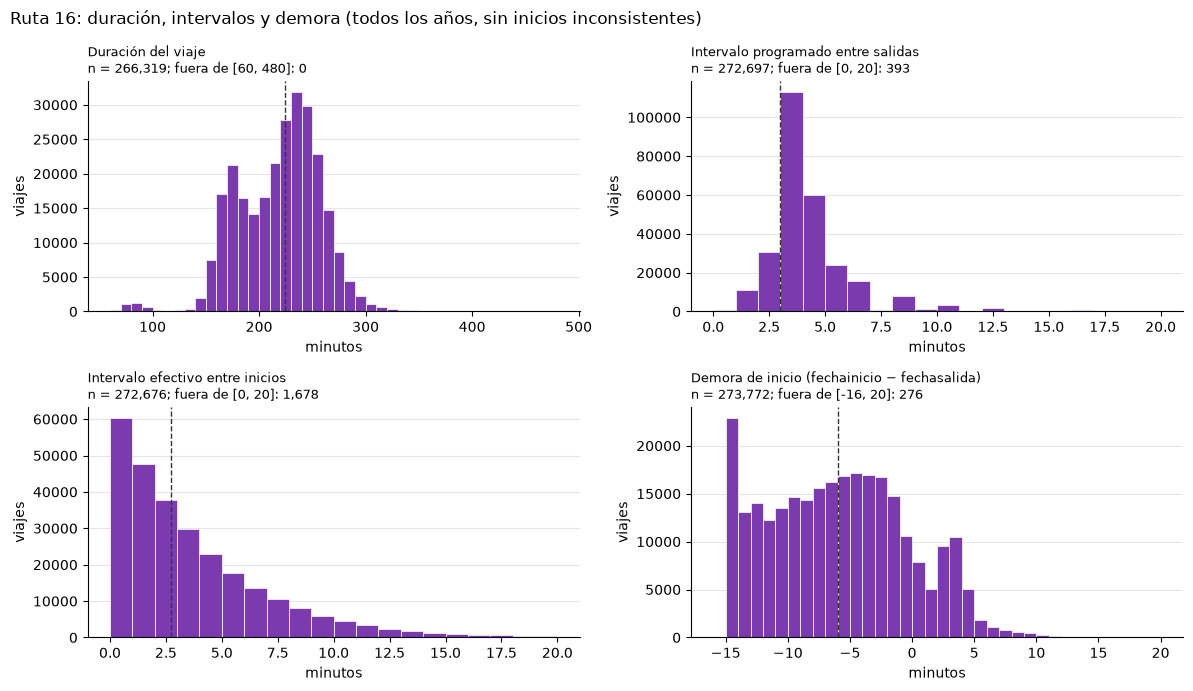

In [13]:
# Marca (no elimina) los inicios inconsistentes: más de 480 min después de la salida programada
LIM_INICIO = 480
ae = ai[ai["fechainicio"].notna()].sort_values(["fecha_operativa", "fechainicio", "idprogramacion"]).copy()
ae["demora"] = (ae["fechainicio"] - ae["fechasalida"]).dt.total_seconds() / 60
ae["inicio_inconsistente"] = ae["demora"] > LIM_INICIO
n_inc = int(ae["inicio_inconsistente"].sum())

# los intervalos efectivos se recalculan sin esos viajes
ae_ok = ae[~ae["inicio_inconsistente"]].copy()
ae_ok["interv_ef"] = ae_ok.groupby("fecha_operativa")["fechainicio"].diff().dt.total_seconds() / 60

tabla_u = pd.DataFrame([
    describir_num(dur, "Duración del viaje (min)", dur_excl),
    describir_num(ai["interv"], "Intervalo programado (min)", ai["interv"].isna().sum()),
    describir_num(ae_ok["interv_ef"], "Intervalo efectivo (min)", ae_ok["interv_ef"].isna().sum() + n_inc),
    describir_num(ae_ok["demora"], "Demora de inicio (min)", n_inc),
])
tabla_bonita(tabla_u.rename_axis("Variable"), miles=["n", "Excluidos / sin dato"], decimales=1)
print(f"Inicios inconsistentes (demora > {LIM_INICIO} min): {n_inc} de {len(ae):,}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
hist_rango(axes[0, 0], dur, "Duración del viaje", (60, 480), 42, "minutos")
hist_rango(axes[0, 1], ai["interv"], "Intervalo programado entre salidas", (0, 20), 20, "minutos")
hist_rango(axes[1, 0], ae_ok["interv_ef"], "Intervalo efectivo entre inicios", (0, 20), 20, "minutos")
hist_rango(axes[1, 1], ae_ok["demora"], "Demora de inicio (fechainicio − fechasalida)", (-16, 20), 36, "minutos")
fig.suptitle("Ruta 16: duración, intervalos y demora (todos los años, sin inicios inconsistentes)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

Dentro del rango, la duración es compacta y casi simétrica (asimetría −0.1): la mediana es de 224.6 minutos (unas 3 h 45 min), y el 90% central está entre 159.6 (P5) y 275.2 minutos (P95). La media y la desviación dependen del corte en 480 minutos, que excluye al 1.9% de los viajes más largos, por lo que se reporta la mediana. El intervalo programado entre salidas tiene mediana de 3 minutos (P5 = 2; P95 = 8). El intervalo efectivo, calculado con `fechainicio`, tiene el extremo inferior más comprimido (P5 = 0.2 y P25 = 1.1 minutos, frente a 2.0 y 3.0 del programado). La demora de inicio es negativa en la mayoría de los viajes (mediana de −6.0 minutos; el 90% central entre −14.6 y 3.7), lo que indica que hay viajes que inician antes de lo programado.

##### **Disponibilidad de flota y plazas por bus**

In [14]:
con = compl[~compl["plazas_sin_dato"]] # selecciona aquellas que sí tengan registrado el número de sentados y de pie.
pl = con.groupby("plazas_total").size().rename("Viajes").to_frame() 
pl["%"] = pl["Viajes"] / pl["Viajes"].sum() * 100
display(pl.rename_axis("Plazas (sentados + de pie)"))

bus = compl.groupby("idvehiculo")["plazas_sin_dato"].max()
print(f"Viajes completos sin dato de plazas: {int(compl['plazas_sin_dato'].sum()):,} de {len(compl):,} "
      f"({compl['plazas_sin_dato'].mean() * 100:.1f}%)")
print(f"Buses sin dato de plazas: {int(bus.sum())} de {len(bus)}")

Viajes          %
Plazas (sentados + de pie)                   
32                               9   0.003621
34                            1722   0.692913
39                            5346   2.151169
44                              40   0.016096
45                              10   0.004024
46                            7782   3.131388
47                           35671  14.353603
48                             194   0.078063
49                           36675  14.757601
50                           78316  31.513464
51                             234   0.094159
53                            8415   3.386100
55                           10714   4.311191
56                               8   0.003219
57                            7571   3.046484
58                           37854  15.232017
59                             900   0.362150
60                             338   0.136007
61                            4300   1.730271
62                            5170   2.080349
64                            2338   0.940784
70                            4892   1.968485
72                              17   0.006841

Viajes completos sin dato de plazas: 22,947 de 271,463 (8.5%)
Buses sin dato de plazas: 19 de 291


De los 271,463 viajes completos de la ruta 16, 248,516 (91.5%) tienen dato de plazas (sentados + de pie) y 22,947 (8.5%) no lo tienen (`n_sentados` y `n_depie` en cero o nulos). Entre los viajes con dato se observan 23 valores distintos, de 32 a 72 plazas, muy concentrados: 50 (31.5%), 58 (15.2%), 49 (14.8%) y 47 (14.4%) reúnen el 75.9% de los viajes. Siete valores (32, 44, 45, 48, 51, 56 y 72) aparecen en menos del 0.1% de los viajes y pueden corresponder a unidades particulares o a errores de digitación. La tabla cuenta viajes y no buses. La suma de plazas se usa como aproximación de la capacidad nominal, porque la variable de la tabla `vehiculos` (`capacidad`) es 0 en toda la flota. Los viajes sin dato de plazas no se imputan; se marcaran como inválidos hasta que se decida que hacer con Extreme.

Respecto a la disponibilidad de flota (en este caso ruta 16), se tomara como cierto lo digitado en la tabla `rutas`, la cual contiene una variable denominada `flotadisp_prog` que en el diccionario se define como: "Flota disponible para programación.". Veamos: 

In [15]:
df_ruta[["idruta", "nombre", "proceso", "distancia_global", "flotadisp_prog"]]

idruta  nombre proceso  distancia_global  flotadisp_prog
0      16  CRA 54  sobusa              56.4              62

**Flota disponible:** contamos con 62 buses para la ruta 16.

Ahora, identifiquemos los buses que no tienen dato:

In [16]:
compl.loc[compl["plazas_sin_dato"], "idvehiculo"].value_counts()

idvehiculo
SOBUSA151    2766
SOBUSA519    2635
SOBUSA167    2265
SOBUSA224    2253
SOBUSA186    2189
SOBUSA162    2122
SOBUSA209    2055
SOBUSA210    1828
SOBUSA153    1674
SOBUSA166    1527
SOBUSA451    1209
SOBUSA150     349
SOBUSA126      57
SOBUSA283       7
SOBUSA370       4
SOBUSA527       4
SOBUSA275       1
SOBUSA264       1
SOBUSA102       1
Name: count, dtype: int64

En total, son unos 19 buses que no cuentan con el dato de las plazas. Hasta ahora no se hará nada con ellos, se marcan para posteriormente poder preguntarle a Extreme sobre su capacidad.

##### **Patrones por hora**

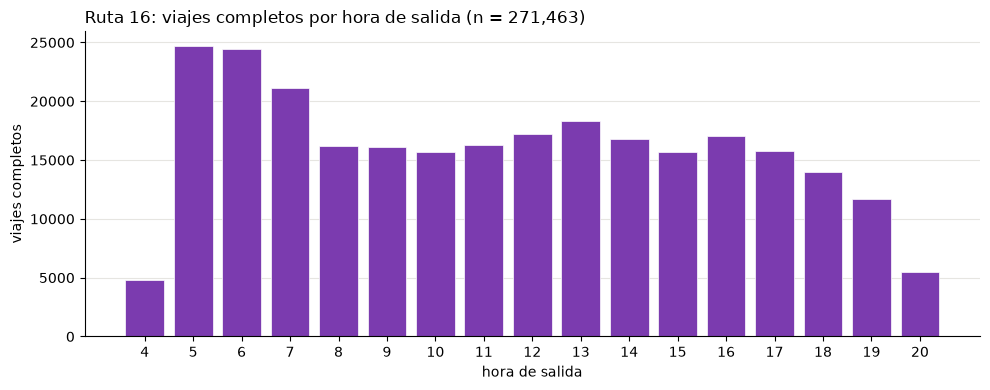

Mediana del primer viaje del día: 04:30 | del último: 20:40 | días con servicio: 1,096


In [17]:
hh = compl["fechasalida"].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hh.index, hh.values, color=COLOR, edgecolor="white", linewidth=0.5)
ax.set_xticks(hh.index); ax.set_xlabel("hora de salida"); ax.set_ylabel("viajes completos")
ax.set_title(f"Ruta 16: viajes completos por hora de salida (n = {len(compl):,})", loc="left")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# primer y último viaje de cada fecha operativa (mediana de todos los días)
mm = compl["fechasalida"].dt.hour * 60 + compl["fechasalida"].dt.minute
g = mm.groupby(compl["fecha_operativa"]).agg(["min", "max"])
def hhmm(m): return f"{int(m)//60:02d}:{int(m)%60:02d}"
print(f"Mediana del primer viaje del día: {hhmm(g['min'].median())} | del último: {hhmm(g['max'].median())} | días con servicio: {len(g):,}")

Los viajes completos de la ruta 16 salen entre las 04:00 y las 20:00 horas. La mediana del primer viaje del día es a las 04:30 y la del último a las 20:40, y hubo servicio los 1,096 días del período. El mayor número de salidas se concentra entre las 5 y las 7 (alrededor de 21 a 25 mil viajes por hora), seguido de una meseta de 15 a 18 mil entre las 8 y las 17, y un descenso desde las 18. Las horas 4 y 20 son bajas porque el servicio empieza y termina dentro de esas horas (parciales). Este gráfico describe la oferta de despachos, no la demanda: que haya más salidas a primera hora coincide con el headway más corto de la planilla en esas horas, pero no implica que los pasajeros se concentren ahí.

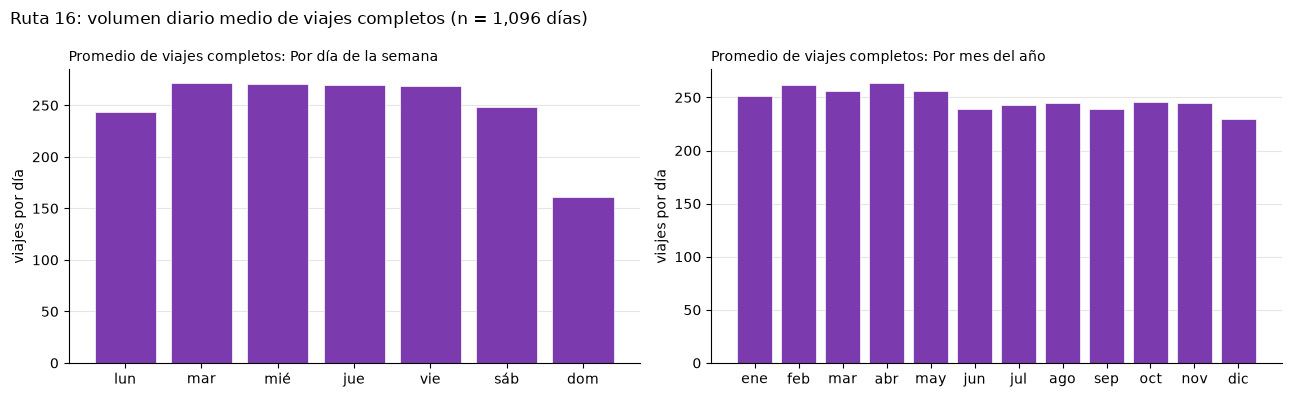

In [18]:
# Volumen de viajes completos por día de la semana y por mes del año (todos los años juntos)
# Se usa el promedio de viajes por día para no sesgar por días o meses con más fechas
dias = compl.groupby("fecha_operativa").size().rename("viajes").reset_index()
dias["dow"] = dias["fecha_operativa"].dt.dayofweek + 1
dias["mes"] = dias["fecha_operativa"].dt.month
por_dow = dias.groupby("dow")["viajes"].mean()
por_mes = dias.groupby("mes")["viajes"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s, etiquetas, tit in [
    (axes[0], por_dow, ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"], "Por día de la semana"),
    (axes[1], por_mes, ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"], "Por mes del año"),
]:
    ax.bar(range(len(s)), s.values, color=COLOR, edgecolor="white", linewidth=0.5)
    ax.set_xticks(range(len(s))); ax.set_xticklabels(etiquetas)
    ax.set_title(f"Promedio de viajes completos: {tit}", loc="left", fontsize=10)
    ax.set_ylabel("viajes por día")
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
fig.suptitle(f"Ruta 16: volumen diario medio de viajes completos (n = {len(dias):,} días)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

El volumen diario medio de viajes completos de la ruta 16 es casi constante de martes a viernes (alrededor de 270 viajes por día). El lunes y el sábado son algo menores (entre 243 y 248), y el domingo es el día de menor oferta, con cerca de 160 viajes por día, aproximadamente el 60% de un día entre semana. Hubo servicio todos los días del período, incluidos los domingos. Por mes del año no hay una concentración marcada: el promedio diario se mantiene entre 230 y 262 viajes, con valores algo más altos de enero a mayo, más bajos de junio a noviembre y el mínimo en diciembre. Como cada mes calendario aparece en los tres años, la tendencia anual no sesga esta comparación.

##### **Distribución de los viajes por segmento**

In [19]:
print(f'Número de segmentos: {df_rutas_segmentos["nro_segmento"].nunique()}')
print(f'Longitud de segmentos: {df_rutas_segmentos["longitud_m"].iloc[0]}')

Número de segmentos: 123
Longitud de segmentos: 500.0


La ruta 16 tiene 123 segmentos de 500 m en su configuración (idrutageo 10). La tabla `timbradas_segmentos`, que registra pasajeros por segmento, solo cubre del 2023-01-01 al 2023-02-27, y en una consulta sin filtrar por ruta el 32.1% de sus filas tiene pasajeros negativos [V; no medido por ruta]. Las tablas de segmentos agregadas por año y consolidadas están vacías. Por estas razones, los segmentos no son utilizables en este momento para el análisis ni para el modelo; se documenta como limitación y se consulta a Extreme por el alcance de la tabla y el significado de los valores negativos.

##### **Atipícos y faltantes**

In [20]:
cat = d16["categoria_embudo"].astype(str)
dd = compl["dur_min"]

filas = [
    ("Viajes", "Cancelados", (d16["estado_viaje"] == "cancelado").sum(), len(d16)),
    ("Viajes", "Menos del 10% del circuito", cat.str.startswith("3)").sum(), len(d16)),
    ("Viajes", "Parciales (10% a 50%)", cat.str.startswith("4)").sum(), len(d16)),
    ("Pasajeros por viaje", "Sin dato (vacío)", cat.str.startswith("5)").sum(), len(compl)),
    ("Pasajeros por viaje", "Cero", cat.str.startswith("6)").sum(), len(compl)),
    ("Pasajeros por viaje", "Más de 500 (atípico)", (d16["numeropasajeros"] > 500).sum(), d16["numeropasajeros"].notna().sum()),
    ("Bajadas por viaje", "Más de 500 (atípico)", (d16["numerobajadas"] > 500).sum(), d16["numerobajadas"].notna().sum()),
    ("Duración", "Fuera de rango (<60 o >480 min)", ((dd < 60) | (dd > 480)).sum(), len(compl)),
    ("Duración", "Negativa", (dd < 0).sum(), len(compl)),
    ("Duración", "Sin fecha de fin", dd.isna().sum(), len(compl)),
    ("Intervalo programado", "Salidas simultáneas (0 min)", (ai["interv"] == 0).sum(), ai["interv"].notna().sum()),
    ("Intervalo programado", "Mayor de 30 min", (ai["interv"] > 30).sum(), ai["interv"].notna().sum()),
    ("Intervalo programado", "Primer viaje del día (sin intervalo)", ai["interv"].isna().sum(), len(ai)),
    ("Inicio", "Demora > 480 min (inicio inconsistente)", n_inc, len(ae)),
    ("Plazas", "Viajes sin dato de plazas", compl["plazas_sin_dato"].sum(), len(compl)),
    ("Plazas", "Buses sin dato de plazas", bus.sum(), len(bus)),
]
cuadro = pd.DataFrame(filas, columns=["Variable", "Regla", "Casos", "Base (n)"])
cuadro["Casos"] = cuadro["Casos"].astype(int)
cuadro["% de la base"] = cuadro["Casos"] / cuadro["Base (n)"] * 100
tabla_bonita(cuadro, miles=["Casos", "Base (n)"], decimales=2, alto="400px")

Las pérdidas de calidad en la ruta 16 son pequeñas y localizadas. Sobre 300,276 viajes, el 5.85% se cancela y el 3.74% termina por debajo del 50% del circuito. Entre los 271,463 viajes completos, el 1.89% tiene duración fuera de rango (5,122 superan 8 horas), 6 tienen duración negativa y 396 no tienen pasajeros registrados (0.15%). Los pasajeros y las bajadas son nulos en los mismos viajes, y solo 3 viajes superan los 500 pasajeros y 8 superan las 500 bajadas. El 8.45% de los viajes completos (22,947) carece de dato de plazas; corresponden a 19 de los 291 buses que aparecen en la ruta. El intervalo programado tiene 655 salidas simultáneas (0.24%) y 105 intervalos mayores de 30 minutos, y 21 inicios son inconsistentes. Los casos no son excluyentes y cada fila tiene su propia base.

### **Análisis bivariado**

#### **Volumen y tendencia**

En esta sección, se análizara cuánto servicio y como cambia a lo largo del tiempo, para ver si el número de viajes ha disminuido, si ha cambiado la oferta o la demanda, entre otras cosas. Para este análisis, se utilizara la tabla `progvehiculos` y `timbradas_anio` que se usarán nada más como contraste.

##### **Viajes por año, mes, semana y día de la semana**

En este caso, para concentrarse en la distribución de los viajes se incluyo en una misma categoría las etiquetas de completo, sin distinguir entre los ceros y nulos. Esto se hará exclusivamente por tema de visualización; no obstante, se sabe de la interpretación que hay que darle. La cantidad de nulos y ceros en estos viajes se analizar más adelante en la parte de demanda.

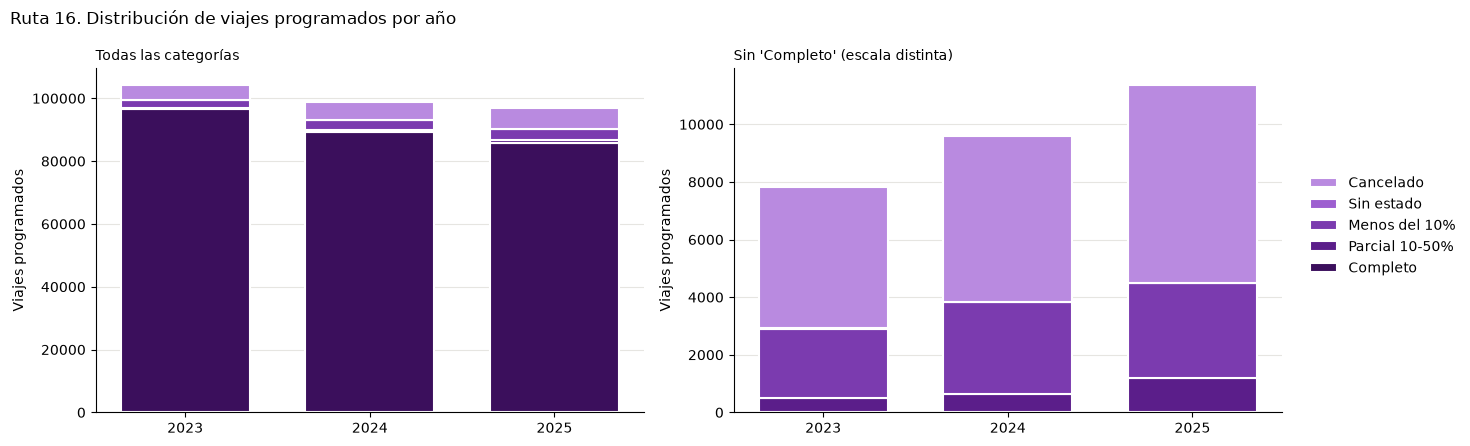

In [21]:

tab = viajes_por_(d16, "anio", columna="grupo")[orden]
assert tab.sum().sum() == len(d16)
apilado_doble(tab, orden, colores_grupo, "Completo", "Ruta 16. Distribución de viajes programados por año")

tab["Total"] = tab.sum(axis=1)
tab_vista = tab.copy()
tab_vista.columns.name = None
tab_vista = tab_vista.reset_index().rename(columns={"anio": "Año", "pct_cancelados": "% Cancelados"})

show(tab_vista, paging=False, searching=False, ordering=True, info=False, dom="t", showIndex=False)

De acuerdo con los resultados anteriores, se pueden destacar los siguientes hallazgos:

- **El año 2023 registró el mayor número de viajes**, con un total de 104.327, de los cuales 96.490 fueron completos, es decir, recorrieron al menos el 50 % del circuito, según el criterio establecido. Además, 498 viajes fueron parciales, al recorrer entre el 10 % y menos del 50 % del circuito, mientras que 2.407 recorrieron menos del 10 %. Por otro lado, se registraron 4.924 viajes cancelados y 8 viajes sin estado.

- **Los viajes cancelados aumentaron de manera consecutiva durante los tres años analizados**, pasando de 4.924 en 2023 a 5.753 en 2024 y 6.889 en 2025. También se observa un aumento en los viajes que recorrieron menos del 10 % del circuito, que pasaron de 2.407 en 2023 a 3.203 en 2024 y 3.283 en 2025. En cuanto a los viajes parciales, estos aumentaron de 498 en 2023 a 631 en 2024 y 1.201 en 2025.

- **El año 2025 registró el menor número de viajes completos**, con 85.659, frente a los 96.490 de 2023 y los 89.314 de 2024. Asimismo, fue el año con el mayor número de cancelaciones y de viajes parciales o inferiores al 10 % del circuito. En conjunto, estos resultados muestran una disminución en el número de viajes completos y un aumento en las categorías de viajes cancelados, parciales y de recorrido inferior al 10 %.

- **Los viajes sin estado fueron poco frecuentes**: se registraron 8 casos en 2023, 15 en 2024 y 1 en 2025, para un total de 24 casos. Debido a su baja frecuencia, su contribución al análisis descriptivo general es limitada. No obstante, conviene conservarlos identificados como casos sin estado, en lugar de eliminarlos, ya que pueden representar registros con información operativa incompleta.

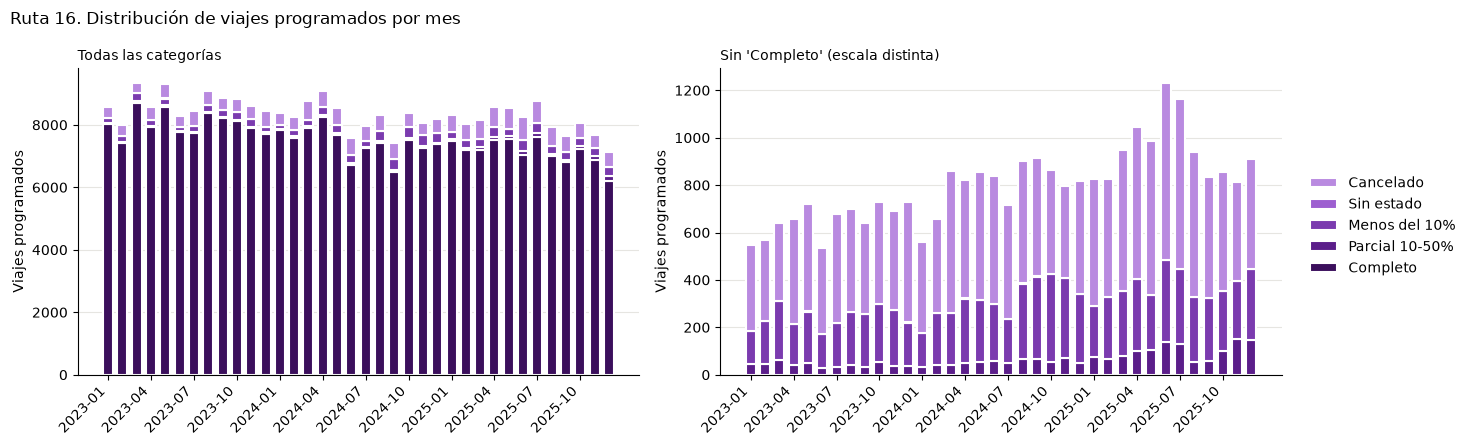

Mes  Completo  Parcial 10-50%  Menos del 10%  Sin estado  Cancelado  \
0   2023-01      8029              45            141           0        361   
1   2023-02      7419              45            181           1        340   
2   2023-03      8700              64            248           0        330   
3   2023-04      7925              40            176           0        442   
4   2023-05      8577              49            217           3        450   
5   2023-06      7763              28            142           0        363   
6   2023-07      7751              31            186           0        463   
7   2023-08      8378              39            225           1        436   
8   2023-09      8210              32            223           2        383   
9   2023-10      8113              53            246           0        431   
10  2023-11      7905              36            238           0        416   
11  2023-12      7720              36            184           1        509   
12  2024-01      7833              31            145           0        385   
13  2024-02      7591              40            219           0        400   
14  2024-03      7905              43            217           1        598   
15  2024-04      8254              50            270           4        498   
16  2024-05      7685              54            262           1        540   
17  2024-06      6726              56            241           1        541   
18  2024-07      7255              51            185           0        480   
19  2024-08      7417              66            318           2        514   
20  2024-09      6495              68            344           4        497   
21  2024-10      7514              52            374           1        436   
22  2024-11      7254              71            337           1        388   
23  2024-12      7385              49            291           0        476   
24  2025-01      7477              74            214           0        536   
25  2025-02      7196              66            261           0        497   
26  2025-03      7202              79            273           0        596   
27  2025-04      7515             101            301           0        641   
28  2025-05      7538             103            235           0        648   
29  2025-06      7020             139            346           1        745   
30  2025-07      7615             128            320           0        714   
31  2025-08      7003              53            277           0        611   
32  2025-09      6805              59            263           0        511   
33  2025-10      7213             102            251           0        503   
34  2025-11      6863             151            243           0        421   
35  2025-12      6212             146            299           0        466   

    Total  % Cancelados  
0    8576           4.2  
1    7986           4.3  
2    9342           3.5  
3    8583           5.1  
4    9296           4.8  
5    8296           4.4  
6    8431           5.5  
7    9079           4.8  
8    8850           4.3  
9    8843           4.9  
10   8595           4.8  
11   8450           6.0  
12   8394           4.6  
13   8250           4.8  
14   8764           6.8  
15   9076           5.5  
16   8542           6.3  
17   7565           7.2  
18   7971           6.0  
19   8317           6.2  
20   7408           6.7  
21   8377           5.2  
22   8051           4.8  
23   8201           5.8  
24   8301           6.5  
25   8020           6.2  
26   8150           7.3  
27   8558           7.5  
28   8524           7.6  
29   8251           9.0  
30   8777           8.1  
31   7944           7.7  
32   7638           6.7  
33   8069           6.2  
34   7678           5.5  
35   7123           6.5

In [22]:
tab = viajes_por_(d16, "mes", columna="grupo")[orden]
assert tab.sum().sum() == len(d16)
apilado_doble(tab, orden, colores_grupo, "Completo", "Ruta 16. Distribución de viajes programados por mes")

tab_vista = tab.copy()
tab_vista["Total"] = tab_vista.sum(axis=1)
tab_vista["% Cancelados"] = (tab_vista["Cancelado"] / tab_vista["Total"] * 100).round(1)
tab_vista.columns.name = None
tab_vista = tab_vista.reset_index().rename(columns={"mes": "Mes"})
tab_vista["Mes"] = tab_vista["Mes"].astype(str)

display(tab_vista, paging=False, scrollY="300px", searching=False, ordering=True, info=False, dom="t", showIndex=False)

De acuerdo con el análisis mensual de los viajes entre 2023 y 2025, se pueden destacar los siguientes hallazgos:

- **El año 2023 registró la mayor cantidad de viajes completos en 10 de los 12 meses analizados:** enero (8.029), marzo (8.700), mayo (8.577), junio (7.763), julio (7.751), agosto (8.378), septiembre (8.210), octubre (8.113), noviembre (7.905) y diciembre (7.720). Por su parte, 2024 registró la mayor cantidad de viajes completos en febrero (7.591) y abril (8.254).

- **Los porcentajes de cancelación fueron particularmente elevados en junio y julio de 2025**, con un 9,0 % y un 8,1 %, respectivamente. En junio, el porcentaje de cancelaciones aumentó del 4,4 % en 2023 al 7,2 % en 2024 y al 9,0 % en 2025. En julio, pasó del 5,5 % en 2023 al 6,0 % en 2024 y al 8,1 % en 2025. Aunque estos resultados muestran un patrón de aumento en ambos meses, no permiten determinar las causas de este comportamiento. También cabe destacar diciembre de 2023, que registró un 6,0 % de cancelaciones.

- **La proporción de viajes cancelados aumentó en los años analizados, especialmente durante 2025.** Este comportamiento se observa en varios meses y coincide con una disminución general del número de viajes completos. Sin embargo, para determinar si ambos fenómenos están relacionados con cambios en la operación, sería necesario analizar otras variables, como la ruta, el día de la semana y las posibles novedades viales.

In [23]:
# dividimos ahora por semana
sem = viajes_por_(d16, "semana", columna="grupo")[orden]
# añade una nueva columna llamada Total que es la suma por fila (los viajes en total)
sem["Total"] = sem.sum(axis=1)
sem["% Cancelados"] = (sem["Cancelado"] / sem["Total"] * 100).round(1) # calcula el porcentaje de cancelados

# días distintos con al menos un viaje en cada semana
dias = (d16.groupby(d16["fecha_operativa"].dt.to_period("W"))["fecha_operativa"] # cada grupo es todos los viajes de una semana
          .nunique().rename("Días con viajes")) # cuenta cuantos días distintos hubo con al menos un viaje en esa semana
dias.index.name = "semana"
sem = sem.join(dias)

# se excluyen la primera y la última semana (incompletas por el borde del período)
sem_c = sem.iloc[1:-1].copy()
mediana = sem_c["Total"].median() # calculamos la mediana del grupo total
sem_c["Total / mediana"] = (sem_c["Total"] / mediana).round(2) 

# si la semana tuvo menos del 85% de la mediana o si hay un dia de la semana que no se trabajo se marcan como anomalo.
anomalas = sem_c[(sem_c["Total / mediana"] < 0.85) | (sem_c["Total / mediana"] > 1.15) | (sem_c["Días con viajes"] < 7)].copy()
anomalas = anomalas.sort_values("Total / mediana")
anomalas.columns.name = None
anomalas = anomalas.reset_index().rename(columns={"semana": "Semana"})
anomalas["Semana"] = anomalas["Semana"].dt.start_time.dt.strftime("%Y-%m-%d") # formato

print(f"Mediana semanal: {mediana:.0f} viajes | Mediana semanal (completos): {sem_c["Completo"].median():.0f} viajes | semanas analizadas: {len(sem_c)} | anómalas: {len(anomalas)}")
show(anomalas, paging=False, scrollY="250px", searching=False, ordering=True, info=False, dom="t", showIndex=False)

Mediana semanal: 1936 viajes | Mediana semanal (completos): 1744 viajes | semanas analizadas: 156 | anómalas: 8


Se analizaron 156 semanas, excluyendo la primera y la última por estar incompletas en los límites del período. Se identificaron ocho semanas anómalas, según criterios basados en la mediana semanal y en la cantidad de días con viajes. La mediana del total de viajes fue de 1.936 por semana, mientras que la de viajes completos fue de 1.744. Entre las semanas identificadas, destacan la del 22 de diciembre de 2025, con 1.492 viajes (77 % de la mediana), y la del 30 de diciembre de 2024, con 1.503 (78 %). Estos resultados evidencian semanas con menor volumen de viajes, aunque se requiere analizar el calendario festivo y las novedades operativas para investigar sus posibles causas.

Ahora, identificaremos si alguna de esas fechas anomalas corresponden a fiestas nacionales o festivos, lo cual podría explicar porque la mediana es menor que la de otras semanas.

In [24]:
anomalas1 = ["2025-12-22", "2024-12-30", "2025-03-03", "2025-12-08", "2024-09-02", "2024-07-01", "2024-01-01", "2025-12-15"]

# Etiqueta de cada semana: fecha de su lunes (los primeros 10 caracteres del periodo)
d16["semana_ini"] = d16["fecha_operativa"].dt.to_period("W").astype(str).str[:10]
w = d16[d16["semana_ini"].isin(anomalas1)] # se queda con los viajes cuyo semana_ini esté en la lista anomalas1.

# por semana: cuantos dias distintos tienen cada bandera (de 0 a 7)
res = w.groupby("semana_ini").apply(lambda x: pd.Series({"dias_festivo_nacional": x.loc[x["es_festivo_nacional"], "fecha_operativa"].nunique(), "dias_carnaval_centrales": x.loc[x["es_carnaval_dias_centrales"], "fecha_operativa"].nunique(), "dias_fiesta_atlantico": x.loc[x["es_fiesta_atlantico"], "fecha_operativa"].nunique(), "dias_temporada_nacional": x.loc[x["es_temporada_nacional"], "fecha_operativa"].nunique()}))
tabla_bonita(res, {"semana_ini": "Semana inicial", "dias_festivo_nacional": "Día de festivo nacional", "dias_carnaval_centrales": "Día de carnaval central", "dias_fiesta_atlantico": "Día de fiesta atlántico", "dias_temporada_nacional": "Día de temporada nacional"})

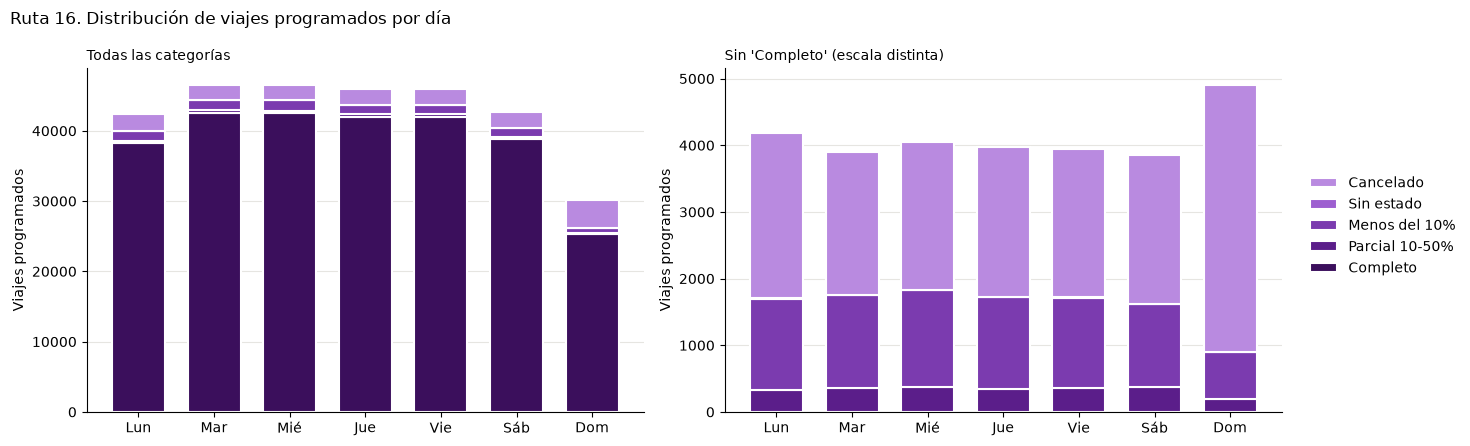

Dia  Completo  Parcial 10-50%  Menos del 10%  Sin estado  Cancelado  Total  \
0  Lun     38281             326           1370           6       2476  42459   
1  Mar     42605             360           1387           3       2150  46505   
2  Mié     42510             378           1446           6       2222  46562   
3  Jue     42009             346           1375           6       2251  45987   
4  Vie     41962             363           1353           1       2228  45907   
5  Sáb     38806             370           1255           1       2225  42657   
6  Dom     25290             187            707           1       4014  30199   

   % Cancelados  
0           5.8  
1           4.6  
2           4.8  
3           4.9  
4           4.9  
5           5.2  
6          13.3

In [25]:
tab = viajes_por_(d16, "dia", columna="grupo")[orden]
assert tab.sum().sum() == len(d16)

# cambiamos los números por los nombres del día de semana
nombres_dia = {1: "Lun", 2: "Mar", 3: "Mié", 4: "Jue", 5: "Vie", 6: "Sáb", 7: "Dom"}
tab.index = tab.index.map(nombres_dia)
apilado_doble(tab, orden, colores_grupo, "Completo", "Ruta 16. Distribución de viajes programados por día")

tab_vista = tab.copy()
tab_vista["Total"] = tab_vista.sum(axis=1)
tab_vista["% Cancelados"] = (tab_vista["Cancelado"] / tab_vista["Total"] * 100).round(1)
tab_vista.columns.name = None
tab_vista = tab_vista.reset_index().rename(columns={"dia": "Dia"})
tab_vista["Dia"] = tab_vista["Dia"].astype(str)

display(tab_vista, paging=False, scrollY="300px", searching=False, ordering=True, info=False, dom="t", showIndex=False)

El análisis confirma que la mayoría de las semanas identificadas como anómalas coincidieron con festividades, lo que podría explicar su menor volumen de viajes respecto a la mediana. Sin embargo, las semanas del 2 de septiembre de 2024 y del 15 de diciembre de 2025 no registraron festividades según las variables analizadas, por lo que su comportamiento no puede explicarse por este factor. Una posible explicación sería la cantidad de viajes cancelados, especialmente en diciembre de 2025, aunque sería necesario investigar otros factores para confirmar esta hipótesis.

En vista de los resultados anteriores, se pueden destacar varias cosas:

- **De martes a viernes se presenta una concentración en la distribución de los viajes**, con un rango de entre 45.907 y 46.562 viajes por día. Por otro lado, los lunes y sábados se presenta un número menor de viajes, con 42.459 y 42.657, respectivamente.

- **El día de la semana en el que se presenta la menor cantidad de viajes es el domingo**, lo cual es esperable teniendo en cuenta que suele haber una menor demanda de transporte durante este día. Se registraron un total de 30.199 viajes durante los tres años. Además, el domingo es el día con el mayor porcentaje de viajes cancelados, con un 13,3 %, muy por encima del resto de los días, cuyos porcentajes se encuentran entre el 4,6 % y el 5,8 %.

##### **Tasa de cancelación**

En esta sección analizaremos la tasa de cancelación y su tendencia, lo que podrá confirmar el patrón que hemos estado viendo en los años (crecimiento porcentual entre años) y en algunos meses.

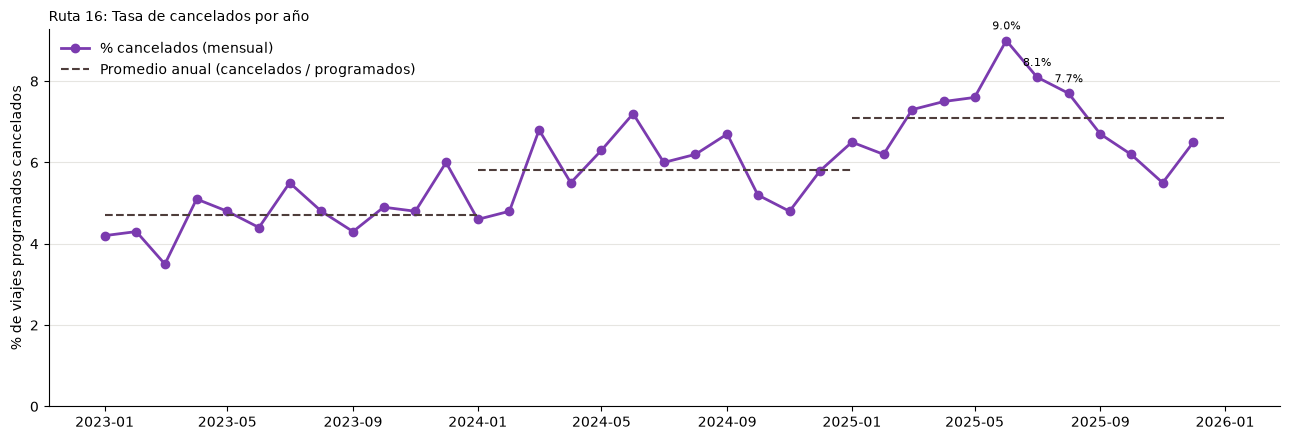

In [26]:
# agrupa por año y mes - agrega la columna programadas y cuenta cuantos viajes se hicieron - agrega cancelados cuenta los viajes que se cancelaron
mm = d16.groupby(d16["fecha_operativa"].dt.to_period("M")).agg(programados=("idprogramacion", "size"), cancelados=("estado_viaje", lambda x: (x == "cancelado").sum()))

# agrega porcentaje cancelados - cancelados / viajes_totales (programados)
mm["% cancelados"] = (mm["cancelados"] / mm["programados"] * 100).round(1)
mm_vista = mm.reset_index().rename(columns={"fecha_operativa": "Mes", "programados": "Programados", "cancelados": "Cancelados"})
mm_vista["Mes"] = mm_vista["Mes"].astype(str)


# Viajes por dia de la semana, normalizado: total de viajes / numero de fechas distintas de ese dia
dd = d16.groupby(d16["fecha_operativa"].dt.dayofweek).agg(viajes=("idprogramacion", "size"), fechas=("fecha_operativa", "nunique"))
dd["viajes_por_dia"] = (dd["viajes"] / dd["fechas"]).round(0)
dd.index = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]

# Serie mensual del % de cancelados, con el promedio anual como referencia
x = mm.index.to_timestamp()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(x, mm["% cancelados"], color=COLOR, marker="o", linewidth=2, label="% cancelados (mensual)")
anual = mm.groupby(mm.index.year)[["cancelados", "programados"]].sum()
anual["pct"] = anual["cancelados"] / anual["programados"] * 100
[ax.hlines(r["pct"], pd.Timestamp(str(a) + "-01-01"), pd.Timestamp(str(a) + "-12-31"), color="#4e3d3b", linestyles="--", linewidth=1.5) for a, r in anual.iterrows()]
ax.plot([], [], color="#4e3d3b", linestyle="--", label="Promedio anual (cancelados / programados)")

# Anota los 3 meses mas altos
top = mm["% cancelados"].nlargest(3)
[ax.annotate(str(v) + "%", (k.to_timestamp(), v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8) for k, v in top.items()]
ax.set_ylim(0, None)
ax.set_ylabel("% de viajes programados cancelados")
ax.set_title("Ruta 16: Tasa de cancelados por año", loc="left", fontsize=10)
[ax.spines[s].set_visible(False) for s in ["top", "right"]]
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

La gráfica muestra el porcentaje mensual de viajes programados que fueron cancelados en la ruta 16 (2023-2025), con el promedio de cada año como referencia.

* **El promedio anual sube cada año** (4.7% en 2023, 5.8% en 2024 y 7.1% en 2025), el máximo mensual es junio de 2025 (9.0%) y el mínimo es marzo de 2023 (3.5%).

* **Dentro de cada año la serie mensual sube y baja, no crece de forma continua**, en 2025, por ejemplo, el valor llega a 9.0% en junio y baja hasta cerca de 5.5% en noviembre. Por eso conviene hablar de un nivel más alto cada año, no de un ascenso mes a mes.

* **Los tres meses con más cancelación en 2025 son junio (9.0%), julio (8.1%) y agosto (7.7%)**, np se conoce la causa.

* **Cautela de interpretación:** casi todas las cancelaciones están registradas como "cancelada automáticamente" (44,150 de 44,156 en la base). No se sabe qué regla las genera, así que el aumento corresponde a cancelaciones registradas y no necesariamente a un empeoramiento de la operación.

##### **Días sin viaje**

Veamos más a detalle si existen registros de días sin viaje.

In [27]:
# Fechas del periodo 2023-2025 en las que la ruta 16 no tiene ningun viaje
todas = pd.date_range("2023-01-01", "2025-12-31") 
# devuelve los elementos que están en todas pero no en el segundo índice
sin = todas.difference(pd.DatetimeIndex(d16["fecha_operativa"].unique())) # toma los valores distintos
print("dias sin viajes:", len(sin))
print(list(sin.strftime("%Y-%m-%d")))

dias sin viajes: 0
[]


No existen registros durantes los tres años (2023-2025) en el que no se haya registrado algún viaje. Se cuenta con una cobertura diaria completa.

##### **Confirmación con la tabla de timbrados**

In [28]:
ruta_ta = "data/raw/timbradas_anio.csv"   
ta = pd.read_csv(ruta_ta, parse_dates=["ultima_actualizacion"])

for col in ["hora", "hora_inicio", "hora_fin"]:
    ta[col] = pd.to_timedelta(ta[col])

In [29]:
print(ta.columns.tolist(), ta["id_ruta"].unique(), ta["ano"].unique()) # imprimimos las columnas, las rutas únicas, y los años únicos.

# extreme por anio para la ruta 16, sin 2026 (parcial)
# filtramos por ruta 16 y quitamos el año 2026
# agrupamos por año y agregamos la columna viajes_ext que es la suma del número de viajes y pax_ext es el total de la suma de subidas.
ext_a = ta[(ta["id_ruta"] == 16) & (ta["ano"] <= 2025)].groupby("ano").agg(viajes_ext=("nro_viajes", "sum"), pax_ext=("subidas", "sum"))

# nuestros viajes finalizados por anio (fecha de salida) y sus pasajeros
fin = d16[d16["estado_viaje"] == "finalizado"]
nuestro = fin.groupby(fin["fecha_operativa"].dt.year).agg(finalizados=("idprogramacion", "size"), pax=("numeropasajeros", "sum"))
c = ext_a.join(nuestro)

c["viajes_ext/finalizados"] = (c["viajes_ext"] / c["finalizados"]).round(3)
c["pax_ext/pax"] = (c["pax_ext"] / c["pax"]).round(3)
# Copia para mostrar: la tabla c original no se toca

c_vista = c.copy()
c_vista.columns.name = None
# El anio pasa de indice a columna, para que se vea con showIndex=False
c_vista = c_vista.reset_index().rename(columns={"ano": "Año", "viajes_ext": "Viajes Extreme", "pax_ext": "Pasajeros Extreme", "finalizados": "Viajes finalizados (propios)", "pax": "Pasajeros (propios)", "viajes_ext/finalizados": "Razón viajes (Extreme / propios)", "pax_ext/pax": "Razón pasajeros (Extreme / propios)"})
c_vista["Año"] = c_vista["Año"].astype(str)
# Enteros con separador de miles (quita el .0)
cols_enteros = ["Viajes Extreme", "Pasajeros Extreme", "Viajes finalizados (propios)", "Pasajeros (propios)"]
c_vista = c_vista.assign(**{k: c_vista[k].round(0).astype(int).map("{:,}".format) for k in cols_enteros})
display(c_vista, paging=False, searching=False, ordering=False, info=False, dom="t", showIndex=False)

['id_timbrada_anio', 'proceso', 'ano', 'id_ruta', 'id_dia_semana', 'id_estacionalidad_anio', 'hora', 'hora_inicio', 'hora_fin', 'subidas', 'bajadas', 'nro_viajes', 'promedio_subidas', 'promedio_bajadas', 'ultima_actualizacion'] [ 2 16 21] [2023 2024 2025 2026]


Año Viajes Extreme Pasajeros Extreme Viajes finalizados (propios)  \
0  2023        102,784         8,774,466                       99,395   
1  2024         96,186         8,075,734                       93,148   
2  2025         94,084         7,469,245                       90,143   

  Pasajeros (propios)  Razón viajes (Extreme / propios)  \
0           8,516,617                             1.034   
1           7,811,111                             1.033   
2           7,181,431                             1.044   

   Razón pasajeros (Extreme / propios)  
0                                1.030  
1                                1.034  
2                                1.040

Como vemos, el conteo de viajes de Extreme (`timbradas_anio`) supera al propio en 3.3% a 4.4%, dentro de lo esperado.

##### **Hallazgos: La oferta de la ruta 16 baja entre 2023 y 2025.** 

* Los viajes programados caen 7.0% (104,327 de 97,033) y los finalizados 9.3% (99,395 de 90,143).

* La cancelación registrada sube de 4.7% a 5.8% y a 7.1%, con un pico de 9.0% en junio de 2025. Casi todas son "cancelada automáticamente" y se desconoce la regla.

* Los viajes cortos y parciales crecen cada año (parciales: 498 de 1,201).

*

* La cobertura diaria es completa: ningún día sin viajes en 2023–2025.

* Se marcan 8 semanas con servicio bajo; donde 6 de estas puede ser debido a que esa semana hay festividades, mientras que otras 2 no se les puede atribuir ninguna causa.

**Decisión:** la serie principal usa los viajes completos; cancelados, cortos y parciales se reportan aparte.

#### **Demanda**

En esta sección, la usaremos para entender cuántos pasajeros hay, cuándo y con qué variabilidad. Verificar si cambio la demanda comparada con la oferta de los resultados anteriores.

In [30]:
def hist_por_grupo(tabla, columna, grupo, colores, rango=(0, 430), bins=60, titulo="", xlabel="", densidad=False):
    # histogramas superpuestos de una columna, uno por cada valor de 'grupo' (por ejemplo, anio)
    fig, ax = plt.subplots(figsize=(11, 4))         # crea figura y eje
    for g, color in colores.items():                # recorre cada grupo y su color
        x = tabla.loc[tabla[grupo] == g, columna].dropna()   # valores del grupo, sin nulos
        fuera = ((x < rango[0]) | (x > rango[1])).sum()      # cuenta valores fuera del rango
        if fuera > 0:
            print(f"{g}: {fuera} valores fuera del rango {rango} no se dibujan")   # avisa
        ax.hist(x, bins=bins, range=rango, alpha=0.5,        # dibuja el histograma del grupo
                color=color, label=str(g), density=densidad)
    ax.set_xlabel(xlabel or columna)                         # etiqueta eje X
    ax.set_ylabel("proporción de viajes" if densidad else "Viajes")   # etiqueta eje Y según densidad
    ax.legend(frameon=False)                                 # leyenda sin marco
    ax.set_title(titulo, loc="left", fontsize=10)            # título alineado a la izquierda
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)                      # quita marcos superior y derecho
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)        # grilla horizontal suave
    ax.set_axisbelow(True)                                   # grilla detrás de las barras
    plt.tight_layout()                                       # ajusta márgenes
    plt.show()                                               # muestra el gráfico

##### **Distribución de pasajeros por tipo de viaje y por año**

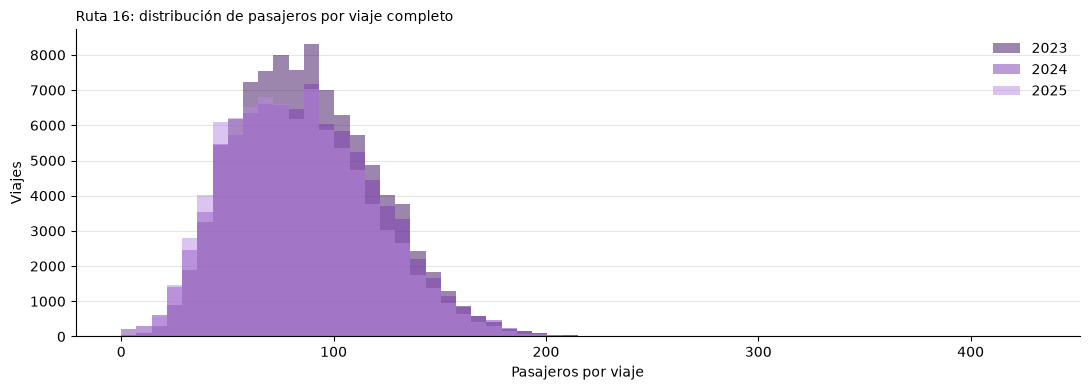

Año  Viajes  Media  Desv. estándar  Mínimo    P5   P25  Mediana    P75  \
0  2023  96,459   88.1            33.0     0.0  39.0  63.0     85.0  110.0   
1  2024  88,986   86.5            34.9     0.0  34.0  60.0     84.0  110.0   
2  2025  85,619   83.1            33.3     0.0  34.0  58.0     80.0  105.0   

     P95  Máximo  Asimetría Pasajeros totales  
0  146.0   351.0       0.44         8,501,163  
1  147.0   413.0       0.38         7,697,503  
2  142.0   267.0       0.43         7,114,408

In [31]:
aptos = df_progvehiculos_16[df_progvehiculos_16["apto_demanda"]].copy() # solo tiene en cuenta aquellos que son aptos para demanda

aptos["anio"] = aptos["fecha_operativa"].dt.year # convertimos el año en el año de la fecha en la que opero.

# agrupamos por año y calculamos los percentijes para cada año.
resumen = aptos.groupby("anio")["numeropasajeros"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1)
resumen["asimetria"] = aptos.groupby("anio")["numeropasajeros"].skew().round(2)
resumen["pasajeros_totales"] = aptos.groupby("anio")["numeropasajeros"].sum()

# copia para mostrar: la tabla resumen original no se toca
resumen_vista = resumen.copy()
resumen_vista.columns.name = None
# El anio pasa de indice a columna, para que se vea con showIndex=False
resumen_vista = resumen_vista.reset_index().rename(columns={"anio": "Año", "count": "Viajes", "mean": "Media", "std": "Desv. estándar", "min": "Mínimo", "5%": "P5", "25%": "P25", "50%": "Mediana", "75%": "P75", "95%": "P95", "max": "Máximo", "asimetria": "Asimetría", "pasajeros_totales": "Pasajeros totales"})
resumen_vista["Año"] = resumen_vista["Año"].astype(str)
# Enteros con separador de miles; el resto queda con un decimal
for k in ["Viajes", "Pasajeros totales"]: resumen_vista[k] = resumen_vista[k].round(0).astype(int).map("{:,}".format)

hist_por_grupo(aptos, "numeropasajeros", "anio", {2023: "#3B0F5C", 2024: "#7B3BAF", 2025: "#B98AE0"}, titulo="Ruta 16: distribución de pasajeros por viaje completo", xlabel="Pasajeros por viaje")

display(resumen_vista, paging=False, searching=False, ordering=False, info=False, dom="t", showIndex=False)


La distribución de pasajeros por viaje completo (ruta 16) es asimétrica hacia la derecha en los tres años (asimetría de 0.44, 0.38 y 0.43; la media supera a la mediana). Otros puntos para destacar:

* **Nivel y variabilidad.** En 2023 un viaje lleva en promedio 88.1 pasajeros, con desviación estándar de 33.0; es decir, un coeficiente de variación de 37.5%. Entre el 5% y el 95% de los viajes, los pasajeros van de 39 a 146.

* **Los pasajeros por viaje bajan.** La media pasa de 88.1 a 83.1 (5.7%) y la mediana de 85 a 80 (5.9%) entre 2023 y 2025. La caída es mayor en la parte baja de la distribución (P5 pasa de 39 a 34, reducción de 12.8%) que en la alta (P95 de 146 a 142, reducción de 2.7%). Esto sugiere un cambio en la demanda y no solo en la oferta.

* **Valores extremos.** El mínimo es 0 pasajeros en los tres años (viajes completos sin subidas registradas); el estado de estos datos se revisa por separado. El máximo es 413 pasajeros en un viaje de 2024, unas tres veces el P95 de ese año, lo cual es apto para revisión.

* **Pasajeros totales.** Pasan de 8,501,163 (2023) a 7,114,408 (2025), una reducción de 16.3%. Combina menos viajes completos con dato (11.2%, de 96,459 a 85,619) y menos pasajeros por viaje (5.7%).

Ahora que ya analizamos la cantidad de pasajeros por año, vamos a separar por viajes completos pero aquellos casos aislados: con cero subidas pero sí bajadas, con cero bajadas pero sí subidas, y aquellos valores que están nulos.

In [32]:
cat = d16["categoria_embudo"].astype(str)  # extraemos solo la columna categoria_embudo
comp = d16[cat.str.startswith(("5)", "6)", "7)"))].copy()  # selecciona solo las categorias 5, 6 y 7 (viajes completos)

# agrega anio como el año de la fecha operativa
comp["anio"] = comp["fecha_operativa"].dt.year

# nombra el estado del dato de pasajeros segun las marcas del ETL
comp["estado_pax"] = np.select([comp["pax_vacio"], comp["cero_con_bajadas"], comp["cero_sin_bajadas"]], ["Vacio (sin dato)", "Cero con bajadas", "Cero sin bajadas"], default="Con pasajeros")

# cuantos hay de cada estado y porcentaje con problema, por año
t = comp.groupby(["anio", "estado_pax"]).size().unstack(fill_value=0)  # estados como columnas
t["total"] = t.sum(axis=1)  # total de viajes completos
t["% problema"] = ((t["total"] - t["Con pasajeros"]) / t["total"] * 100).round(2)  # porcentaje con problema
tabla_bonita(t, {"anio": "Año", "total": "Total", "% problema": "% con problema"}, miles=["Con pasajeros", "Total"], como_texto=["Año"], decimales=2)


De acuerdo a los resultados anteriores, podemos destacar: 

* De 271,463 viajes completos, 478 (0.18%) tienen el dato de pasajeros vacío o en cero. La tasa de problema es de 0.04% en 2023, 0.42% en 2024 y 0.08% en 2025, lo que deja en evidencia que en 2024 se concentra la mayoría de los casos (371 de 478).

* En 2024 el aumento se debe sobre todo a pasajeros vacíos (326, contra 31 y 39 en 2023 y 2025), mientras que en 2025 destacan los ceros con bajadas (20, contra 4 y 3). No se conoce realmente la causa; sin embargo, se tratará de hacer un análisis por mes, por vehículo para ver si se tratan de casos aislados a pocos meses o a pocos vehículos.

**Decisión:** los vacíos quedan fuera de la demanda; los ceros se conservan con marca hasta aclarar su origen.

Ahora, nos centraremos más que todo en el año 2024 ya que abarca el 77% de los casos anomalos.

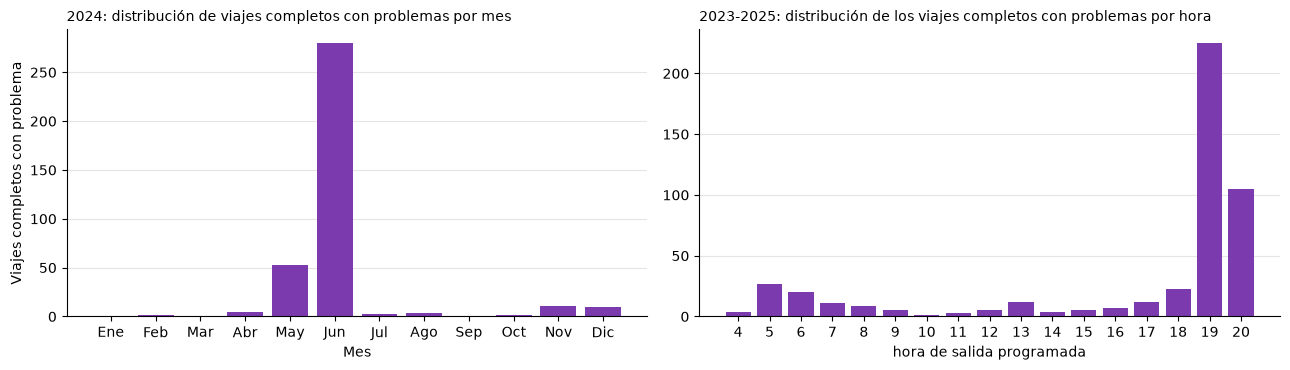

Buses con problema: 112 de 291 | maximo por bus: 16 casos | 10 con mas casos: 21.1% | 25 con mas casos: 43.9%


In [33]:
# casos con problema: deja afuera los que tienen pasajeros
prob = comp[comp["estado_pax"] != "Con pasajeros"]

# casos con problema en 2024, por mes (los meses sin casos aparecen con 0)
p24 = prob[prob["anio"] == 2024]
m24 = p24.groupby(p24["fecha_operativa"].dt.month).size().reindex(range(1, 13), fill_value=0).rename("Casos").rename_axis("Mes").to_frame()
m24["% del año"] = (m24["Casos"] / m24["Casos"].sum() * 100).round(1)

# hora de salida de los casos con problema (hora programada)
h = prob.groupby(prob["fechasalida"].dt.hour).size().rename("Casos").rename_axis("Hora").to_frame()
h["% del total"] = (h["Casos"] / h["Casos"].sum() * 100).round(1)

# Figura de dos paneles: casos por mes (2024) y por hora de salida (2023-2025)

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(m24.index.astype(str), m24["Casos"], color="#7B3BAF")
axes[0].set_xticks(range(len(m24)))
axes[0].set_xticklabels([meses[int(m) - 1] for m in m24.index])
axes[0].set_title("2024: distribución de viajes completos con problemas por mes",
                  loc="left", fontsize=10)
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Viajes completos con problema")

hh = h["Casos"].reindex(range(4, 21), fill_value=0)
axes[1].bar(hh.index.astype(str), hh.values, color="#7B3BAF")
axes[1].set_title("2023-2025: distribución de los viajes completos con problemas por hora", loc="left", fontsize=10)
axes[1].set_xlabel("hora de salida programada")
[[ax.spines[s].set_visible(False) for s in ["top", "right"]] for ax in axes]
[ax.grid(axis="y", color="#e6e5e1", linewidth=0.8) for ax in axes]
[ax.set_axisbelow(True) for ax in axes]
plt.tight_layout(); plt.show()


# concentracion por vehiculo: si pocos buses explican muchos casos, parece falla de sensor
v = prob["idvehiculo"].value_counts().rename("Casos").rename_axis("Vehículo").to_frame()  # casos por vehiculo
v["% acumulado"] = (v["Casos"].cumsum() / v["Casos"].sum() * 100).round(1)
# Resumen de concentracion por vehiculo 
print(f"Buses con problema: {len(v)} de {comp['idvehiculo'].nunique()} | maximo por bus: {v['Casos'].max()} casos | 10 con mas casos: {v['% acumulado'].iloc[9]}% | 25 con mas casos: {v['% acumulado'].iloc[24]}%")
# Los 112 vehiculos completos, en una tabla de 300 px que se desplaza (ya no hace falta el head(15))
tabla_bonita(v, como_texto=["Vehículo"], alto="200px", ordenar=True)


**Concentración temporal.** En 2024, junio concentra 280 de los 371 casos con problema en el dato de pasajeros (75.5%), seguido de mayo con 53 (14.3%). Aun no es posible determinar la causa.

**Concentración por hora.** Las salidas de las 19 h y las 20 h (de 7:00 a 8:59 pm) acumulan 330 de 478 casos (69.0%) en 2023-2025. Falta verificar si corresponden a mayo y junio de 2024. Estas son de las últimas salidas del día en la ruta, y se prueba si hay relación con el cierre tardío de viajes.

**Concentración por vehículo.** El problema aparece en 112 de 291 buses (38.5%) y el máximo por bus es 16 casos. Los 25 buses con más casos acumulan 43.9%. No hay un bus que explique el problema, lo que descarta un fallo aislado de sensor. Falta comparar la tasa por bus con sus viajes completos.

**Decisión:** se marcan y se excluyen del entrenamiento; no se imputan.
 

In [34]:
# Bajadas: viajes 'cero con bajadas' frente a viajes con pasajeros (misma variable en ambos)
cb = comp[comp["estado_pax"] == "Cero con bajadas"]
nor = comp[comp["estado_pax"] == "Con pasajeros"]
cmpb = pd.DataFrame({"Cero con bajadas": cb["numerobajadas"].describe(), "Viajes con pasajeros": nor["numerobajadas"].describe()}).round(1)
tabla_bonita(cmpb, {"index": "Estadístico"})
# En viajes normales: relacion entre bajadas y subidas (si no es cercana a 1, las bajadas no sirven como reemplazo)
# Duracion de los viajes con problema frente a los normales, solo salidas de las 19 y 20 h de 2024
c24 = comp[comp["anio"] == 2024]
h2 = c24[c24["fechasalida"].dt.hour.isin([19, 20])]
dur = pd.DataFrame({"Con problema": h2[h2["estado_pax"] != "Con pasajeros"]["dur_min"].describe(), "Sin problema": h2[h2["estado_pax"] == "Con pasajeros"]["dur_min"].describe()}).round(1)
tabla_bonita(dur, {"index": "Estadístico"})

En los viajes con cero subidas hay bajadas (mediana de 57, media de 63.5), por lo que hubo gente a bordo y no parecen viajes vacíos. Sus bajadas son menores que las de un viaje con pasajeros (mediana de 57 frente a 82; P25 de 40.5 frente a 60; P75 de 93 frente a 106). Se interpreta como un posible fallo de registro de subidas, pero no se usa la columna de bajadas para reemplazar las subidas, porque en la base hay valores imposibles (hasta 555,778 bajadas en un viaje) y su consistencia no está comprobada. 

**Decisión:** se marcan y se excluyen del entrenamiento; no se imputan.

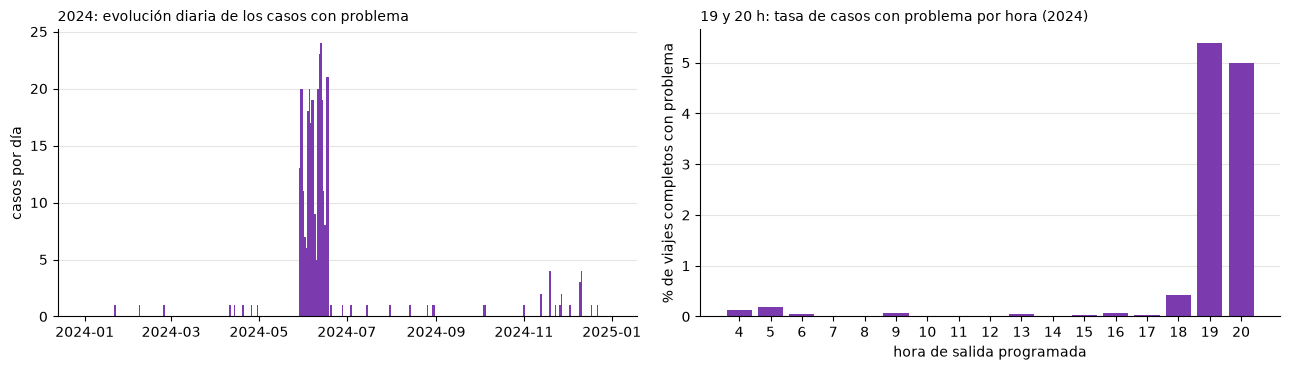

In [35]:
# Base 2024: viajes completos y casos con problema
c24 = comp[comp["anio"] == 2024]
p24 = c24[c24["estado_pax"] != "Con pasajeros"]
# Casos por dia (todos los dias de 2024, con 0 donde no hubo)
dias = p24.groupby(p24["fecha_operativa"].dt.normalize()).size().reindex(pd.date_range("2024-01-01", "2024-12-31"), fill_value=0)
# Tasa de problema por hora de salida: casos entre viajes completos de esa hora
tasa_h = (p24.groupby(p24["fechasalida"].dt.hour).size() / c24.groupby(c24["fechasalida"].dt.hour).size() * 100).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(dias.index, dias.values, width=1.0, color=COLOR)
axes[0].set_title("2024: evolución diaria de los casos con problema", loc="left", fontsize=10)
axes[0].set_ylabel("casos por día")
axes[1].bar(tasa_h.index.astype(str), tasa_h.values, color=COLOR)
axes[1].set_title("19 y 20 h: tasa de casos con problema por hora (2024)", loc="left", fontsize=10)
axes[1].set_xlabel("hora de salida programada"); axes[1].set_ylabel("% de viajes completos con problema")
[[ax.spines[s].set_visible(False) for s in ["top", "right"]] for ax in axes]
[ax.grid(axis="y", color="#e6e5e1", linewidth=0.8) for ax in axes]
[ax.set_axisbelow(True) for ax in axes]
plt.tight_layout(); plt.show()

# Solo los dias con casos, de mayor a menor, con % y % acumulado
dias_tab = dias[dias > 0].sort_values(ascending=False).rename("Casos").rename_axis("Fecha").to_frame()
dias_tab["% del año"] = (dias_tab["Casos"] / dias_tab["Casos"].sum() * 100).round(1)
dias_tab["% acumulado"] = (dias_tab["Casos"].cumsum() / dias_tab["Casos"].sum() * 100).round(1)
# La fecha como texto AAAA-MM-DD (sin la hora 00:00:00)
dias_tab.index = dias_tab.index.strftime("%Y-%m-%d").rename("Fecha")
tabla_bonita(dias_tab, alto="300px", ordenar=True)

* **Los casos casi no aparecen durante el año:** hay días aislados con 1 caso entre enero y octubre. Se concentran en una ventana de unas tres semanas, desde finales de mayo hasta mediados de junio, con entre 5 y 24 casos por día; el máximo es de 24 casos el 13 de junio. Mayo y junio suman 333 de los 371 casos del año (89.8%) y los 10 días con más casos suman 55.8%. En noviembre y diciembre hay un grupo menor, de hasta 4 casos por día (21 casos entre los dos meses).

* **El problema está en las salidas de la tarde-noche**:** a las 19 h el 5.39% de los viajes completos tiene problema y a las 20 h el 4.99%, frente a 0.42% a las 18 h y 0.18% o menos en el resto de horas. En mayo y junio, las salidas de las 18 a 20 h reúnen 326 de los 333 casos (97.9%).

* *Se podría decir que el problema es temporal (una ventana corta) y horario (últimas salidas del día), y no está concentrado en pocos buses (112 de 291 buses afectados, máximo de 16 casos por bus). Esto sugiere una causa común, no un fallo individual de sensor. La causa se desconoce y se comentará como una duda a Extreme.

##### **Pasajeros por viaje según día y hora de salida**

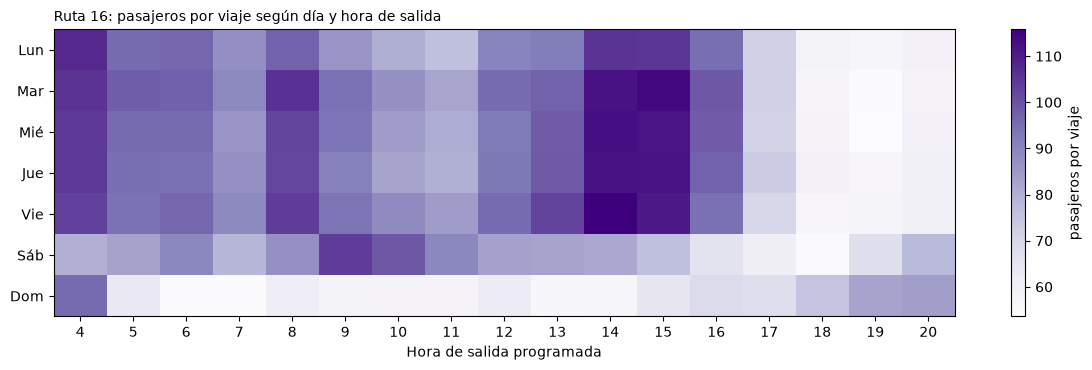

In [36]:
a = d16[d16["apto_demanda"]].copy() # escogemos aquellos que son aptos para la demanda.

a["hora"] = a["fechasalida"].dt.hour # escogemos la hora de SALIDA (la programada)

a["dow"] = a["fecha_operativa"].dt.dayofweek # dia de la semana de la fecha operativa

mapa = a.pivot_table(index="dow", columns="hora", values="numeropasajeros", aggfunc="mean")
mapa.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"] # cambia el nombre de las columnas

# graficamos mapa de calor
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(mapa.values, aspect="auto", cmap="Purples")
ax.set_xticks(range(len(mapa.columns))); ax.set_xticklabels(mapa.columns)
ax.set_yticks(range(len(mapa.index))); ax.set_yticklabels(mapa.index)
fig.colorbar(im, ax=ax, label="pasajeros por viaje")
ax.set_xlabel("Hora de salida programada")
ax.set_title("Ruta 16: pasajeros por viaje según día y hora de salida", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
tabla_bonita(mapa.round(0).astype(int).reset_index().rename(columns={"index": "Día"}), decimales=0, alto="200px")

El gráfico anterior muestra un mapa de calor de los pasajeros por viaje según día y hora de salida; cabe aclarar que en este no se separan los días laborales, sábados ni domingos/festivos. Los días de semana (lunes a viernes) se parecen entre sí, con diferencias de hasta unos 10 pasajeros en una misma hora; los valores más altos están a las 14 y 15 h (entre 105 y 116 pasajeros por viaje) y a las 4 h (103 a 107). El perfil no baja de forma continua: hay un descenso hacia las 7 h y las 11 h, un repunte a las 8 h y a las 14-15 h, y una caída fuerte desde las 16 h hasta entre 54 y 57 pasajeros a las 19 h. Los sábados quedan por debajo de los días de semana en la mayoría de las horas, pero los superan entre las 9 y las 11 h (89 a 104) y a las 19-20 h (67 a 77). 

Los domingos tienen el menor promedio entre las 5 y las 15 h (54 a 65), pero suben desde las 17 h (67) hasta las 20 h (84), un valor solo superado ese día por las 4 h (96). Se expresa o se ve como una subida progresiva de la tarde que como un pico aislado, podría deberse a el regreso de fin de semana.

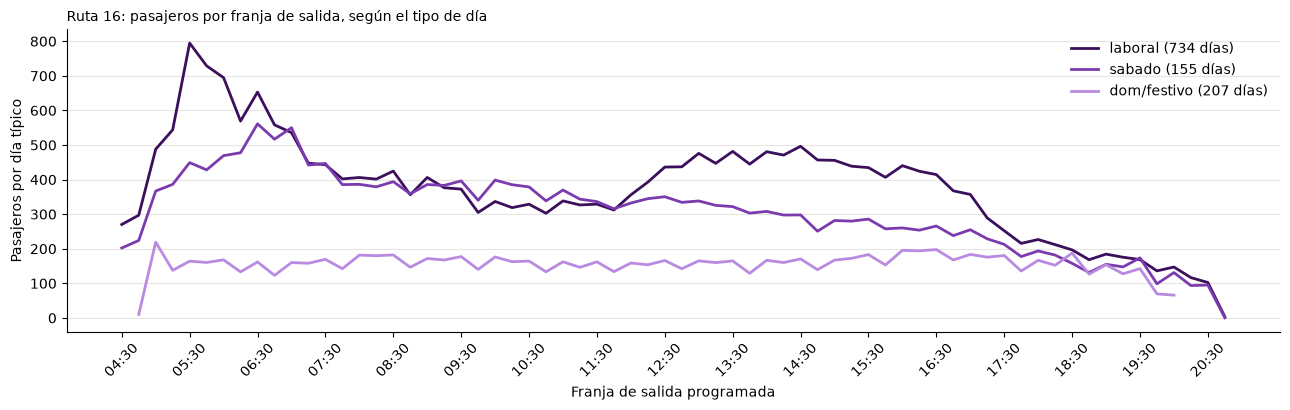

In [37]:
os.makedirs("ResultadosEDA", exist_ok=True)

# tipo de dia en 3 grupos: laborales, sábados, domingos/festivos
dd = d16.copy()
dd["td"] = dd["tipo_dia"].replace({"domingo": "dom/festivo", "festivo": "dom/festivo"}) # juntamos domingo y festivo

dd["franja"] = dd["franja_15"].dt.strftime("%H:%M") # pasamos a formato

n_dias = dd.groupby("td")["fecha_operativa"].nunique() # agrupamos por tipo y cuenta cuantos días diferentes hay

# oferta: salidas reales por franja (apto_intervalo)
sal = dd[dd["apto_intervalo"]].groupby(["td", "franja"]).size().rename("salidas") # agrupamos a aquellos que son aptos para intervalo por tipo de día y franja y contamos cuantos salidas tuvieron

# demanda: viajes aptos y pasajeros por franja (apto_demanda)
dem_f = dd[dd["apto_demanda"]].groupby(["td", "franja"])["numeropasajeros"].agg(viajes="size", pax="sum", media="mean", desv="std") # lo mismo para la demanda.

perfil = pd.concat([sal, dem_f], axis=1).reset_index() # juntamos los dos dataframes
perfil["salidas_dia"] = perfil["salidas"] / perfil["td"].map(n_dias) # calculamos las salidas por dia
perfil["pax_dia"] = perfil["pax"] / perfil["td"].map(n_dias) # los pasajeros por dia
perfil["cv"] = perfil["desv"] / perfil["media"]
perfil["nivel"] = np.where(perfil["pax_dia"] >= perfil.groupby("td")["pax_dia"].transform(lambda x: x.quantile(0.75)), "pico", "valle")
perfil.to_csv("ResultadosEDA/s5_ruta16_perfil_franja_tipodia.csv", index=False)

# pasajeros por dia tipico segun la franja de salida
pv = perfil.pivot(index="franja", columns="td", values="pax_dia")
colores_td = {"laboral": "#3B0F5C", "sabado": "#7B3BAF", "dom/festivo": "#B98AE0"}
fig, ax = plt.subplots(figsize=(13, 4.2))
for g, c in colores_td.items(): ax.plot(range(len(pv)), pv[g].values, color=c, linewidth=2, label=g + " (" + str(n_dias[g]) + " días)")
ax.set_xticks(range(0, len(pv), 4)); ax.set_xticklabels(pv.index[::4], rotation=45)
ax.set_xlabel("Franja de salida programada"); ax.set_ylabel("Pasajeros por día típico"); ax.legend(frameon=False)
ax.set_title("Ruta 16: pasajeros por franja de salida, según el tipo de día", loc="left", fontsize=10)
[ax.spines[s].set_visible(False) for s in ["top", "right"]]
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
# Las 5 franjas con mas pasajeros en cada tipo de dia
# Tabla completa del perfil (todas las franjas de los tres tipos de dia), con scroll y ordenable
completo = perfil.sort_values(["td", "franja"])[["td", "franja", "salidas_dia", "pax_dia", "media", "cv", "nivel"]]
tabla_bonita(completo, {"td": "Tipo de día", "franja": "Franja", "salidas_dia": "Salidas por día", "pax_dia": "Pasajeros por día", "media": "Pasajeros por viaje", "cv": "Variabilidad (CV)", "nivel": "Nivel"}, decimales=2, alto="250px", ordenar=True)

De acuerdo a los resultados, observamos patrones realmente interesantes:

* Se promediaron 734 días laborales, 155 sábados y 207 domingos/festivos, donde cada punto es la suma de pasajeros de los viajes que salen en esa franja en un día típico. Los días laborales tienen un pico muy marcado entre las 05:30 y las 06:30, con un descenso en la franja de las 06:15 (569.3) entre dos puntos altos. El máximo es el de las 05:30: en un día laboral típico, los buses que salen entre las 05:30 y las 05:45 transportan en total 794.77 pasajeros, con 8.75 salidas en esa franja (una cada 1.7 minutos). Cada viaje de esa franja lleva en promedio 92.8 pasajeros. Hay además un tramo entre las 12:30 y las 16:30, con unos 400 a 500 pasajeros por franja.

* Los sábados tienen un perfil intermedio, parecido en forma al de los días laborales por la mañana; el máximo es a las 06:30, con 561.2 pasajeros por día. Entre las 09:00 y las 11:00 quedan por encima de los días laborales y de los domingos, siendo el día con más pasajeros en ese tramo; por la tarde quedan por debajo de los días laborales.

* El perfil de los domingos y festivos es casi plano durante el día, con unos 130 a 200 pasajeros por franja y un máximo de 219.1 a las 05:00. El pico laboral es 3.6 veces ese máximo. Como este grupo mezcla domingos con festivos entre semana, el promedio puede esconder diferencias entre ambos.

* Desde aproximadamente las 18:00 las tres curvas se acercan, el total por franja cae a casi cero al final del día porque casi no hay salidas (0.1 por día a las 20:45), no porque los viajes vayan vacíos.

* En el pico laboral de las 05:30 el coeficiente de variación de los pasajeros por viaje es 0.42, mientras que a las 06:15 y a las 06:30 baja a 0.24. Es decir, a las 05:30 los viajes se parecen menos entre sí que en esas franjas. Esta variabilidad es entre viajes, con los tres años juntos.

Hay que tener en cuenta que esta es la demanda de los viajes que salieron, no necesariamente la demanda total. Se podría definir como la demanda observada, hasta que posteriormente se decida cómo definirla. Los pasajeros no atendidos no se pueden calcular con estas tablas.

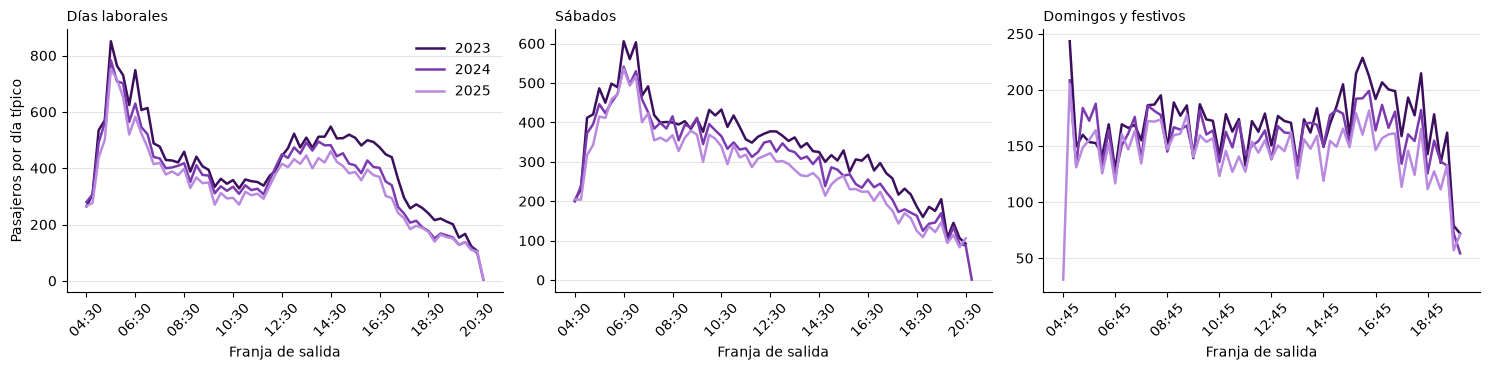

anio            2023     2024     2025
td                                    
dom/festivo  10354.0   9693.0   8946.0
laboral      27258.0  24435.0  22662.0
sabado       22167.0  19956.0  18342.0




            Mañana 05:30-06:45 (% del día)             Tarde 12:30-16:30 (% del día)            
anio                                  2023  2024  2025                          2023  2024  2025
td                                                                                              
dom/festivo                            8.7   9.9   9.6                          29.2  29.5  29.0
laboral                               15.9  16.1  16.5                          31.0  30.9  30.5
sabado                                13.9  14.2  15.2                          25.4  24.9  24.2


In [38]:
# Pasajeros por dia tipico, por anio, tipo de dia y franja (usa dd, creado antes con la columna td)
dd["anio"] = dd["fecha_operativa"].dt.year # desmenuzamos el año

n_dias_a = dd.groupby(["anio", "td"])["fecha_operativa"].nunique() # agrupamos por año y por tipo de día y contamos los días únicos

# los que son aptos para demanda - agrupamos por año tipo de día y franja y calculamos la suma de todos los pasajeros.
pa = dd[dd["apto_demanda"]].groupby(["anio", "td", "franja"])["numeropasajeros"].sum().rename("pax").reset_index()

# calculamos el número de pasajeros por día
pa["pax_dia"] = pa["pax"] / n_dias_a.reindex(pd.MultiIndex.from_frame(pa[["anio", "td"]])).values
colores_anio = {2023: "#3B0F5C", 2024: "#7B3BAF", 2025: "#B98AE0"}
tipos = [("laboral", "Días laborales"), ("sabado", "Sábados"), ("dom/festivo", "Domingos y festivos")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (td, nombre) in zip(axes, tipos):
    pv = pa[pa["td"] == td].pivot(index="franja", columns="anio", values="pax_dia")
    for y, c in colores_anio.items(): ax.plot(range(len(pv)), pv[y].values, color=c, linewidth=1.8, label=str(y))
    ax.set_xticks(range(0, len(pv), 8)); ax.set_xticklabels(pv.index[::8], rotation=45)
    ax.set_title(nombre, loc="left", fontsize=10); ax.set_xlabel("Franja de salida")
    [ax.spines[s].set_visible(False) for s in ["top", "right"]]
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("Pasajeros por día típico"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
# Total de pasajeros por dia tipico y anio (suma de las franjas): el nivel de cada curva
print(pa.groupby(["td", "anio"])["pax_dia"].sum().unstack().round(0).to_string())
print("")

# 1) Correlacion entre los perfiles de 2023 y 2025 (misma franja), por tipo de dia
pv = pa.pivot_table(index=["td", "franja"], columns="anio", values="pax_dia")
# Solo franjas con dato en 2023 y en 2025 (si no, las sumas y la correlacion usarian franjas distintas)
pvc = pv.dropna(subset=[2023, 2025])
comp25 = pd.DataFrame({"Pearson": pvc.groupby("td").apply(lambda x: x[2023].corr(x[2025])), "Spearman": pvc.groupby("td").apply(lambda x: x[2023].rank().corr(x[2025].rank())), "Factor de nivel (2025 / 2023)": pvc.groupby("td").apply(lambda x: x[2025].sum() / x[2023].sum()), "Error si se usa la forma de 2023 reescalada (WAPE %)": pvc.groupby("td").apply(lambda x: (x[2025] - x[2023] * x[2025].sum() / x[2023].sum()).abs().sum() / x[2025].sum() * 100), "Franjas comparadas": pvc.groupby("td").size()})
tabla_bonita(comp25.rename_axis("Tipo de día"), decimales=3)
# Salidas por dia y franja, por anio: ¿el zigzag de dom/festivo viene de la programacion?
sa = dd[dd["apto_intervalo"]].groupby(["anio", "td", "franja"]).size().rename("s").reset_index()
sa["sal_dia"] = sa["s"] / n_dias_a.reindex(pd.MultiIndex.from_frame(sa[["anio", "td"]])).values
sv = sa.pivot_table(index=["td", "franja"], columns="anio", values="sal_dia").dropna(subset=[2023, 2025])
print("")

# 2) Que parte del dia cae en el pico de la manana y en la tarde, por anio
pa["pct_dia"] = pa["pax_dia"] / pa.groupby(["anio", "td"])["pax_dia"].transform("sum") * 100
man = pa[(pa["franja"] >= "05:30") & (pa["franja"] <= "06:45")].groupby(["td", "anio"])["pct_dia"].sum().unstack()
tar = pa[(pa["franja"] >= "12:30") & (pa["franja"] <= "16:30")].groupby(["td", "anio"])["pct_dia"].sum().unstack()
print(pd.concat({"Mañana 05:30-06:45 (% del día)": man, "Tarde 12:30-16:30 (% del día)": tar}, axis=1).round(1).to_string())

De acuerdo a los resultados anteriores se pueden destacar los siguientes puntos:

* **La forma se conserva entre años:** en días laborales y sábados las tres curvas tienen la misma forma y quedan anidadas, con 2023 arriba y 2025 abajo. La correlación entre los perfiles de 2023 y 2025 es de 0.976 en laborales y 0.979 en sábados con Pearson, y de 0.959 y 0.976 con Spearman. Como las dos medidas coinciden, la similitud no depende de unos pocos puntos extremos. Si se usa la forma de 2023 reescalada al nivel de 2025, el error medio ponderado por franja (WAPE) es de 6.7% en laborales y 7.2% en sábados.

* **El nivel baja cada año:** el total por día típico pasa de 27,258 a 24,435 y a 22,662 pasajeros en laborales (−16.9% entre 2023 y 2025); de 22,167 a 19,956 y a 18,342 en sábados (−17.3%); y de 10,354 a 9,693 y a 8,946 en domingos y festivos (−13.6%).

* **La tarde pierde relativamente más que la mañana:** el porcentaje del día que cae en el pico de la mañana sube de 15.9% a 16.5% en laborales y de 13.9% a 15.2% en sábados, mientras el tramo de la tarde baja de 31.0% a 30.5% y de 25.4% a 24.2%. En términos aproximados, la tarde baja entre 18% y 21% y la mañana entre 10% y 14% en laborales y sábados.

* **Domingos y festivos:** la curva es casi plana y más irregular que las otras. La correlación entre 2023 y 2025 es de 0.851 con Pearson y 0.750 con Spearman: alta, aunque menor que en laborales y sábados. Una curva casi plana comparte poca forma entre años, y Spearman, que solo mira el orden de las franjas, es más sensible a diferencias pequeñas. Aun así, el error de usar la forma de 2023 reescalada (7.4%) es parecido al de los otros tipos de día, por lo que su irregularidad no parece hacerla más difícil de aproximar. Se comparan 61 franjas, frente a 65 en los otros días, porque algunas no tienen datos en 2023 o en 2025.

* **Implicación para el modelo.** estos errores son un diagnóstico de la forma, no un error de pronóstico: el factor de nivel (entre 0.83 y 0.86) se calculó con los datos de 2025, que en la práctica no se conocen, por lo que el error de una línea base real será mayor. Un promedio histórico de 2023–2024 sobreestimaría 2025, más en la tarde que en la mañana.

* **Limitaciones.** Es la demanda de los viajes que salieron (demanda observada), no controla efectos de calendario dentro de cada tipo de día, y los domingos y festivos mezclan ambos tipos de día.

##### **Picos observados frente a la expectativa de 17 a 19 h.**

Por franja de salida, los picos observados en la ruta 16 son otros: en días laborales, entre las 05:30 y las 06:30 (máximo de 794.8 pasajeros por día a las 05:30) y un tramo más bajo entre las 12:30 y las 16:30; en sábados, a las 06:30 (561.2). Las salidas de 17:15 a 19:45 llevan pocos pasajeros por viaje (entre 47 y 68 en los martes, frente a 104 a 113 en las salidas de las 14:00 a las 15:00). Esto no descarta un pico de abordaje en la tarde: como cada viaje dura unos 262 a 265 minutos y se asigna a su franja de salida, los pasajeros que suben entre las 17 y las 19 h pueden estar contados en viajes que salieron entre las 14 y las 15 h. La demanda por hora de abordaje no se puede medir con estas tablas, que solo dan pasajeros por viaje completo. Los picos y valles se definen provisionalmente como el 25% de franjas con más pasajeros por día de cada tipo de día.

##### **Dispersión del total por franja y día**

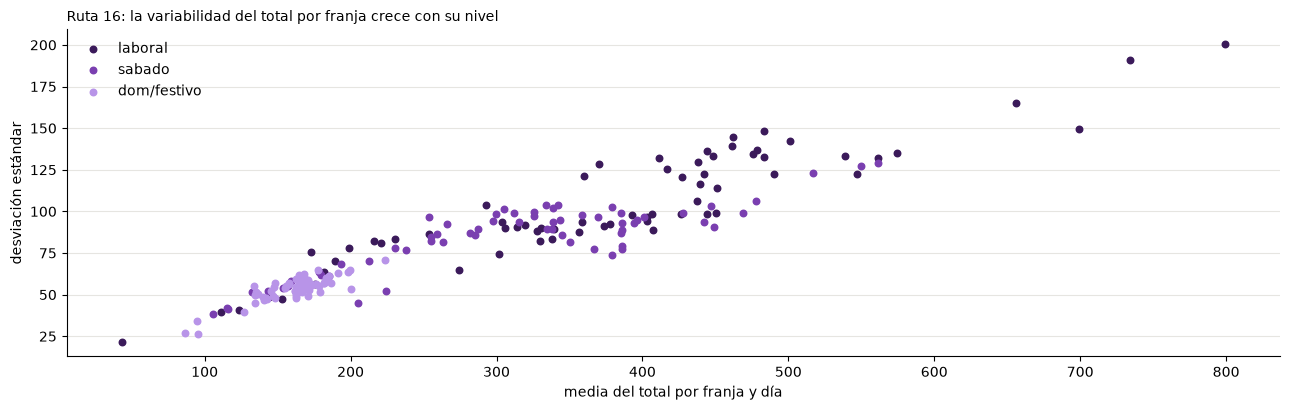

In [45]:
# Total de pasajeros por dia y franja (solo dia-franja con al menos un viaje apto; no se rellenan ceros)
dm = dd[dd["apto_demanda"]].groupby(["td", "anio", "franja", "fecha_operativa"])["numeropasajeros"].agg(pax="sum", viajes="size").reset_index()

# Media, desviacion y CV del total, por tipo de dia y franja (3 anios juntos) y por anio
# aca con los tres años juntos
g = dm.groupby(["td", "franja"])["pax"].agg(media="mean", desv="std", n="size").reset_index()
g["cv"] = g["desv"] / g["media"]

 # aca separamos por año
ga = dm.groupby(["td", "anio", "franja"])["pax"].agg(media="mean", desv="std", n="size").reset_index()
ga["cv"] = ga["desv"] / ga["media"]

# Se exigen al menos 20 observaciones por franja
g20 = g[g["n"] >= 20] # exige más de 20 observaciones por franja. Es decir, más de 20 observaciones.
ga20 = ga[ga["n"] >= 20] # lo hace para el que separa por años

res = pd.DataFrame({"CV mediano (3 años juntos)": g20.groupby("td")["cv"].median()}).join(ga20.pivot_table(index="td", columns="anio", values="cv", aggfunc="median").add_prefix("CV mediano "))
res["Franjas usadas"] = g20.groupby("td").size()
gp = g20[(g20["media"] > 0) & (g20["desv"] > 0)]
res["Pendiente log(var) vs log(media)"] = gp.groupby("td").apply(lambda x: np.polyfit(np.log(x["media"]), np.log(x["desv"] ** 2), 1)[0])

# Media frente a desviacion (una gráfica, un punto por franja)
colores_td = {"laboral": "#3b1a5a", "sabado": "#7a3fb0", "dom/festivo": "#b894e8"}
fig, ax = plt.subplots(figsize=(13, 4.2))
[ax.scatter(g20.loc[g20["td"] == td, "media"], g20.loc[g20["td"] == td, "desv"], color=c, s=22, label=td) for td, c in colores_td.items()]
ax.set_xlabel("media del total por franja y día"); ax.set_ylabel("desviación estándar"); ax.legend(frameon=False)
ax.set_title("Ruta 16: la variabilidad del total por franja crece con su nivel", loc="left", fontsize=10)
[ax.spines[s].set_visible(False) for s in ["top", "right"]]
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()


tabla_bonita(res.rename_axis("Tipo de día"), decimales=2)

#atipicos: z robusto del total frente a la mediana de su propio tipo de dia y franja (se marcan, no se borran)
dm["mediana"] = dm.groupby(["td", "franja"])["pax"].transform("median") # saca la mediana de los pasajeros agrupado por tipo de día y franja
dm["mad"] = dm.groupby(["td", "franja"])["pax"].transform(lambda x: (x - x.median()).abs().median()) # como desvación pero más fuerte
dm["z_rob"] = (dm["pax"] - dm["mediana"]) / (1.4826 * dm["mad"].replace(0, np.nan)) #  z-score robusto
dm["atipico"] = dm["z_rob"].abs() > 3.5 # clasifca como atípico a todo aquel que tenga un z_rob mayor a 3.5
at = dm.groupby("td")["atipico"].agg(atipicos="sum", dia_franjas="size") # agrupa por tipo de dias y cuenta los atipicos
at["% atípicos"] = at["atipicos"] / at["dia_franjas"] * 100 # saca el porcentaje de atipicos
tabla_bonita(at.rename_axis("Tipo de día"), decimales=2) # muestra la tabla

# filtra por solo los atipicos -> ordena -> muestra los 10 primeros
top = dm[dm["atipico"]].sort_values("z_rob", key=abs, ascending=False).head(10)[["td", "franja", "fecha_operativa", "pax", "mediana", "z_rob"]].reset_index(drop=True)
top["fecha_operativa"] = top["fecha_operativa"].dt.strftime("%Y-%m-%d") # convierte el formato
tabla_bonita(top, {"td": "Tipo de día", "franja": "Franja", "fecha_operativa": "Fecha", "pax": "Pasajeros del día-franja", "mediana": "Mediana de esa franja", "z_rob": "Z robusto"}, decimales=1)



Cada punto de la figura es una franja de 15 minutos de un tipo de día, con la media y la desviación estándar de su total diario (al menos 20 días-franja por punto). Destacamos:

* **La desviación crece con el nivel.** Va desde unos 20 a 55 en las franjas de menos de 200 pasajeros hasta unos 200 en la franja de mayor demanda, que es unas 4 veces más que en las bajas.

* **El coeficiente de variación del total es de 0.28 en laborales, 0.30 en sábados y 0.33 en domingos y festivos**. En laborales y sábados es de 0.24 en 2023 y de 0.28 en 2024 y 2025, el mismo patrón de la variabilidad por viaje (37.5%, 40.3% y 40.1%). La pendiente de log(varianza) frente a log(media) es de 1.47 en laborales, 1.23 en sábados y 1.80 en domingos y festivos, pero en este último grupo el rango de medias es estrecho y la estimación es poco fiable.

* **Atípicos.** Con un z robusto mayor que 3.5 respecto de la mediana de su franja, se marcan 120 de 69,461 día-franjas (0.17%). Entre las diez más extremas, siete tienen entre 135 y 155 pasajeros por viaje, cerca o por encima del P95 de pasajeros por viaje (142 a 147 según el año). Tres coinciden con banderas de calendario: 2023-02-18 y 2024-02-10 (días centrales del Carnaval) y 2024-07-20 (festivo que cayó en sábado, con 5 salidas frente a las 2 o 3 habituales de domingos y festivos). Dos son adyacentes a un festivo y no tienen bandera propia (2024-11-12 y 2025-11-16) , y cuatro no tienen causa identificada. El caso más bajo (2024-11-27, 07:30) corresponde a una franja con cinco salidas de las cuales cuatro fueron viajes de menos del 10% del circuito y solo una es un viaje completo con dato; ese día hubo 27 viajes cortos, unas tres veces el promedio diario. Se marcan y no se eliminan.

* **Implicaciones.** Los intervalos de confianza deben ensancharse con el nivel (variabilidad relativa de 28% a 33% por franja de 15 minutos). Con esa variabilidad, un umbral fijo de 15% de error de pronóstico, como el sugerido en la especificación, se superaría con frecuencia aun con un buen modelo en franjas de 15 minutos, por lo que conviene definirlo por horizonte con el área operativa.

##### **Hallazgos de la sección 5 (demanda)**

* **Pasajeros por viaje completo:** la media baja de 88.1 a 83.1 (−5.7%) y la mediana de 85 a 80 (−5.9%) entre 2023 y 2025; la distribución es asimétrica a la derecha (0.44, 0.38 y 0.43) y el coeficiente de variación pasa de 37.5% a 40.3% y a 40.1%.

* **Pasajeros totales de viajes completos con dato:** 8.50 a 7.11 millones (−16.3%); combina menos viajes (−11.2%) y menos pasajeros por viaje (−5.7%).

* **Perfil por franja de salida:** en laborales, pico entre las 05:30 y las 06:30 (794.8 pasajeros por día a las 05:30) y tramo de tarde entre las 12:30 y las 16:30; en sábados, pico a las 06:30 (561.2); en domingos y festivos, perfil casi plano (máximo de 219.1). El pico laboral es 3.6 veces el máximo de domingos y festivos.

* El perfil conserva su forma entre 2023 y 2025 (correlación de Pearson de 0.976, 0.979 y 0.851; Spearman de 0.959, 0.976 y 0.750) y el nivel baja 16.9%, 17.3% y 13.6%. La tarde baja relativamente más que la mañana.

* **Dispersión:** la desviación del total por franja crece con su nivel; CV mediano de 0.28, 0.30 y 0.33; 0.17% de día-franjas atípicas (120 de 69,461), varias en fechas de calendario.

* **Estado del dato de pasajeros:** 478 viajes completos con vacío o cero (0.18%); 2024 concentra el 77.6%, mayo y junio el 89.8% de los de 2024, y las salidas de las 19 y 20 h el 69.0% del total; 112 de 291 buses afectados (sin concentración).

* **Bajadas físicamente imposibles (hasta 555,778 en un viaje):** se marcan, no excluyen demanda.

* Los picos observados por franja de salida no coinciden con la expectativa de 17 a 19 h; los pasajeros de esa hora pueden estar contados en viajes que salieron entre las 14 y las 15 h.

**Decisiones (provisionales)**

1. Variable objetivo: pasajeros por franja de 15 minutos de salida, con pasajeros por salida como apoyo. Provisional sujeto a cambios.

2. La demanda es observada (de los viajes que salieron), no la demanda total.

3. Vacíos fuera de la demanda; ceros con marca; `baj_atipico` solo como marca; atípicos del total: marcar, no borrar.

4. Picos y valles: 25% de franjas con más pasajeros por día de cada tipo de día.

5. Intervalos de confianza que crecen con el nivel; umbral de error por horizonte.

6. Línea base: incorporar el nivel reciente, porque un promedio de 2023–2024 sobreestima 2025.

**Preguntas para Extreme:** causa de los vacíos de mayo a junio de 2024 a las 19 y 20 h; causa de las bajadas imposibles; definición de demanda en la fórmula de buses por hora; umbral de error de pronóstico.

**Pendientes:** contraste con `timbradas_anio` y consolidado (diferido); correlación de salidas por franja entre años (el zigzag de domingos y festivos).

#### **Calendario, estacionalidad y novedades viales**

Se tratara de medir el efecto de festivos, temporadas y novedades viales.

##### **Festivos por evento frente a un domingo normal**

In [40]:
# Total de pasajeros y viajes aptos por fecha, y tipo de dia / dia de la semana de cada fecha
cal_d = d16.groupby("fecha_operativa").agg(tipo_dia=("tipo_dia", "first"), dia=("dia_semana", "first")) # agrupa por fecha operativa y agrega columnas de su tipo de día y su dia de semana: ejemplo - 2023-01-01 -> festivo -> 7 

# agrupa otra vez pr fecha operativa a aquellos aptos para demanda - agrega columna numero pasajeros de esa fecha y cuantos viajes se hizo
tot_d = d16[d16["apto_demanda"]].groupby("fecha_operativa").agg(pax=("numeropasajeros", "sum"), viajes=("idprogramacion", "size"))

# une las dos tablas conservando lo de la izquierda (cal_d)
dias_t = cal_d.join(tot_d, how="left")

# agrupa por tipo de dia (festivo, laboral...) y dia (festivo -> lunes -> cuenta cuantos días hay -> promedio de pasajeros -> viajes promedio)
res = dias_t.groupby(["tipo_dia", "dia"]).agg(dias=("pax", "count"), pax_medio=("pax", "mean"), viajes_medios=("viajes", "mean")).reset_index()

# le añade etiquetas al día
res["dia"] = res["dia"].map({1: "lun", 2: "mar", 3: "mié", 4: "jue", 5: "vie", 6: "sáb", 7: "dom"})

tabla_bonita(res, {"tipo_dia": "Tipo de día", "dia": "Día de la semana", "dias": "Días", "pax_medio": "Pasajeros por día", "viajes_medios": "Viajes aptos por día"}, decimales=0)

De la tabla anterior podemos agrupar, por tipo de día y día de la semana, los pasajeros por día y los viajes aptos por día, con el fin de ver si los festivos se comportan como un domingo, como un sábado o como un día laboral. Hay 734 días laborales, 155 sábados, 154 domingos y 53 festivos.

* Los festivos que caen en lunes son el grupo más numeroso de festivos (34 de 53) y se parecen a los domingos en pasajeros por día (9,031 frente a 9,976, un 9.5% menos) y en viajes aptos por día (150 frente a 162, un 7.4% menos). Note que la cantidad de días es mucho menor en el festivo lunes (34) que en el domingo (154), por lo que el promedio del domingo es más estable.

* **Se observa consistencia entre los días laborales:** los pasajeros por día difieren en menos de 1% (24,691 a 24,883) y los viajes aptos en menos de 2% (269 a 274). Incluso el lunes laboral (24,692) es igual al resto, lo que indica que la diferencia que se veía antes en el lunes se debía a los festivos. Un sábado tiene el 82% de los pasajeros de un lunes laboral y un domingo el 40%.

* Los sábados festivos y los sábados no se comportan de la misma manera: 13,565 pasajeros y 175 viajes aptos frente a 20,156 y 249 (un 33% y un 30% menos). Sin embargo, solo se cuenta con un sábado festivo (el 20 de julio de 2024), por lo que no se puede saber si la diferencia es un efecto real del festivo o algo propio de ese día. Además queda entre un sábado y un domingo: 175 viajes frente a 162 de un domingo, y 77.5 pasajeros por viaje frente a 80.9 de un sábado y 61.6 de un domingo.

* Los demás festivos tienen entre 3 y 7 días: el jueves tiene 9,081 pasajeros (un 9.0% menos que un domingo) y el miércoles, el viernes y el domingo entre un 23% y un 28% menos, por lo que sus promedios no son confiables. No hay festivos en martes en el periodo.

* Si juntamos los 53 festivos, el promedio ponderado es de unos 8.783 pasajeros y 148 viajes aptos por día, alrededor de un 12% y un 8% menos que un domingo normal. 


In [41]:
# cada festivo: fecha, dia de la semana, evento, viajes, pasajeros y diferencia frente a un domingo normal
fest = dias_t[dias_t["tipo_dia"] == "festivo"].copy() # solo selecciona aquellos que son festivo

fest["evento"] = d16.groupby("fecha_operativa")["eventos"].first() # crea una columna llamada evento - agrupa por fecha operativa y escoge lo primero de eventos (novedades)

dom_pax = dias_t.loc[dias_t["tipo_dia"] == "domingo", "pax"].mean() # escoge los días domingos y saca el promedio de todos sus pasajeros
dom_via = dias_t.loc[dias_t["tipo_dia"] == "domingo", "viajes"].mean() # escoge los días domingo y saca el promedio de viajes 

# para cada festivo -> calcula cuánto se desvía del domingo promedio: en pasajeros y en viajes
fest["pax_vs_domingo_%"] = (fest["pax"] / dom_pax - 1) * 100 
fest["viajes_vs_domingo_%"] = (fest["viajes"] / dom_via - 1) * 100

# mapea las columnas
fest["dia"] = fest["dia"].map({1: "lun", 2: "mar", 3: "mié", 4: "jue", 5: "vie", 6: "sáb", 7: "dom"})
fest.index = fest.index.strftime("%Y-%m-%d")
fest.index.name = "Fecha"

# mostramos la tabla
tabla_bonita(fest[["dia", "evento", "viajes", "pax", "viajes_vs_domingo_%", "pax_vs_domingo_%"]], 
             {"dia": "Día", "evento": "Evento", "viajes": "Viajes aptos", "pax": "Pasajeros", "viajes_vs_domingo_%": "Viajes vs domingo normal (%)", "pax_vs_domingo_%": 
              "Pasajeros vs domingo normal (%)"}, decimales=0, alto="350px", ordenar=True)

Según los resultados anteriores, podemos ver que tanto difiere cada festividad de los pasajeros y los viajes promediados de todos los domingos. De manera general, hay una dispersión entre los viajes de un domingo general y los pasajeros. Año Nuevo tiene entre 57% y 78% menos pasajeros que un domingo normal; Navidad, entre 36% y 46% menos; el Viernes Santo, entre 36% y 37% menos; y el Jueves Santo, entre 7% y 12% menos. En los otros 38 días la diferencia está casi siempre entre −17% y +11%, con dos excepciones: el 2024-06-10 (−29%) y el sábado 2024-07-20 (+36%).

Otro punto para anotar es que la oferta no sigue a la demanda, pues en el Viernes Santo los viajes aptos bajan 7% a 13% y los pasajeros 36% a 37%, por lo que cada viaje lleva entre 42 y 46 pasajeros frente a 61.6 de un domingo normal; es un candidato a reducir frecuencia. En Año Nuevo los viajes bajan entre 70% y 86% y cada viaje lleva entre 88 y 99 pasajeros, lo que podría indicar buses más llenos.

In [51]:
# tipo de festivo a partir del nombre del evento (Semana Santa y San Jose coincidente quedan en "Otros festivos")
ev = fest["evento"].fillna("") #  se queda con la columna evento y llena los nulos con ""

# crea columna tipo_festivo -> devuelve True en las filas donde el evento contiene esa frase
# recorre las condiciones en orden y asigna el primer valor cuya condición sea True
fest["tipo_festivo"] = np.select([ev.str.contains("Año Nuevo"), ev.str.contains("Navidad"), ev.str.contains("Viernes Santo"), 
                                  ev.str.contains("Jueves Santo"), 
                                  ev.str.contains("Inmaculada")], ["Año Nuevo", "Navidad", "Viernes Santo", "Jueves Santo", "Inmaculada Concepción"], 
                                  default="Otros festivos")


fest["pax_por_viaje"] = fest["pax"] / fest["viajes"] # calcula el número de pasajeros por viaje
# agrupa por tipo de festivo - cuenta los días - calcula viajes y pasajeros promedio - promedio de los pasajeros por viaje -
ef = fest.groupby("tipo_festivo").agg(dias=("pax", "size"), viajes_medios=("viajes", "mean"), pax_medio=("pax", "mean"), pax_por_viaje=("pax_por_viaje", "mean"), 
                                      efecto_pax_medio=("pax_vs_domingo_%", "mean"), efecto_pax_min=("pax_vs_domingo_%", "min"), 
                                      efecto_pax_max=("pax_vs_domingo_%", "max"), efecto_viajes_medio=("viajes_vs_domingo_%", "mean")).sort_values("efecto_pax_medio").reset_index()

# mostramos tabla
tabla_bonita(ef, {"tipo_festivo": "Tipo de festivo", "dias": "Días", "viajes_medios": "Viajes aptos por día", "pax_medio": "Pasajeros por día", 
                  "pax_por_viaje": "Pasajeros por viaje", "efecto_pax_medio": "Efecto en pasajeros: medio (%)", "efecto_pax_min": "mínimo (%)", 
                  "efecto_pax_max": "máximo (%)", "efecto_viajes_medio": "Efecto en viajes: medio (%)"}, decimales=1)

La tabla anterior muestra el tipo de festivo y su cantidad entre todos los años. Cada año hay navidad, año nuevo, entre otras cosas más, se juntaron para ver la diferencia porcentual de los pasajeros y viajes aptos por día frente al promedio de los domingos normales. Se pueden destacar varias cosas:

* La festividad de Año Nuevo y Navidad son los que menor actividad tienen, pues Año Nuevo cuenta en promedio con 69.5% menos pasajeros y 79.2% menos viajes aptos, frente a Navidad, con un 39.4% menos pasajeros (entre −35.9% y −45.5%) y 40.8% menos viajes. En Año Nuevo los viajes bajan más que los pasajeros y cada viaje lleva en promedio 91.6 pasajeros frente a unos 61 de un domingo normal; en Navidad ambos bajan casi igual (64.0 por viaje).

* El Viernes Santo tiene 36.5% menos pasajeros (entre −37.2% y −36.1%, muy estable entre años) y solo 10.7% menos viajes, con 43.9 pasajeros por viaje. El Jueves Santo tiene 9.1% menos pasajeros y 6.6% más viajes (52.7 por viaje). Son los dos tipos con mayor diferencia entre el efecto en pasajeros y el efecto en viajes (−25.8 y −15.7 puntos porcentuales), por lo que podrían ser candidatos a reducir frecuencia.

* La Inmaculada tiene 17.8% menos pasajeros y 14.4% menos viajes, con valores entre −30.8% y −2.9% según el día de la semana en que cae; los 38 festivos restantes, 3.1% menos pasajeros y 0.8% menos viajes. Entre estos últimos hay dos extremos: el 2024-06-10 (−29.1%), que cae en la ventana de datos vacíos de mayo y junio y puede estar subestimado, y el sábado 2024-07-20 (+36.0%).

* Notemos que hay casos en los que la oferta fue mantenida como un domingo normal, y se vio afectada con pocos pasajeros y más flota operando. Por ejemplo, en el Viernes Santo se mantuvo casi un porcentaje de viajes parecido, pero la demanda, en este caso, los pasajeros por día fue realmente poca, y eso produjo que pasajeros por viaje sea 43, en un circuito que dura 4 horas. Es caso de revisión.

Con lo anterior se podría decir que una marca única de festivo no basta, Año Nuevo, Navidad y Viernes Santo requieren marca propia, y los demás pueden tratarse como un domingo con un ajuste pequeño. Con solo tres días por tipo, estos efectos son descriptivos y no se pueden estimar con precisión

##### **Carnaval, precarnaval y Semana Santa en días normales**

Se comparara aquellos días con evento que no son festivos nacionales: los días centrales del carnaval, el precarnaval y los días de Semana Santa que no son ni Jueves ni Viernes Santo. Cada uno se compara con el promedio de los días normales del mismo año y del mismo día de la semana.

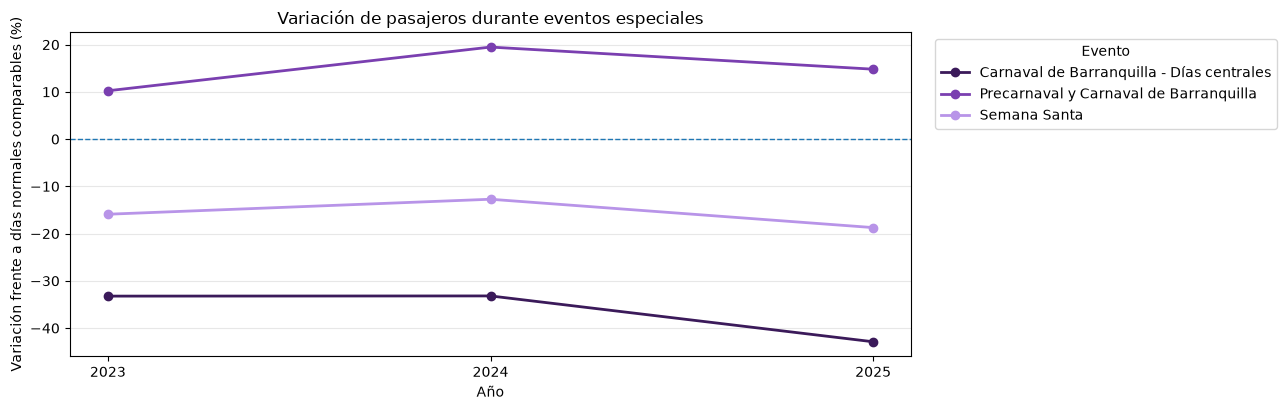

dias de referencia por anio y dia de la semana (minimo): 36


In [119]:
# pasajeros y viajes aptos por fecha, con tipo de dia, dia de la semana y evento

# agrupa por fecha operativa -> saca su tipo de día su día de semana y su evento
cal_d = d16.groupby("fecha_operativa").agg(tipo_dia=("tipo_dia", "first"), dia=("dia_semana", "first"), evento=("eventos", "first"))

# filtra aquellos apto por demanda -> agrupa por fecha operativa -> calcula el número de pasajeros en esa fecha -> calcula el número de viajes
tot_d = d16[d16["apto_demanda"]].groupby("fecha_operativa").agg(pax=("numeropasajeros", "sum"), viajes=("idprogramacion", "size"))

# une ambas tablas por derecha por fecha_operativa
dias_t = cal_d.join(tot_d, how="left")

# agrega la columna año y saca el año
dias_t["anio"] = dias_t.index.year

# referencia: dias normales (sin evento y no festivos), por anio y dia de la semana
# tiene registrad un evento y el tipo de día es distinto de festivo
norm = dias_t[dias_t["evento"].isna() & (dias_t["tipo_dia"] != "festivo")]
# agrupa por año y por dia -> calcula pasajeros, viajes promedio y cuenta el numero de pasajeros.
ref = norm.groupby(["anio", "dia"]).agg(ref_pax=("pax", "mean"), ref_viajes=("viajes", "mean"), n_ref=("pax", "count")).reset_index()


# sias con evento que no son festivos, comparados con su referencia
ev = dias_t[dias_t["evento"].notna() & (dias_t["tipo_dia"] != "festivo")].reset_index().merge(ref, on=["anio", "dia"], how="left")
ev["efecto_pax"] = (ev["pax"] / ev["ref_pax"] - 1) * 100
ev["efecto_viajes"] = (ev["viajes"] / ev["ref_viajes"] - 1) * 100

res = ev.groupby(["evento", "anio"]).agg(dias=("pax", "count"), viajes_medios=("viajes", "mean"), pax_medio=("pax", "mean"),
                                         efecto_pax=("efecto_pax", "mean"), pax_min=("efecto_pax", "min"), pax_max=("efecto_pax", "max"), 
                                         efecto_viajes=("efecto_viajes", "mean")).reset_index()


eventos_interes = [
    "Carnaval de Barranquilla - Días centrales",
    "Precarnaval y Carnaval de Barranquilla",
    "Semana Santa"
]

graf = res[res["evento"].isin(eventos_interes)].copy()
graf = graf.sort_values("anio")

colores = {
    "Carnaval de Barranquilla - Días centrales":   "#3b1a5a",   # morado
    "Precarnaval y Carnaval de Barranquilla":      "#7a3fb0",   # naranja
    "Semana Santa":                                "#b894e8",   # azul
}

fig, ax = plt.subplots(figsize=(13, 4.2))

for evento, grupo in graf.groupby("evento"):
    ax.plot(
        grupo["anio"],
        grupo["efecto_pax"],
        marker="o",
        linewidth=2,
        color=colores[evento],
        label=evento
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Variación de pasajeros durante eventos especiales")
ax.set_xlabel("Año")
ax.set_ylabel("Variación frente a días normales comparables (%)")
ax.set_xticks([2023, 2024, 2025])
ax.legend(title="Evento", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()



tabla_bonita(res, {"evento": "Evento", "anio": "Año", "dias": "Días", "viajes_medios": "Viajes aptos por día", "pax_medio": "Pasajeros por día", 
                   "efecto_pax": "Efecto en pasajeros: medio (%)", 
                   "pax_min": "mínimo (%)", "pax_max": "máximo (%)", "efecto_viajes": "Efecto en viajes: medio (%)"}, como_texto=["Año"], decimales=1, alto="300px", ordenar=True)

print("dias de referencia por anio y dia de la semana (minimo):", int(ref["n_ref"].min()))

Se observa que los días de carnaval son los que más caen, se entiende que como la gente esta de fiesta no se trabaja, y mucha gente puede no usar el bus para moverse. Aparte de que, usualmente siempre se suelen cerrar vías, lo que puede afectar la demanda. Se presenta una disminución en la cantidad de pasajeros (33% - 43%) y viajes (32% - 53%) frente a los días de referencia. Esta reducción se mantiene en los tres años analizados, con una caída promedio de pasajeros del 33,2 % en 2023 y 2024, y del 42,9 % en 2025. Asimismo, el número de viajes disminuye un 35,0 %, 32,6 % y 53,2 %, respectivamente. Esto sugiere una reducción importante de la operación habitual durante los días centrales del Carnaval. Según los máximos, uno de los 4 días centrales del carnaval se comportó casi como un día normal de la misma jornada.

Por otro lado, durante el precarnaval y los días previos y de celebración de carnaval se observa un comportamiento diferente. En los tres años se presenta un aumento promedio de pasajeros frente a los días de referencia: del 10,2 % en 2023, del 19,5 % en 2024 y del 14,8 % en 2025. El número de viajes también aumenta en 2024 y 2025, aunque el efecto es menor en comparación con el incremento de pasajeros. En 2023, por su parte, el número de viajes se mantiene prácticamente igual al de los días de referencia.

Para Semana Santa (sin contar Jueves ni Viernes Santo) se presenta una disminución promedio de pasajeros y viajes frente a los días de referencia: del 15.9% en 2023, del 12.7% en 2024 y 18.7% en los pasajeros, mientras que la reducción de viajes es más moderada, especialmente en 2024, cuando alcanza el 2,0 %. Sin embargo, los valores mínimos muestran que algunos días presentan disminuciones considerablemente mayores que el promedio, por lo que el efecto no es uniforme durante todo el período, aparte de un intervalo relativamente ancho.

Finalmente, las Fiestas de la Virgen del Carmen presentan resultados menos consistentes entre años. En 2023 se registra un aumento del 7,1 % en pasajeros y del 4,2 % en viajes, mientras que en 2024 y 2025 se observa una disminución de pasajeros del 7,3 % y 5,4 %, respectivamente. En cuanto a los viajes, el efecto es cercano a cero en ambos años. No obstante, estos resultados deben interpretarse con precaución, ya que para cada año solo se cuenta con un día de observación.

##### **Víspera y día posterior**

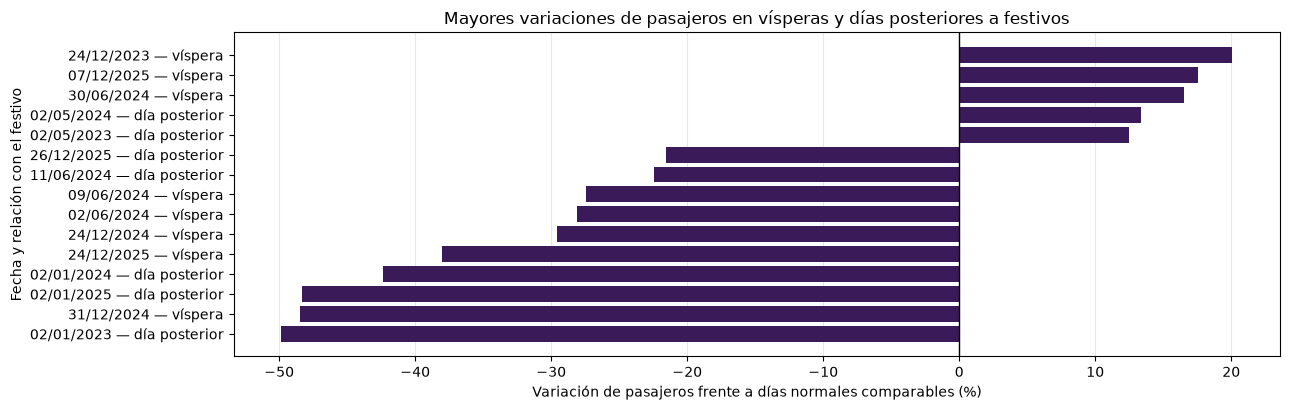

In [123]:
fest_fechas = dias_t.index[dias_t["tipo_dia"] == "festivo"] # extrae del índice de dias_t (que son fechas) aquellas cuyo tipo de día es "festivo".
filas = []

for f in fest_fechas:
    for desfase, nombre in [(-1, "víspera"), (1, "día posterior")]:
        d = f + pd.Timedelta(days=desfase)
        if d in dias_t.index and dias_t.loc[d, "tipo_dia"] != "festivo" and pd.isna(dias_t.loc[d, "evento"]):
            filas.append({"fecha": d, "relacion": nombre, "festivo": f})

vp = pd.DataFrame(filas).join(dias_t[["dia", "pax", "viajes"]], on="fecha")
vp["anio"] = vp["fecha"].dt.year

# referencia: días normales sin contar los propios vecinos
ref2 = (norm.drop(index=vp["fecha"].unique(), errors="ignore")
            .groupby(["anio", "dia"])
            .agg(ref_pax=("pax", "mean"), ref_viajes=("viajes", "mean")) # ¿cuánta demanda tiene un domingo normal de 2023?
            .reset_index())
vp = vp.merge(ref2, on=["anio", "dia"], how="left")
vp["efecto_pax"] = (vp["pax"] / vp["ref_pax"] - 1) * 100
vp["efecto_viajes"] = (vp["viajes"] / vp["ref_viajes"] - 1) * 100

res_vp = (vp.groupby("relacion")
            .agg(dias=("pax", "count"), efecto_pax=("efecto_pax", "mean"),
                 pax_min=("efecto_pax", "min"), pax_max=("efecto_pax", "max"),
                 efecto_viajes=("efecto_viajes", "mean"))
            .reset_index())



import matplotlib.pyplot as plt
import pandas as pd

# 10 fechas con mayores caídas
caidas = vp.nsmallest(10, "efecto_pax")

# 5 fechas con mayores aumentos
aumentos = vp.nlargest(5, "efecto_pax")

# Unir las fechas seleccionadas
graf_vp = (
    pd.concat([caidas, aumentos])
    .drop_duplicates(subset="fecha")
    .sort_values("efecto_pax")
    .copy()
)

# Etiqueta para identificar cada fecha y su relación con el festivo
graf_vp["etiqueta"] = (
    graf_vp["fecha"].dt.strftime("%d/%m/%Y")
    + " — "
    + graf_vp["relacion"]
)

# Crear el gráfico
fig, ax = plt.subplots(figsize=(13, 4.2))

colores = [
    "#3b1a5a" if efecto < 0 else "#3b1a5a"
    for efecto in graf_vp["efecto_pax"]
]

ax.barh(
    graf_vp["etiqueta"],
    graf_vp["efecto_pax"],
    color=colores
)

# Línea de referencia: ningún cambio frente al día normal comparable
ax.axvline(0, color="black", linewidth=1)

ax.set_title("Mayores variaciones de pasajeros en vísperas y días posteriores a festivos")
ax.set_xlabel("Variación de pasajeros frente a días normales comparables (%)")
ax.set_ylabel("Fecha y relación con el festivo")

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()


tabla_bonita(res_vp, {"relacion": "Relación con el festivo", "dias": "Días",
                      "efecto_pax": "Efecto en pasajeros: medio (%)", "pax_min": "mínimo (%)",
                      "pax_max": "máximo (%)", "efecto_viajes": "Efecto en viajes: medio (%)"},
             decimales=1)

# detalle día por día (son pocos)
vp["dia"] = vp["dia"].map({1: "lun", 2: "mar", 3: "mié", 4: "jue", 5: "vie", 6: "sáb", 7: "dom"})
tabla_bonita(vp[["fecha", "festivo", "relacion", "dia", "efecto_pax", "efecto_viajes"]]
             .assign(fecha=lambda x: x["fecha"].dt.strftime("%Y-%m-%d"),
                     festivo=lambda x: x["festivo"].dt.strftime("%Y-%m-%d")),
             {"fecha": "Fecha", "festivo": "Festivo vecino", "relacion": "Relación", "dia": "Día",
              "efecto_pax": "Pasajeros (%)", "efecto_viajes": "Viajes (%)"},
             decimales=1, alto="300px", ordenar=True)

En las vísperas y los días posteriores a los festivos se observa una disminución promedio de aproximadamente el 5 % en la cantidad de pasajeros y de viajes, en comparación con días normales equivalentes. Aunque esta reducción promedio es moderada, los valores extremos sugieren que existen fechas en las que la operación se ve mucho más afectada, con disminuciones de pasajeros cercanas al 50 %. Por lo tanto, es importante analizar estos casos particulares para identificar si corresponden a comportamientos propios de ciertos festivos o a otras circunstancias que influyen en la demanda.

In [101]:
vp.sort_values("efecto_pax", ascending=True)[["fecha", "relacion", "dia", "pax", "viajes", "ref_pax", "ref_viajes", "efecto_pax", "efecto_viajes"]]

fecha       relacion  dia      pax  viajes       ref_pax  ref_viajes  \
0  2023-01-02  día posterior  lun  13886.0     159  27689.628571  295.600000   
61 2024-12-31        víspera  mar  12975.0     167  25169.514286  275.400000   
62 2025-01-02  día posterior  jue  11741.0     148  22715.608696  260.478261   
32 2024-01-02  día posterior  mar  14515.0     174  25169.514286  275.400000   
89 2025-12-24        víspera  mié  13926.0     148  22460.152174  258.195652   
..        ...            ...  ...      ...     ...           ...         ...   
6  2023-05-02  día posterior  mar  31194.0     303  27738.722222  297.111111   
36 2024-05-02  día posterior  jue  27971.0     281  24677.382979  270.595745   
43 2024-06-30        víspera  dom  11831.0     172  10152.108108  164.243243   
87 2025-12-07        víspera  dom  10999.0     177   9358.135135  160.540541   
29 2023-12-24        víspera  dom  12923.0     146  10761.424242  166.333333   

    efecto_pax  efecto_viajes  
0   -49.851259     -46.211096  
61  -48.449542     -39.360930  
62  -48.313073     -43.181439  
32  -42.331029     -36.819172  
89  -37.996858     -42.679128  
..         ...            ...  
6    12.456514       1.982049  
36   13.346703       3.844944  
43   16.537372       4.722725  
87   17.534101      10.252525  
29   20.086335     -12.224449  

[91 rows x 9 columns]

Los valores extremos muestran un patrón de disminución de la demanda alrededor de las festividades de fin de año. El día posterior a Año Nuevo presenta una caída cercana al 50 % en la cantidad de pasajeros y de viajes en los tres años analizados, lo que sugiere un comportamiento recurrente que podría ser relevante para el modelo. Asimismo, las vísperas de Navidad presentan reducciones importantes tanto en pasajeros como en viajes, al igual que el día posterior a esta festividad. Estos resultados sugieren que el periodo de fin de año tiene un comportamiento particular en la operación de Sobusa, por lo que conviene evaluar la inclusión de variables específicas para estas fechas.

##### **Novedades viales**

In [125]:
nov = df_novedades_viales_fecha.copy()
nov["fecha"] = pd.to_datetime(nov["fecha"]) # pasamos la fecha a formato fecha

# 1) resumen general por tipo de novedad
resumen_nov = (nov.groupby("novedad") # agrupamos por novedad
    .agg(filas=("fecha", "size"), # dias en los que paso
         dias=("fecha", "nunique"), # fechas unicas
         desde=("fecha", "min"), # fecha minima
         hasta=("fecha", "max")) # fecha máxima
    .reset_index())
display(resumen_nov)

# 2) una fila por fecha
nov_agg = (nov.groupby("fecha") # agrupamos por fecha
    .agg(n_novedades=("novedad", "size"), # contamos número de novedades en esa fecha
         novedades=("novedad", lambda s: " | ".join(sorted(set(s.astype(str)))))) # juntamos dos fechas con | si coinciden
    .reset_index()
    .rename(columns={"fecha": "fecha_operativa"}))
nov_agg["fecha_operativa"] = pd.to_datetime(nov_agg["fecha_operativa"])

# 3) días con novedad vs referencia de día normal (mismo año y día de semana)
dt = dias_t.reset_index()
dt["fecha_operativa"] = pd.to_datetime(dt["fecha_operativa"])
nov_d = (dt.merge(nov_agg, on="fecha_operativa", how="inner")
           .merge(ref, on=["anio", "dia"], how="left"))
nov_d["efecto_pax"] = (nov_d["pax"] / nov_d["ref_pax"] - 1) * 100
nov_d["efecto_viajes"] = (nov_d["viajes"] / nov_d["ref_viajes"] - 1) * 100

# 4) separar días limpios (solo novedad) de los confundidos con calendario
nov_d["confundido"] = nov_d["evento"].notna() | (nov_d["tipo_dia"] == "festivo")
limpios = nov_d[~nov_d["confundido"]]

# 5) variabilidad normal: efecto de días normales contra su propia referencia
norm_e = norm.reset_index().merge(ref, on=["anio", "dia"], how="left")
norm_e["efecto_pax"] = (norm_e["pax"] / norm_e["ref_pax"] - 1) * 100
sd_normal = norm_e["efecto_pax"].std()
print(f"Días con novedad: {len(nov_d)} | limpios: {len(limpios)} | confundidos: {nov_d['confundido'].sum()}")
print(f"Desviación típica del efecto en días normales: {sd_normal:.1f}%  -> umbral ±{2*sd_normal:.1f}%")

limpios = limpios.assign(fuera_de_ruido=limpios["efecto_pax"].abs() > 2 * sd_normal)
print("Días limpios fuera del ruido normal:", int(limpios["fuera_de_ruido"].sum()))

cols = ["fecha_operativa", "tipo_dia", "evento", "novedades", "n_novedades",
        "pax", "viajes", "n_ref", "efecto_pax", "efecto_viajes", "confundido"]
display(nov_d[cols].sort_values("efecto_pax").round(1))

novedad  filas  dias      desde      hasta
0     BATALLA_FLORES      3     3 2023-02-18 2025-03-01
1           CARNAVAL     12    12 2023-02-18 2025-03-04
2          CONCIERTO      2     2 2025-02-20 2025-02-21
3          GUACHERNA      3     3 2023-02-10 2025-02-22
4  PARTIDO_SELECCION      8     8 2023-09-07 2025-06-06

Días con novedad: 25 | limpios: 12 | confundidos: 13
Desviación típica del efecto en días normales: 10.9%  -> umbral ±21.7%
Días limpios fuera del ruido normal: 0


fecha_operativa tipo_dia                                     evento  \
21      2025-03-03  laboral  Carnaval de Barranquilla - Días centrales   
22      2025-03-04  laboral  Carnaval de Barranquilla - Días centrales   
11      2024-02-12  laboral  Carnaval de Barranquilla - Días centrales   
12      2024-02-13  laboral  Carnaval de Barranquilla - Días centrales   
4       2023-02-21  laboral  Carnaval de Barranquilla - Días centrales   
3       2023-02-20  laboral  Carnaval de Barranquilla - Días centrales   
20      2025-03-02  domingo  Carnaval de Barranquilla - Días centrales   
6       2023-10-12  laboral                                        NaN   
19      2025-03-01   sabado  Carnaval de Barranquilla - Días centrales   
13      2024-09-10  laboral                                        NaN   
14      2024-10-15  laboral                                        NaN   
1       2023-02-18   sabado  Carnaval de Barranquilla - Días centrales   
24      2025-06-06  laboral                                        NaN   
2       2023-02-19  domingo  Carnaval de Barranquilla - Días centrales   
10      2024-02-11  domingo  Carnaval de Barranquilla - Días centrales   
5       2023-09-07  laboral                                        NaN   
15      2024-11-19  laboral                                        NaN   
9       2024-02-10   sabado  Carnaval de Barranquilla - Días centrales   
7       2023-11-16  laboral                                        NaN   
18      2025-02-22   sabado     Precarnaval y Carnaval de Barranquilla   
0       2023-02-10  laboral                                        NaN   
23      2025-03-25  laboral                                        NaN   
16      2025-02-20  laboral                                        NaN   
17      2025-02-21  laboral                                        NaN   
8       2024-02-02  laboral                                        NaN   

                    novedades  n_novedades      pax  viajes  n_ref  \
21                   CARNAVAL            1   6903.0      75     39   
22                   CARNAVAL            1   6961.0      68     49   
11                   CARNAVAL            1   8219.0      85     40   
12                   CARNAVAL            1   8357.0      89     49   
4                    CARNAVAL            1   9904.0      95     49   
3                    CARNAVAL            1  10805.0     134     36   
20                   CARNAVAL            1   7499.0      96     47   
6           PARTIDO_SELECCION            1  22410.0     279     49   
19  BATALLA_FLORES | CARNAVAL            2  16189.0     168     49   
13          PARTIDO_SELECCION            1  21626.0     229     49   
14          PARTIDO_SELECCION            1  22989.0     247     49   
1   BATALLA_FLORES | CARNAVAL            2  21161.0     240     49   
24          PARTIDO_SELECCION            1  21727.0     251     50   
2                    CARNAVAL            1  10451.0     156     47   
10                   CARNAVAL            1   9727.0     158     47   
5           PARTIDO_SELECCION            1  26758.0     298     49   
15          PARTIDO_SELECCION            1  24696.0     276     49   
9   BATALLA_FLORES | CARNAVAL            2  20517.0     263     48   
7           PARTIDO_SELECCION            1  28121.0     286     49   
18                  GUACHERNA            1  19767.0     226     49   
0                   GUACHERNA            1  29422.0     299     49   
23          PARTIDO_SELECCION            1  24941.0     247     49   
16                  CONCIERTO            1  24521.0     275     47   
17                  CONCIERTO            1  25396.0     269     50   
8                   GUACHERNA            1  27100.0     294     50   

    efecto_pax  efecto_viajes  confundido  
21       -70.1          -71.1        True  
22       -69.7          -73.8        True  
11       -67.0          -68.5        True  
12       -65.7          -66.4        True  
4        -64.3          -68.0        

Hay 28 registros de novedades en 25 días distintos, de cinco tipos: Carnaval (12), Partido de la Selección (8), Batalla de Flores (3), Guacherna (3) y Concierto (2). De esos 25 días, 13 coinciden con el calendario de Carnaval y no se pueden atribuir a la novedad. Los 12 días restantes, en los que la novedad ocurre sola, tienen un efecto de entre −17.3% y +11.8% sobre los pasajeros respecto de un día normal del mismo año y día de semana. La variabilidad habitual entre días normales es de 10.9% (desviación típica), lo que fija un umbral de ±21.7%. Ninguno de esos días lo supera. El Partido de la Selección (8 días) tiene efectos de signo mixto (−17.3% a +8.5%). Los efectos fuertes (−60% a −70%) corresponden a los lunes y martes de Carnaval y se explican por el calendario, no por la novedad.

Con los datos disponibles no se detecta efecto de las novedades viales, y no entran al modelo como variable. El tamaño de la muestra (12 días limpios) limita esta conclusión.

In [131]:
# ===== 6.x Efecto de festivos por tipo (vs día normal del mismo año y día de semana) =====
fest = (dias_t[dias_t["tipo_dia"] == "festivo"].reset_index()
        .merge(ref, on=["anio", "dia"], how="left"))
fest["efecto_pax"] = (fest["pax"] / fest["ref_pax"] - 1) * 100
fest["efecto_viajes"] = (fest["viajes"] / fest["ref_viajes"] - 1) * 100
fest["grupo"] = fest["evento"].fillna("Festivo sin evento asociado")

res_fest = (fest.groupby("grupo")
    .agg(dias=("pax", "count"),
         efecto_pax_medio=("efecto_pax", "mean"),
         efecto_pax_min=("efecto_pax", "min"),
         efecto_pax_max=("efecto_pax", "max"),
         efecto_viajes_medio=("efecto_viajes", "mean"),
         n_ref_min=("n_ref", "min"))
    .round(1).reset_index().sort_values("efecto_pax_medio"))
display(res_fest)

# Detalle día por día (útil para Semana Santa, Navidad y casos raros)
display(fest[["fecha_operativa", "dia", "grupo", "pax", "viajes", "efecto_pax", "efecto_viajes"]]
        .sort_values("fecha_operativa").round(1))

grupo  dias  efecto_pax_medio  \
2                                         Año Nuevo     3             -79.9   
14                                          Navidad     3             -75.5   
18                      Semana Santa; Viernes Santo     3             -74.3   
15                         Sagrado Corazón de Jesús     2             -67.8   
1                             Asunción de la Virgen     3             -65.1   
4                                    Corpus Christi     3             -65.1   
10                           Día de los Reyes Magos     3             -63.7   
0                               Ascensión del Señor     3             -63.5   
13                       Jueves Santo; Semana Santa     3             -63.2   
9                                    Día de la Raza     3             -62.6   
6                                   Día de San José     2             -61.8   
17                            San Pedro y San Pablo     2             -61.6   
7                     Día de San José; Semana Santa     1             -60.6   
19                                 Todos los Santos     3             -60.2   
11                       Independencia de Cartagena     3             -60.1   
16  Sagrado Corazón de Jesús; San Pedro y San Pablo     1             -60.0   
3                                 Batalla de Boyacá     3             -57.6   
5                                   Dia del trabajo     3             -56.5   
12                            Inmaculada Concepción     3             -51.4   
8               Día de la Independencia de Colombia     3             -29.8   

    efecto_pax_min  efecto_pax_max  efecto_viajes_medio  n_ref_min  
2            -90.3           -60.0                -83.5         40  
14           -76.8           -73.7                -64.7         36  
18           -76.7           -72.5                -46.6         49  
15           -71.6           -64.0                -47.5         36  
1            -68.2           -62.9                -46.7         36  
4            -66.1           -64.0                -41.0         36  
10           -64.4           -63.3                -41.1         36  
0            -65.1           -61.2                -44.5         36  
13           -65.8           -61.0                -36.8         47  
9            -64.6           -60.7                -44.3         36  
6            -62.3           -61.4                -37.4         36  
17           -62.5           -60.7                -48.9         36  
7            -60.6           -60.6                -34.1         40  
19           -60.5           -60.0                -39.1         36  
11           -60.8           -59.7                -41.1         36  
16           -60.0           -60.0                -43.0         39  
3            -63.4           -54.4                -35.2         36  
5            -60.9           -53.6                -39.4         36  
12           -70.1           -19.5                -39.2         39  
8            -61.6             4.6                -19.8         47

fecha_operativa  dia                                            grupo  \
0       2023-01-01    7                                        Año Nuevo   
1       2023-01-09    1                           Día de los Reyes Magos   
2       2023-03-20    1                                  Día de San José   
3       2023-04-06    4                       Jueves Santo; Semana Santa   
4       2023-04-07    5                      Semana Santa; Viernes Santo   
5       2023-05-01    1                                  Dia del trabajo   
6       2023-05-22    1                              Ascensión del Señor   
7       2023-06-12    1                                   Corpus Christi   
8       2023-06-19    1                         Sagrado Corazón de Jesús   
9       2023-07-03    1                            San Pedro y San Pablo   
10      2023-07-20    4              Día de la Independencia de Colombia   
11      2023-08-07    1                                Batalla de Boyacá   
12      2023-08-21    1                            Asunción de la Virgen   
13      2023-10-16    1                                   Día de la Raza   
14      2023-11-06    1                                 Todos los Santos   
15      2023-11-13    1                       Independencia de Cartagena   
16      2023-12-08    5                            Inmaculada Concepción   
17      2023-12-25    1                                          Navidad   
18      2024-01-01    1                                        Año Nuevo   
19      2024-01-08    1                           Día de los Reyes Magos   
20      2024-03-25    1                    Día de San José; Semana Santa   
21      2024-03-28    4                       Jueves Santo; Semana Santa   
22      2024-03-29    5                      Semana Santa; Viernes Santo   
23      2024-05-01    3                                  Dia del trabajo   
24      2024-05-13    1                              Ascensión del Señor   
25      2024-06-03    1                                   Corpus Christi   
26      2024-06-10    1                         Sagrado Corazón de Jesús   
27      2024-07-01    1                            San Pedro y San Pablo   
28      2024-07-20    6              Día de la Independencia de Colombia   
29      2024-08-07    3                                Batalla de Boyacá   
30      2024-08-19    1                            Asunción de la Virgen   
31      2024-10-14    1                                   Día de la Raza   
32      2024-11-04    1                                 Todos los Santos   
33      2024-11-11    1                       Independencia de Cartagena   
34      2024-12-08    7                            Inmaculada Concepción   
35      2024-12-25    3                                          Navidad   
36      2025-01-01    3                                        Año Nuevo   
37      2025-01-06    1                           Día de los Reyes Magos   
38      2025-03-24    1                                  Día de San José   
39      2025-04-17    4                       Jueves Santo; Semana Santa   
40      2025-04-18    5                      Semana Santa; Viernes Santo   
41      2025-05-01    4                                  Dia del trabajo   
42      2025-06-02    1                              Ascensión del Señor   
43      2025-06-23    1                                   Corpus Christi   
44      2025-06-30    1  Sagrado Corazón de Jesús; San Pedro y San Pablo   
45      2025-07-20    7              Día de la Independencia de Colombia   
46      2025-08-07    4                                Batalla de Boyacá   
47      2025-08-18    1                            Asunción de la Virgen   
48      2025-10-13    1                                   Día de la Raza   
49      2025-11-03    1                                 Todos los Santos   
50      2025-11-17    1                       Independencia de Cartagena   
51      2025-12-08    1                            

Los 53 festivos 2023–2025 coinciden con el calendario oficial. Un festivo reduce los pasajeros en promedio −64% frente a un día normal del mismo día de semana (mediana −63%, desviación típica 9%, n = 50), y su demanda queda cerca de la de un domingo normal (mediana −8%). Año Nuevo, Navidad y Viernes Santo caen de forma adicional por debajo de un domingo (Año Nuevo: −83% en viajes). Los lunes y martes de Carnaval, clasificados como laborales en el calendario, caen de −60% a −70%. Las novedades viales (28 filas, 5 tipos) no producen efecto fuera del ruido en días limpios (n = 12). Decisión: el modelo usa una única variable marca_calendario con cuatro niveles; las novedades viales no entran como variable.

In [138]:
print(fest[fest["dia"] == 7][["fecha_operativa", "grupo", "pax", "viajes", "efecto_pax"]].to_string())

   fecha_operativa                                grupo     pax  viajes  efecto_pax
0       2023-01-01                            Año Nuevo  4299.0      49  -59.996634
34      2024-12-08                Inmaculada Concepción  8019.0     131  -19.460252
45      2025-07-20  Día de la Independencia de Colombia  9719.0     178    4.644711


marca_calendario
normal              1037
festivo_comun         44
festivo_profundo       9
carnaval_lun_mar       6
Name: count, dtype: int64


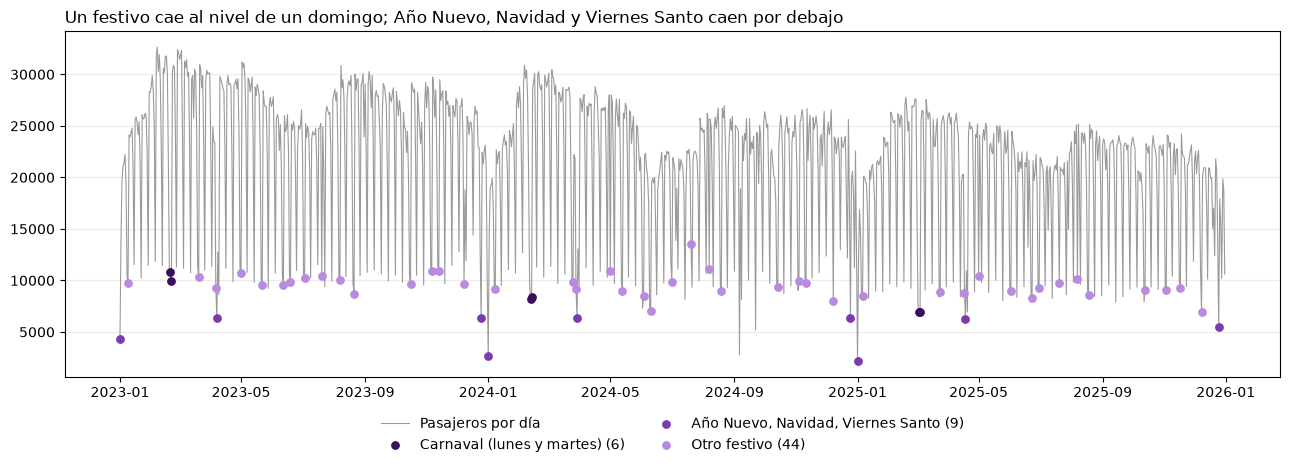

In [143]:
# ===== 6.x Calendario anotado + variable marca_calendario =====
import matplotlib.pyplot as plt

cal = dias_t.copy()
cal.index = pd.to_datetime(cal.index)

es_fest = cal["tipo_dia"] == "festivo"
es_prof = es_fest & cal["evento"].fillna("").str.contains("Año Nuevo|Navidad|Viernes Santo")
es_carn = (cal["evento"].fillna("").str.contains("Días centrales")) & cal["dia"].isin([1, 2])

cal["marca_calendario"] = "normal"
cal.loc[es_fest, "marca_calendario"] = "festivo_comun"
cal.loc[es_prof, "marca_calendario"] = "festivo_profundo"
cal.loc[es_carn, "marca_calendario"] = "carnaval_lun_mar"   # tiene prioridad máxima
print(cal["marca_calendario"].value_counts())

colores = {"carnaval_lun_mar": "#3B0F5C", "festivo_profundo": "#7B3BAF", "festivo_comun": "#B98AE0"}
etiquetas = {"carnaval_lun_mar": "Carnaval (lunes y martes)",
             "festivo_profundo": "Año Nuevo, Navidad, Viernes Santo",
             "festivo_comun": "Otro festivo"}

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(cal.index, cal["pax"], color="#9a9a9a", lw=0.8, label="Pasajeros por día")
for k, c in colores.items():
    sub = cal[cal["marca_calendario"] == k]
    ax.scatter(sub.index, sub["pax"], color=c, s=28, zorder=3, label=f"{etiquetas[k]} ({len(sub)})")
ax.set_title("Un festivo cae al nivel de un domingo; Año Nuevo, Navidad y Viernes Santo caen por debajo",
             loc="left", fontsize=12)
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

La serie gris muestra los pasajeros por día en viajes aptos para demanda. El patrón semanal es muy marcado: los días laborales se ubican entre 22,000 y 32,000 pasajeros y los domingos caen cerca de 10,000. Los puntos morado clar (44 festivos comunes) se ubican entre 8,000 y 10,000, es decir, al nivel de un domingo normal, no por debajo. Los puntos morado (9 días: Año Nuevo, Navidad y Viernes Santo) caen más, entre 2,200 y 6,400 pasajeros. Los lunes y martes de Carnaval (6 días, en morado oscuro) quedan entre 6,900 y 10,800, también al nivel de un domingo o por debajo. Se observan además dos caídas profundas a mediados de 2024 que no corresponden a ninguna marca del calendario (una cercana a 2,800 pasajeros), pendientes de revisar. Los máximos de los días laborales bajan con el tiempo: unos 32,000 a principios de 2023, 31,000 a inicios de 2024 y 27,500 a inicios de 2025, con un escalón hacia abajo en la segunda mitad de 2024. Lectura para el modelo: el calendario aporta información (festivos, Año Nuevo/Navidad/Viernes Santo y Carnaval lunes-martes), pero el nivel general de la demanda no es estable entre años, por lo que la validación debe ser cronológica y las referencias deben calcularse por año.

In [145]:
c = cal.copy()
c.index.name = "fecha_operativa"
c = c.reset_index().merge(ref, on=["anio", "dia"], how="left")
c["efecto_pax"] = (c["pax"] / c["ref_pax"] - 1) * 100
c["efecto_viajes"] = (c["viajes"] / c["ref_viajes"] - 1) * 100

raros = c[(c["marca_calendario"] == "normal") & (c["efecto_pax"] < -3 * sd_normal)]
print(len(raros), "días normales con caída mayor a tres desviaciones típicas")
display(raros[["fecha_operativa", "dia", "evento", "pax", "viajes", "ref_pax",
               "efecto_pax", "efecto_viajes"]].sort_values("efecto_pax").round(1))

16 días normales con caída mayor a tres desviaciones típicas


fecha_operativa  dia        evento      pax  viajes  ref_pax  efecto_pax  \
614       2024-09-06    5           NaN   2779.0      19  24237.2       -88.5   
1095      2025-12-31    3           NaN  10618.0     127  22395.1       -52.6   
1         2023-01-02    1           NaN  13886.0     159  27306.2       -49.1   
630       2024-09-22    7           NaN   5189.0      97   9956.6       -47.9   
732       2025-01-02    4           NaN  11741.0     148  22482.1       -47.8   
730       2024-12-31    2           NaN  12975.0     167  24366.4       -46.8   
97        2023-04-08    6  Semana Santa  12773.0     180  22370.9       -42.9   
551       2024-07-05    5           NaN  13874.0     178  24237.2       -42.8   
900       2025-06-19    4           NaN  13220.0     194  22482.1       -41.2   
839       2025-04-19    6  Semana Santa  10923.0     150  18508.6       -41.0   
366       2024-01-02    2           NaN  14515.0     174  24366.4       -40.4   
1088      2025-12-24    3           NaN  13926.0     148  22395.1       -37.8   
940       2025-07-29    2           NaN  14939.0     184  22984.1       -35.0   
454       2024-03-30    6  Semana Santa  13063.0     177  20062.5       -34.9   
1083      2025-12-19    5           NaN  15034.0     166  22826.4       -34.1   
920       2025-07-09    3           NaN  14887.0     209  22395.1       -33.5   

      efecto_viajes  
614           -92.8  
1095          -50.5  
1             -45.5  
630           -40.3  
732           -42.7  
730           -36.9  
97            -34.2  
551           -32.2  
900           -24.8  
839           -35.8  
366           -34.3  
1088          -42.3  
940           -29.2  
454           -27.8  
1083          -36.0  
920           -18.5

De 1,037 días sin marca de calendario, 16 (1.5%) presentan una caída de pasajeros superior a tres desviaciones típicas (−33%) frente a su referencia. Seis corresponden al período 24-dic a 2-ene (2023-01-02, 2024-01-02, 2025-01-02, 2024-12-31, 2025-12-24 y 2025-12-31); tres, al Sábado Santo de cada año (−35% a −43%); dos, a días de servicio muy reducido (2024-09-06 con 19 viajes y 2024-09-22 con 97 viajes), de causa desconocida; y cinco a días aislados (cuatro entre junio y julio) sin explicación. 

Decisión: la marca de calendario incorpora Sábado Santo y una ventana de fin de año; los días 2024-09-06 y 2024-09-22 se marcan como dia_anomalo (sin eliminar ni imputar) a la espera de la respuesta de Extreme.

#### **Ciclo y flota**

##### **Duración del viaje**

2023: 1 valores fuera del rango (60, 480) no se dibujan
2024: 5 valores fuera del rango (60, 480) no se dibujan


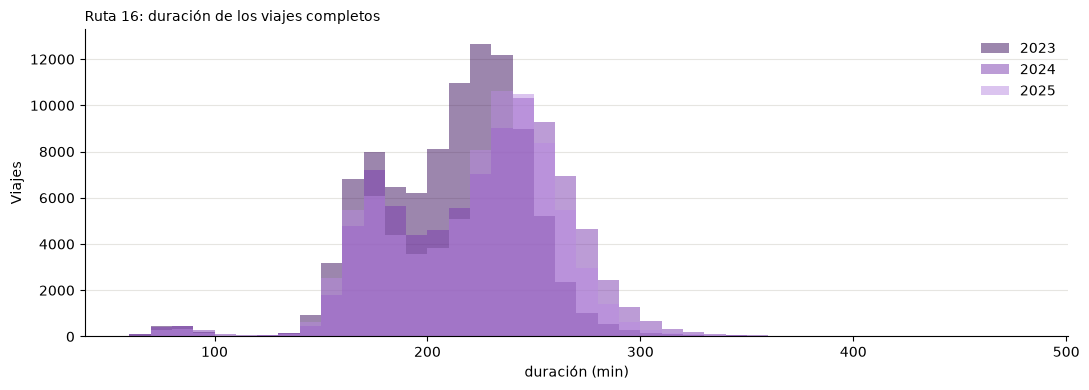

In [42]:

ok = compl[compl["dur_min"].notna() & ~compl["dur_fuera_rango"]]
rd = ok.groupby("anio")["dur_min"].describe(percentiles=[.05, .1, .5, .9, .95])
rd["asimetria"] = ok.groupby("anio")["dur_min"].skew()
rd["fuera"] = compl.groupby("anio")["dur_fuera_rango"].sum()
tabla_bonita(rd.rename_axis("Año"), {"count": "Viajes", "mean": "Media", "std": "Desv. estándar", "min": "Mínimo", "5%": "P5", "10%": "P10", "50%": "Mediana", "90%": "P90", "95%": "P95", "max": "Máximo", "asimetria": "Asimetría", "fuera": "Fuera de rango (<60 o >480)"}, miles=["Viajes"], como_texto=["Año"], decimales=1)
hist_por_grupo(ok, "dur_min", "anio", {2023: "#3B0F5C", 2024: "#7B3BAF", 2025: "#B98AE0"}, rango=(60, 480), bins=42, titulo="Ruta 16: duración de los viajes completos", xlabel="duración (min)")


##### **Pasajeros frente a intervalo de despacho**

Spearman pasajeros vs intervalo (todos): -0.03
bloque
Hasta las 7:59       0.139
8:00 a 14:59         0.007
15:00 en adelante   -0.012
Name: Spearman por bloque horario, dtype: float64


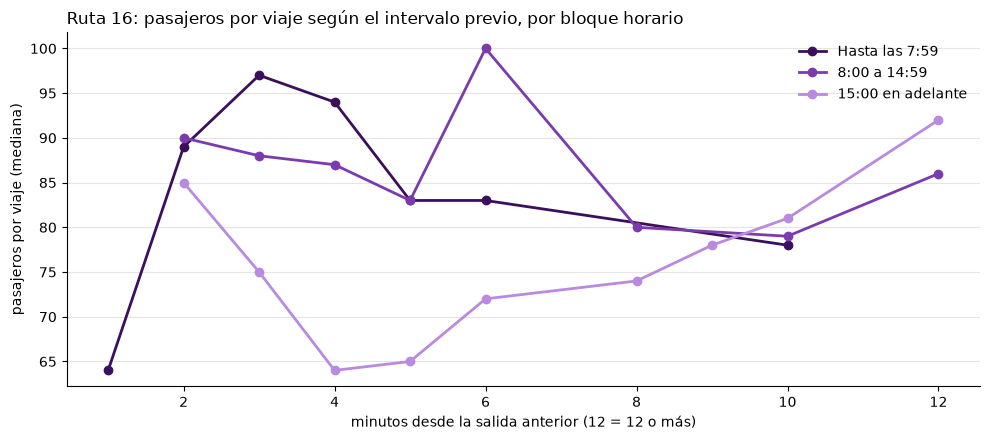

In [146]:
b = ai[ai["apto_demanda"] & ai["interv"].notna()].copy()
b["interv_c"] = b["interv"].clip(upper=12).round().astype(int)          # 12 = "12 o más"
b["hora"] = b["fechasalida"].dt.hour
b["bloque"] = pd.cut(b["hora"], [0, 8, 15, 24], right=False,
                     labels=["Hasta las 7:59", "8:00 a 14:59", "15:00 en adelante"])

print("Spearman pasajeros vs intervalo (todos):", round(b["numeropasajeros"].corr(b["interv"], method="spearman"), 3))
print(b.groupby("bloque", observed=True).apply(lambda g: round(g["numeropasajeros"].corr(g["interv"], method="spearman"), 3)).rename("Spearman por bloque horario"))

colores_bloque = {"Hasta las 7:59": "#3B0F5C", "8:00 a 14:59": "#7B3BAF", "15:00 en adelante": "#B98AE0"}
fig, ax = plt.subplots(figsize=(10, 4.5))
for blq, g in b.groupby("bloque", observed=True):
    ta = g.groupby("interv_c")["numeropasajeros"].agg(mediana="median", n="size")
    ta = ta[ta["n"] >= 500]                                              # solo grupos con al menos 500 viajes
    ax.plot(ta.index, ta["mediana"], marker="o", color=colores_bloque[blq], label=str(blq), linewidth=2)
ax.set_xlabel("minutos desde la salida anterior (12 = 12 o más)"); ax.set_ylabel("pasajeros por viaje (mediana)")
ax.set_title("Ruta 16: pasajeros por viaje según el intervalo previo, por bloque horario", loc="left")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

tn = b.groupby(["bloque", "interv_c"], observed=True).size().unstack(0)
tabla_bonita(tn.rename_axis("Intervalo (min)"), miles=list(tn.columns), como_texto=["Intervalo (min)"], decimales=0)

Sobre 269,975 viajes aptos para demanda, se comparó la mediana de pasajeros por viaje con el intervalo respecto a la salida anterior, por bloque horario (el 89.4% de los viajes tiene intervalos de 2 a 6 minutos; solo se grafican puntos con al menos 500 viajes). La correlación de Spearman es prácticamente nula: −0.03 en total y entre −0.01 y 0.14 por bloque horario, por lo que el intervalo explica muy poco de la variación de los pasajeros por viaje. Los patrones en las medianas son parciales: en la tarde (desde las 15:00) la mediana aumenta de 64 pasajeros a 4 minutos a 92 a 12 minutos o más, pero con un aumento (1.4 veces) menor que el del intervalo (3 veces); antes de las 8:00 los intervalos de 1 minuto (10,621 viajes) tienen una mediana de 64, menor que la de 2 a 4 minutos (89 a 97); y entre las 8:00 y las 14:59 la mediana es casi constante. Las diferencias entre bloques horarios son mayores que las asociadas al intervalo. A nivel de viaje, el intervalo de despacho no sería un buen predictor de los pasajeros del recorrido; la demanda parece depender más de la hora y el día. Es una asociación y no una causa, y los pasajeros por viaje corresponden al recorrido completo y no a una franja (H20).

##### **Pasajeros frente a duración**

Spearman pasajeros vs duración: 0.515


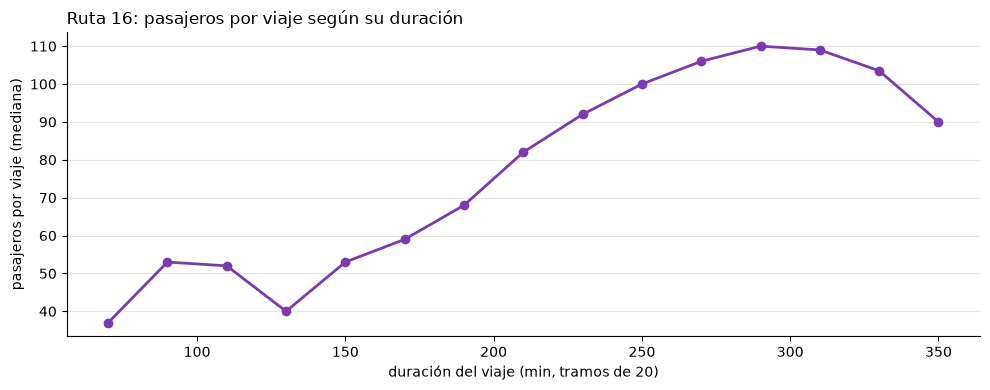

In [147]:
c = compl[compl["apto_demanda"] & compl["dur_min"].between(60, 480)].copy()
c["dur_bin"] = (c["dur_min"] // 20 * 20).astype(int)
print("Spearman pasajeros vs duración:", round(c["numeropasajeros"].corr(c["dur_min"], method="spearman"), 3))

tdur = c.groupby("dur_bin")["numeropasajeros"].agg(mediana="median", n="size")
tdur_ok = tdur[tdur["n"] >= 200]                                         # se dibujan solo tramos con al menos 200 viajes

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tdur_ok.index + 10, tdur_ok["mediana"], marker="o", color="#7B3BAF", linewidth=2)
ax.set_xlabel("duración del viaje (min, tramos de 20)"); ax.set_ylabel("pasajeros por viaje (mediana)")
ax.set_title("Ruta 16: pasajeros por viaje según su duración", loc="left")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# la tabla muestra TODOS los tramos, incluso los que no se dibujan
tdur_v = tdur.copy()
tdur_v.index = [f"{i} a {i+19}" for i in tdur_v.index]
tabla_bonita(tdur_v.rename_axis("Tramo de duración (min)"),
             {"mediana": "Mediana de pasajeros", "n": "Viajes"},
             miles=["Viajes"], como_texto=["Tramo de duración (min)"], decimales=0)

Sobre 265,937 viajes aptos para demanda con duración entre 60 y 480 minutos, la mediana de pasajeros crece con la duración: de 53 (tramo de 140 a 159 minutos) a 110 (280 a 299 minutos), y desciende después (90 en 340 a 359). El 91% de los viajes (242,543) está entre 160 y 279 minutos, donde la mediana pasa de 59 a 106 pasajeros. Los tramos de menos de 140 minutos (1.5% de los viajes) y de más de 340 (0.4%) tienen medianas inestables por su tamaño y no se interpretan. Un viaje más largo recoge más pasajeros porque recorre y se detiene más tiempo, y la duración también coincide con horas de mayor demanda y tráfico. Como la duración solo se conoce al terminar el viaje, no puede ser variable de entrada del modelo (fuga de información); solo sería utilizable como duración histórica por hora y día.

##### **Cancelación frente a la hora de salida**

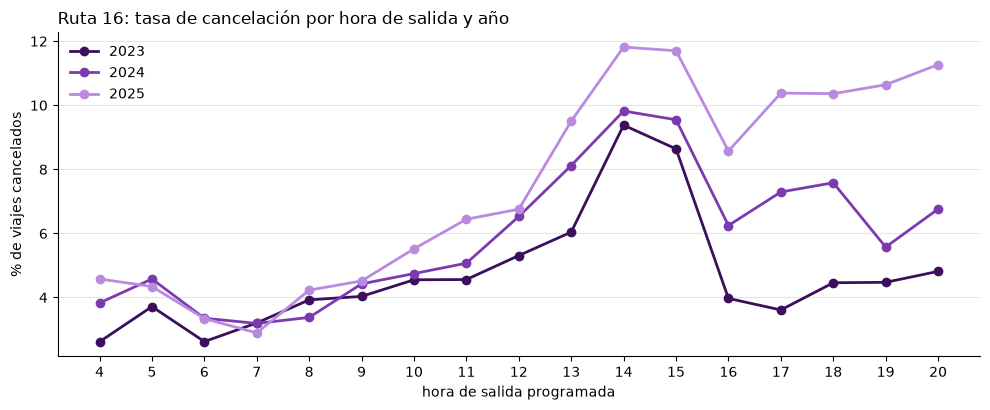

In [148]:
x = d16.copy()
x["hora"] = x["fechasalida"].dt.hour
x["cancelado"] = (x["estado_viaje"] == "cancelado")

# Tabla: todos los años juntos, solo horas con al menos 500 viajes
t = x.groupby("hora")["cancelado"].agg(Viajes="size", Cancelados="sum")
t["% cancelados"] = t["Cancelados"] / t["Viajes"] * 100
t = t[t["Viajes"] >= 500]
tabla_bonita(t.rename_axis("Hora de salida"), miles=["Viajes", "Cancelados"], decimales=1)

# Gráfico: % de cancelados por hora, una línea por año
COL_ANIO = {2023: "#3B0F5C", 2024: "#7B3BAF", 2025: "#B98AE0"}
ta = x.groupby(["anio", "hora"])["cancelado"].agg(n="size", c="sum")
ta["pct"] = ta["c"] / ta["n"] * 100
ta = ta[ta["n"] >= 500]

fig, ax = plt.subplots(figsize=(10, 4.2))
for a, g in ta.groupby(level=0):
    ax.plot(g.index.get_level_values(1), g["pct"], marker="o", color=COL_ANIO[a], label=str(a), linewidth=2)
ax.set_xticks(sorted(ta.index.get_level_values(1).unique()))
ax.set_xlabel("hora de salida programada"); ax.set_ylabel("% de viajes cancelados")
ax.set_title("Ruta 16: tasa de cancelación por hora de salida y año", loc="left")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Sobre los viajes programados de la ruta 16, la tasa de cancelación depende de la hora de salida: es baja en la mañana (3.1% a 4.9% entre las 4 y las 10 h), alcanza su máximo a las 14 h (10.3%; 9.9% a las 15 h) y se mantiene entre 6.2% y 7.8% desde las 16 h. El máximo entre las 13 y las 15 h se repite en los tres años (a las 14 h: 9.4% en 2023, 9.8% en 2024 y 11.8% en 2025). El aumento entre 2023 y 2025 se concentra en la tarde y la noche: de 16 a 20 h pasa de 3.6%-4.8% a 8.6%-11.3%, mientras que de 4 a 9 h los tres años son similares. Como casi todas las cancelaciones son automáticas (44,150 de 44,156 en las tres rutas), el patrón podría reflejar viajes que el sistema cierra por falta de bus disponible después de la ola de la mañana, lo que se relaciona con ciclo y flota (sección 8). Confirmar con Extreme el significado de “cancelada automáticamente”.

##### **Subidas frente a bajadas**

Viajes comparados: 271,058 | Spearman pasajeros vs bajadas: 0.974


Viajes con 0 bajadas y más de 20 pasajeros: 80 (0.03% de 271,058)
idvehiculo
SOBUSA416    32
SOBUSA490     9
SOBUSA60      7
SOBUSA238     5
SOBUSA159     2
SOBUSA176     2
SOBUSA182     2
SOBUSA205     2
SOBUSA217     2
SOBUSA339     2
Name: count, dtype: int64


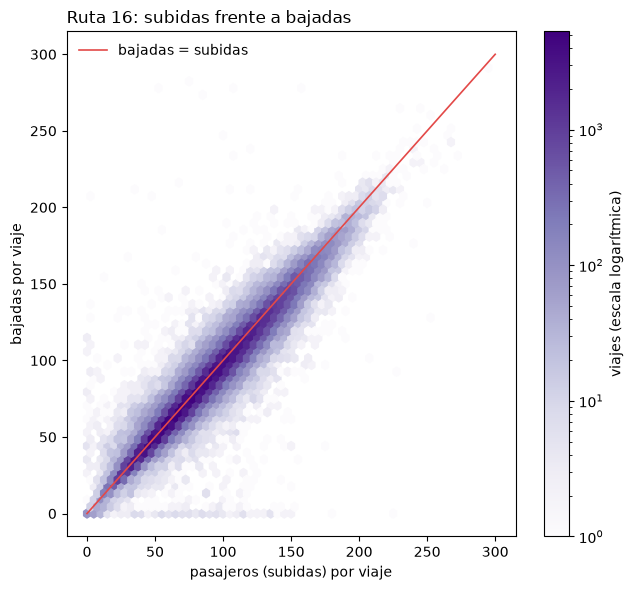

In [149]:
y = d16[d16["apto_demanda"] & d16["numerobajadas"].notna() & (d16["numerobajadas"] <= 500)].copy()
y["dif"] = y["numerobajadas"] - y["numeropasajeros"]
y["razon"] = y["numerobajadas"] / y["numeropasajeros"].replace(0, np.nan)

print(f"Viajes comparados: {len(y):,} | Spearman pasajeros vs bajadas:",
      round(y["numeropasajeros"].corr(y["numerobajadas"], method="spearman"), 3))

res = pd.DataFrame({
    "Concepto": ["Bajadas mayores que subidas", "Bajadas iguales a subidas", "Bajadas menores que subidas",
                 "Diferencia dentro de ±5% de las subidas"],
    "Viajes": [(y["dif"] > 0).sum(), (y["dif"] == 0).sum(), (y["dif"] < 0).sum(),
               ((y["dif"].abs() / y["numeropasajeros"]) <= 0.05).sum()]})
res["% de los viajes"] = res["Viajes"] / len(y) * 100
tabla_bonita(res, miles=["Viajes"], decimales=1)

q = y["razon"].quantile([.01, .05, .25, .5, .75, .95, .99]).rename("Bajadas / subidas").to_frame().T
q.columns = ["P1", "P5", "P25", "Mediana", "P75", "P95", "P99"]
tabla_bonita(q, decimales=2)

cero = y[(y["numerobajadas"] == 0) & (y["numeropasajeros"] > 20)]
print(f"Viajes con 0 bajadas y más de 20 pasajeros: {len(cero):,} ({len(cero)/len(y)*100:.2f}% de {len(y):,})")
print(cero["idvehiculo"].value_counts().head(10))   # ¿se concentran en pocos buses?

fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(y["numeropasajeros"], y["numerobajadas"], gridsize=60, extent=(0, 300, 0, 300),
               mincnt=1, bins="log", cmap="Purples")
ax.plot([0, 300], [0, 300], color="#e34948", linewidth=1.2, label="bajadas = subidas")
fig.colorbar(hb, ax=ax, label="viajes (escala logarítmica)")
ax.set_xlabel("pasajeros (subidas) por viaje"); ax.set_ylabel("bajadas por viaje")
ax.set_title("Ruta 16: subidas frente a bajadas", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

En 271,058 viajes aptos para demanda con bajadas registradas (excluidos 8 con más de 500), las subidas y las bajadas están muy correlacionadas (Spearman = 0.974). La razón bajadas/subidas tiene mediana de 0.98, con el 90% central entre 0.86 y 1.13 (P1 = 0.76; P99 = 1.32), y el 54.7% de los viajes difiere en menos del 5%. Las bajadas son menores que las subidas en el 57.5% de los viajes, mayores en el 34.1% e iguales en el 8.4%, lo que indica un leve subregistro de bajadas. El diagrama muestra además viajes con cero bajadas y pasajeros positivos [N casos, completar con la celda de arriba], que sugieren fallas de registro. Esta concordancia permite usar las bajadas como control de calidad de las subidas, pero no resuelve la carga a bordo, que requeriría conteos por segmento (no disponibles).

##### **Autocorrelación de la serie diaria**

Días en la serie: 1096 | días sin dato: 0


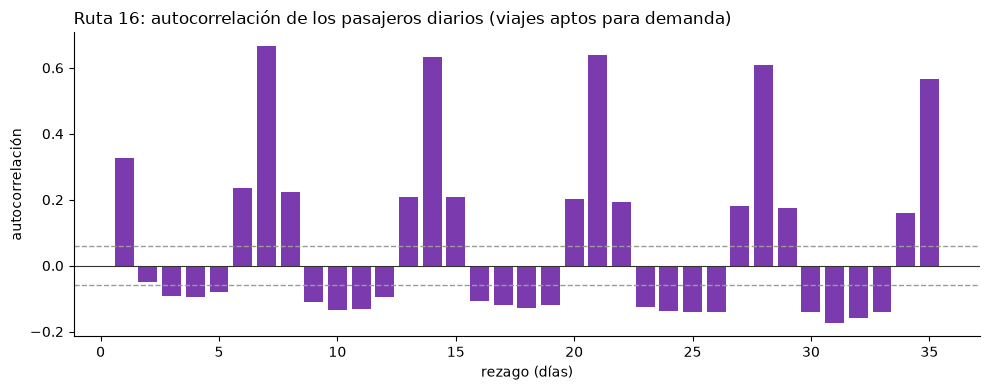

In [150]:
b0 = d16[d16["apto_demanda"]]
diario = pd.DataFrame({
    "Viajes completos por día": compl.groupby("fecha_operativa").size(),
    "Pasajeros por día": b0.groupby("fecha_operativa")["numeropasajeros"].sum(),
})
diario = diario.reindex(pd.date_range(diario.index.min(), diario.index.max()))
print("Días en la serie:", len(diario), "| días sin dato:", int(diario["Pasajeros por día"].isna().sum()))

lags = [1, 2, 3, 7, 14, 21, 28, 365]
acf = pd.DataFrame({c: [diario[c].autocorr(l) for l in lags] for c in diario.columns}, index=lags)
acf.index.name = "Rezago (días)"
tabla_bonita(acf, decimales=2)

s = diario["Pasajeros por día"]
vals = [s.autocorr(l) for l in range(1, 36)]
lim = 1.96 / np.sqrt(s.notna().sum())          # banda aproximada de significancia (±1.96/√n)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, 36), vals, color="#7B3BAF")
ax.axhline(lim, color="#9a9a9a", linestyle="--", linewidth=1); ax.axhline(-lim, color="#9a9a9a", linestyle="--", linewidth=1)
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("rezago (días)"); ax.set_ylabel("autocorrelación")
ax.set_title("Ruta 16: autocorrelación de los pasajeros diarios (viajes aptos para demanda)", loc="left")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

La serie diaria de pasajeros de la ruta 16 (1,096 días) tiene una fuerte estacionalidad semanal: la autocorrelación es máxima en los rezagos 7, 14, 21 y 28 (0.67, 0.63, 0.64 y 0.61) y negativa entre los múltiplos de 7 (hasta −0.17), todos fuera de la banda de ±0.06. El rezago 1 es de 0.33, y los rezagos 2 y 3 son cercanos a cero (−0.05 y −0.09). La serie de viajes completos por día se comporta de forma similar (rezago 7 = 0.59). La autocorrelación anual (rezago 365) es débil (0.22) y se calcula con solo tres años. Los picos semanales decaen lentamente (de 0.67 a 0.57 en el rezago 35), lo que sugiere además un componente de nivel o tendencia. El día de la semana y el rezago de 7 días serían predictores obligados. Quedan pendientes la autocorrelación parcial, las pruebas ADF y KPSS y la descomposición de la sección 10. Los pasajeros diarios se suman por fecha de salida, no por la de abordaje (H20).